03_ViT_Evaluation.ipynb

Load trained ViT models Evaluate on fixed test set Generate metrics Confusion matrix Prediction analysis Confidence analysis ROC analysis Benchmark summary Export results

In [1]:
# ============================================================
# STEP 1 : IMPORT LIBRARIES
# ============================================================

# ----------------------------
# Deep Learning
# ----------------------------
from fastai.vision.all import *
from fastai.losses import LabelSmoothingCrossEntropy

import torch
import torch.nn as nn
import torchvision
import timm

# ----------------------------
# TorchVision Models
# ----------------------------
from torchvision.models import (
    resnet50,
    densenet121,
    mobilenet_v3_large,
    efficientnet_b0,
    efficientnet_b1,
    vit_b_16,
)

# ----------------------------
# Evaluation Metrics
# ----------------------------
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    auc,
    precision_recall_curve,
)

# ----------------------------
# Statistical Analysis
# ----------------------------
from scipy import stats

# ----------------------------
# Data Handling
# ----------------------------
import pandas as pd
import numpy as np

# ----------------------------
# Plotting
# ----------------------------
import matplotlib.pyplot as plt
import seaborn as sns

# ----------------------------
# System Utilities
# ----------------------------
import os
import shutil
import json
import random
import platform
import time

from pathlib import Path
from datetime import datetime

# ----------------------------
# Ignore Warnings
# ----------------------------
import warnings
warnings.filterwarnings("ignore")

In [2]:
# ============================================================
# SECTION 2 : GLOBAL CONFIGURATION
# ============================================================

from pathlib import Path
from datetime import datetime

# ============================================================
# PROJECT INFORMATION
# ============================================================

PROJECT_NAME = "Vision Transformer Benchmark"

PROJECT_VERSION = "Version 1.0"

NOTEBOOK = "03_VisionTransformer.ipynb"

AUTHOR = "Rahul Bailwal"

DATE = datetime.now().strftime("%d-%m-%Y")

# ============================================================
# DATASET PATHS
# ============================================================

# Main Dataset (8-bit Normalized Grayscale)
GRAY_DATASET_PATH = Path(
    r"C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Sedimentary Structure 8Bit N"
)

# Original RGB Dataset (Reserved for future comparison)
RGB_DATASET_PATH = Path(
    r"C:\Users\Frontech\Desktop\Codes\Combined Data set\Test3\Sedimentary Structure"
)

# Active Dataset
ACTIVE_DATASET = GRAY_DATASET_PATH

# Fixed Independent Test Dataset
TEST_DATASET_PATH = Path(
    r"C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Fixed_Split\Test"
)

# ============================================================
# Project Directories
# --------------------------------------------------------

PROJECT_DIR = Path(
    r"C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results"
)

MODELS_DIR = PROJECT_DIR / "Saved_Models"

EVALUATION_DIR = PROJECT_DIR / "Evaluation"

METRICS_DIR = EVALUATION_DIR / "Metrics"

PREDICTIONS_DIR = EVALUATION_DIR / "Predictions"

CONFUSION_MATRIX_DIR = EVALUATION_DIR / "Confusion_Matrix"

ROC_DIR = EVALUATION_DIR / "ROC"

FIGURES_DIR = EVALUATION_DIR / "Figures"

BENCHMARK_DIR = PROJECT_DIR / "Benchmark"

LOGS_DIR = PROJECT_DIR / "Logs"

for folder in [
    MODELS_DIR,
    EVALUATION_DIR,
    METRICS_DIR,
    PREDICTIONS_DIR,
    CONFUSION_MATRIX_DIR,
    ROC_DIR,
    FIGURES_DIR,
    BENCHMARK_DIR,
    LOGS_DIR,
]:
    folder.mkdir(parents=True, exist_ok=True)


TRAINING_REQUIRED = False

# ============================================================
# CLASS INFORMATION
# ============================================================

CLASSES = [
    "BSS",
    "CL",
    "FS",
    "HBCS",
    "HCS",
    "PCS",
    "PL",
    "RM",
    "TCS",
]

NUM_CLASSES = len(CLASSES)

# ============================================================
# BENCHMARK SETTINGS
# ============================================================

# Five independent benchmark runs
RUN_SEEDS = [42, 123, 777, 2025, 999]
NUM_RUNS = len(RUN_SEEDS)
TOTAL_EVALUATIONS = 0
MODEL_EXTENSION = ".pth"

# ============================================================
# SAVE OPTIONS
# ============================================================

SAVE_METRICS = True
SAVE_PREDICTIONS = True
SAVE_CONFUSION_MATRIX = True
SAVE_ROC = True
SAVE_PR_CURVE = True
SAVE_MISCLASSIFIED = True
SAVE_BENCHMARK = True

# ============================================================
# DEVICE
# ============================================================

DEVICE = default_device()

# ============================================================
# CONFIGURATION SUMMARY
# ============================================================

print("=" * 70)
print(f"Project            : {PROJECT_NAME} v{PROJECT_VERSION}")
print(f"Notebook           : {NOTEBOOK}")
print(f"Author             : {AUTHOR}")
print(f"Date               : {DATE}")
print("-" * 70)
print(f"Active Dataset     : {ACTIVE_DATASET}")
print(f"Test Dataset       : {TEST_DATASET_PATH}")
print(f"Benchmark Type     : Vision Transformer")
print(f"Training Required  : {TRAINING_REQUIRED}")
print(f"Model Extension    : {MODEL_EXTENSION}")
print(f"Evaluation Folder  : {EVALUATION_DIR}")
print(f"Number of Classes  : {NUM_CLASSES}")
print(f"Benchmark Runs     : {NUM_RUNS}")
print(f"Device             : {DEVICE}")
print("=" * 70)

Project            : Vision Transformer Benchmark vVersion 1.0
Notebook           : 03_VisionTransformer.ipynb
Author             : Rahul Bailwal
Date               : 29-07-2026
----------------------------------------------------------------------
Active Dataset     : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Sedimentary Structure 8Bit N
Test Dataset       : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Fixed_Split\Test
Benchmark Type     : Vision Transformer
Training Required  : False
Model Extension    : .pth
Evaluation Folder  : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation
Number of Classes  : 9
Benchmark Runs     : 5
Device             : cpu


In [3]:
# ============================================================
# SECTION 3 : VISION TRANSFORMER MODEL CONFIGURATION
# ============================================================

print("=" * 80)
print("SECTION 3 : VISION TRANSFORMER MODEL CONFIGURATION")
print("=" * 80)

# ------------------------------------------------------------
# Vision Transformer Models
# ------------------------------------------------------------

MODELS = {

    "DeiT_Small": {

        "architecture": "deit_small_patch16_224",

        "image_size": 224,

        "weights": "ImageNet-1K",

        "description": "Data-efficient Image Transformer (Small)"

    },

    "Swin_Tiny": {

        "architecture": "swin_tiny_patch4_window7_224",

        "image_size": 224,

        "weights": "ImageNet-1K",

        "description": "Shifted Window Vision Transformer (Tiny)"

    },

    "ViT_Base": {

        "architecture": "vit_base_patch16_224",

        "image_size": 224,

        "weights": "ImageNet-1K",

        "description": "Vision Transformer Base"

    }

}

# ------------------------------------------------------------
# Benchmark Information
# ------------------------------------------------------------

MODEL_LIST = list(MODELS.keys())

NUM_MODELS = len(MODEL_LIST)

TOTAL_EVALUATIONS = NUM_MODELS * NUM_RUNS

# ------------------------------------------------------------
# Display Configuration
# ------------------------------------------------------------

print(f"\nNumber of Models      : {NUM_MODELS}")
print(f"Benchmark Runs        : {NUM_RUNS}")
print(f"Total Evaluations     : {TOTAL_EVALUATIONS}")

print("\nConfigured Vision Transformer Models")
print("-" * 80)

for i, model in enumerate(MODEL_LIST, start=1):

    print(f"{i}. {model}")

    print(f"   Architecture : {MODELS[model]['architecture']}")

    print(f"   Image Size   : {MODELS[model]['image_size']}")

    print(f"   Weights      : {MODELS[model]['weights']}")

    print(f"   Description  : {MODELS[model]['description']}")

    print()

print("=" * 80)
print("SECTION 3 READY")
print("=" * 80)

SECTION 3 : VISION TRANSFORMER MODEL CONFIGURATION

Number of Models      : 3
Benchmark Runs        : 5
Total Evaluations     : 15

Configured Vision Transformer Models
--------------------------------------------------------------------------------
1. DeiT_Small
   Architecture : deit_small_patch16_224
   Image Size   : 224
   Weights      : ImageNet-1K
   Description  : Data-efficient Image Transformer (Small)

2. Swin_Tiny
   Architecture : swin_tiny_patch4_window7_224
   Image Size   : 224
   Weights      : ImageNet-1K
   Description  : Shifted Window Vision Transformer (Tiny)

3. ViT_Base
   Architecture : vit_base_patch16_224
   Image Size   : 224
   Weights      : ImageNet-1K
   Description  : Vision Transformer Base

SECTION 3 READY


In [4]:
# ============================================================
# SECTION 4A : VISION TRANSFORMER MODEL FACTORY
# ============================================================

print("=" * 80)
print("SECTION 4A : VISION TRANSFORMER MODEL FACTORY")
print("=" * 80)

import timm
import torch

# ------------------------------------------------------------
# Supported Vision Transformer Architectures
# ------------------------------------------------------------

VIT_ARCHITECTURES = {

    "DeiT_Small": "deit_small_patch16_224",

    "Swin_Tiny": "swin_tiny_patch4_window7_224",

    "ViT_Base": "vit_base_patch16_224"

}

# ------------------------------------------------------------
# Create Vision Transformer Model
# ------------------------------------------------------------

def create_model(model_name):

    """
    Create a Vision Transformer architecture.

    Parameters
    ----------
    model_name : str

        Supported models

        • DeiT_Small

        • Swin_Tiny

        • ViT_Base

    Returns
    -------
    torch.nn.Module
    """

    if model_name not in VIT_ARCHITECTURES:

        raise ValueError(

            f"\nUnknown Vision Transformer : {model_name}\n\n"

            f"Available Models :\n"

            f"{list(VIT_ARCHITECTURES.keys())}"

        )

    architecture = VIT_ARCHITECTURES[model_name]

    model = timm.create_model(

        architecture,

        pretrained=False,

        num_classes=NUM_CLASSES

    )

    model = model.to(DEVICE)

    return model

# ------------------------------------------------------------
# Count Parameters
# ------------------------------------------------------------

def count_parameters(model):

    return sum(

        p.numel()

        for p in model.parameters()

        if p.requires_grad

    )

# ------------------------------------------------------------
# Model Summary
# ------------------------------------------------------------

print("\nAvailable Vision Transformer Models\n")

for name, architecture in VIT_ARCHITECTURES.items():

    print(f"{name:<15} -> {architecture}")

print("\nNumber of Architectures :", len(VIT_ARCHITECTURES))

print("=" * 80)
print("SECTION 4A READY")
print("=" * 80)

SECTION 4A : VISION TRANSFORMER MODEL FACTORY

Available Vision Transformer Models

DeiT_Small      -> deit_small_patch16_224
Swin_Tiny       -> swin_tiny_patch4_window7_224
ViT_Base        -> vit_base_patch16_224

Number of Architectures : 3
SECTION 4A READY


In [5]:
# ============================================================
# TEST SECTION 4A : MODEL FACTORY
# ============================================================

print("=" * 80)
print("TEST SECTION 4A : MODEL FACTORY")
print("=" * 80)

for model_name in MODEL_LIST:

    print(f"\nCreating Model : {model_name}")
    print("-" * 80)

    try:

        model = create_model(model_name)

        total_params = sum(p.numel() for p in model.parameters())

        trainable_params = sum(
            p.numel()
            for p in model.parameters()
            if p.requires_grad
        )

        print("✓ Model Created Successfully")

        print(f"Architecture         : {VIT_ARCHITECTURES[model_name]}")

        print(f"Total Parameters     : {total_params:,}")

        print(f"Trainable Parameters : {trainable_params:,}")

        print(f"Device               : {next(model.parameters()).device}")

    except Exception as e:

        print(f"✗ Failed : {e}")

print("\n" + "=" * 80)
print("SECTION 4A TEST COMPLETED")
print("=" * 80)

TEST SECTION 4A : MODEL FACTORY

Creating Model : DeiT_Small
--------------------------------------------------------------------------------
✓ Model Created Successfully
Architecture         : deit_small_patch16_224
Total Parameters     : 21,669,129
Trainable Parameters : 21,669,129
Device               : cpu

Creating Model : Swin_Tiny
--------------------------------------------------------------------------------
✓ Model Created Successfully
Architecture         : swin_tiny_patch4_window7_224
Total Parameters     : 27,526,275
Trainable Parameters : 27,526,275
Device               : cpu

Creating Model : ViT_Base
--------------------------------------------------------------------------------
✓ Model Created Successfully
Architecture         : vit_base_patch16_224
Total Parameters     : 85,805,577
Trainable Parameters : 85,805,577
Device               : cpu

SECTION 4A TEST COMPLETED


In [6]:
# ============================================================
# SECTION 4B : LOAD SAVED VISION TRANSFORMER MODEL
# ============================================================

print("=" * 80)
print("SECTION 4B : LOAD SAVED VISION TRANSFORMER MODEL")
print("=" * 80)

import torch

# ------------------------------------------------------------
# Load Saved Model Weights
# ------------------------------------------------------------

def load_model(model_name, run):

    """
    Load a trained Vision Transformer model.

    Parameters
    ----------
    model_name : str

    run : int

    Returns
    -------
    model : torch.nn.Module
    """

    # --------------------------------------------------------
    # Create Empty Architecture
    # --------------------------------------------------------

    model = create_model(model_name)

    # --------------------------------------------------------
    # Weight File
    # --------------------------------------------------------

    model_path = MODELS_DIR / f"{model_name}_Run{run}{MODEL_EXTENSION}"

    if not model_path.exists():

        raise FileNotFoundError(

            f"\nModel not found\n\n{model_path}"

        )

    print(f"\nLoading Model : {model_path}")

    # --------------------------------------------------------
    # Load Weights
    # --------------------------------------------------------

    state_dict = torch.load(

        model_path,

        map_location=DEVICE

    )

    model.load_state_dict(state_dict)

    model.eval()

    # --------------------------------------------------------
    # Parameter Statistics
    # --------------------------------------------------------

    total_parameters = sum(

        p.numel()

        for p in model.parameters()

    )

    trainable_parameters = sum(

        p.numel()

        for p in model.parameters()

        if p.requires_grad

    )

    print("\n✓ Model Loaded Successfully")

    print(f"Architecture          : {VIT_ARCHITECTURES[model_name]}")

    print(f"Total Parameters      : {total_parameters:,}")

    print(f"Trainable Parameters  : {trainable_parameters:,}")

    print(f"Device                : {next(model.parameters()).device}")

    return model

SECTION 4B : LOAD SAVED VISION TRANSFORMER MODEL


In [7]:
# ============================================================
# TEST SECTION 4B : LOAD SAVED MODELS
# ============================================================

print("=" * 80)
print("TEST SECTION 4B : LOAD SAVED MODELS")
print("=" * 80)

for model_name in MODEL_LIST:

    print(f"\nTesting : {model_name}")

    print("-"*80)

    try:

        model = load_model(

            model_name=model_name,

            run=1

        )

        print("✓ PASSED")

    except Exception as e:

        print(f"✗ FAILED : {e}")

print("\n" + "="*80)

print("SECTION 4B TEST COMPLETED")

print("="*80)

TEST SECTION 4B : LOAD SAVED MODELS

Testing : DeiT_Small
--------------------------------------------------------------------------------

Loading Model : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Saved_Models\DeiT_Small_Run1.pth

✓ Model Loaded Successfully
Architecture          : deit_small_patch16_224
Total Parameters      : 21,669,129
Trainable Parameters  : 21,669,129
Device                : cpu
✓ PASSED

Testing : Swin_Tiny
--------------------------------------------------------------------------------

Loading Model : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Saved_Models\Swin_Tiny_Run1.pth

✓ Model Loaded Successfully
Architecture          : swin_tiny_patch4_window7_224
Total Parameters      : 27,526,275
Trainable Parameters  : 27,526,275
Device                : cpu
✓ PASSED

Testing : ViT_Base
------------------------------------

In [8]:
# ============================================================
# SECTION 4C : CREATE TEST DATALOADER
# ============================================================

print("=" * 80)
print("SECTION 4C : CREATE TEST DATALOADER")
print("=" * 80)

from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader

from timm.data import resolve_model_data_config
from timm.data.transforms_factory import create_transform


# ------------------------------------------------------------
# Create Test DataLoader
# ------------------------------------------------------------

def create_test_dataloader(model):

    """
    Create the test DataLoader using the preprocessing
    configuration of the loaded Vision Transformer model.

    Parameters
    ----------
    model : torch.nn.Module

    Returns
    -------
    test_loader
    class_names
    test_dataset
    data_config
    """

    # --------------------------------------------------------
    # Resolve preprocessing configuration
    # --------------------------------------------------------

    data_config = resolve_model_data_config(model)

    test_transform = create_transform(

        **data_config,

        is_training=False

    )

    # --------------------------------------------------------
    # Test Dataset
    # --------------------------------------------------------

    test_dataset = ImageFolder(

        root=TEST_DATASET_PATH,

        transform=test_transform

    )

    # --------------------------------------------------------
    # Test DataLoader
    # --------------------------------------------------------

    test_loader = DataLoader(

        test_dataset,

        batch_size=32,

        shuffle=False,

        num_workers=0,

        pin_memory=torch.cuda.is_available()

    )

    print(f"\nTesting Images : {len(test_dataset)}")
    print(f"Classes        : {len(test_dataset.classes)}")
    print(f"Batches        : {len(test_loader)}")

    return (

        test_loader,

        test_dataset.classes,

        test_dataset,

        data_config

    )


print("\n✓ Test DataLoader Factory Ready")

print("=" * 80)
print("SECTION 4C READY")
print("=" * 80)

SECTION 4C : CREATE TEST DATALOADER

✓ Test DataLoader Factory Ready
SECTION 4C READY


In [9]:
# ============================================================
# TEST SECTION 4C
# ============================================================

print("=" * 80)
print("TEST SECTION 4C")
print("=" * 80)

for model_name in MODEL_LIST:

    print(f"\nTesting : {model_name}")

    print("-" * 80)

    try:

        # Load model
        model = load_model(model_name, run=1)

        # Create dataloader
        test_loader, class_names, test_dataset, data_config = create_test_dataloader(model)

        print(f"\nClasses : {class_names}")

        images, labels = next(iter(test_loader))

        print(f"Image Shape : {images.shape}")

        print(f"Label Shape : {labels.shape}")

        print("\nResolved Data Config")

        for key, value in data_config.items():

            print(f"{key:<20}: {value}")

        print("\n✓ PASSED")

    except Exception as e:

        print(f"\n✗ FAILED : {e}")

print("\n" + "=" * 80)
print("SECTION 4C TEST COMPLETED")
print("=" * 80)

TEST SECTION 4C

Testing : DeiT_Small
--------------------------------------------------------------------------------

Loading Model : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Saved_Models\DeiT_Small_Run1.pth

✓ Model Loaded Successfully
Architecture          : deit_small_patch16_224
Total Parameters      : 21,669,129
Trainable Parameters  : 21,669,129
Device                : cpu

Testing Images : 224
Classes        : 9
Batches        : 7

Classes : ['BSS', 'CL', 'FS', 'HBCS', 'HCS', 'PCS', 'PL', 'RM', 'TCS']
Image Shape : torch.Size([32, 3, 224, 224])
Label Shape : torch.Size([32])

Resolved Data Config
input_size          : (3, 224, 224)
interpolation       : bicubic
mean                : (0.485, 0.456, 0.406)
std                 : (0.229, 0.224, 0.225)
crop_pct            : 0.9
crop_mode           : center

✓ PASSED

Testing : Swin_Tiny
------------------------------------------------------------------------

In [10]:
# ============================================================
# SECTION 4D : EVALUATE A SINGLE VISION TRANSFORMER MODEL
# ============================================================

import time
import numpy as np
import torch
import torch.nn.functional as F


def evaluate_model(model_name, run_number):

    print("=" * 80)
    print(f"Evaluating : {model_name} | Run {run_number}")
    print("=" * 80)

    # --------------------------------------------------------
    # Load Model
    # --------------------------------------------------------

    model = load_model(model_name, run_number)

    # --------------------------------------------------------
    # Create Test DataLoader
    # --------------------------------------------------------

    test_loader, class_names, test_dataset, data_config = create_test_dataloader(model)

    # --------------------------------------------------------
    # Parameter Counts
    # --------------------------------------------------------

    total_params = count_parameters(model)

    trainable_params = sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

    # --------------------------------------------------------
    # Evaluation Mode
    # --------------------------------------------------------

    model.eval()

    all_probs = []
    all_preds = []
    all_labels = []

    # --------------------------------------------------------
    # Inference
    # --------------------------------------------------------

    start = time.time()

    with torch.no_grad():

        for images, labels in test_loader:

            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            outputs = model(images)

            probs = F.softmax(outputs, dim=1)

            preds = torch.argmax(probs, dim=1)

            all_probs.append(probs.cpu())

            all_preds.append(preds.cpu())

            all_labels.append(labels.cpu())

    inference_time = time.time() - start

    # --------------------------------------------------------
    # Convert to numpy
    # --------------------------------------------------------

    y_prob = torch.cat(all_probs).numpy()

    y_pred = torch.cat(all_preds).numpy()

    y_true = torch.cat(all_labels).numpy()

    # --------------------------------------------------------
    # Class dictionaries
    # --------------------------------------------------------

    class_to_idx = test_dataset.class_to_idx

    idx_to_class = {

        v: k

        for k, v in class_to_idx.items()

    }

    # --------------------------------------------------------
    # Timing
    # --------------------------------------------------------

    total_images = len(y_true)

    avg_time = inference_time / total_images

    print(f"\nImages Evaluated : {total_images}")

    print(f"Total Inference : {inference_time:.3f} sec")

    print(f"Per Image       : {avg_time:.6f} sec")

    # --------------------------------------------------------
    # Test image names
    # --------------------------------------------------------

    test_files = [

        Path(path).name

        for path, _ in test_dataset.samples

    ]

    test_paths = [

        path

        for path, _ in test_dataset.samples

    ]

    # --------------------------------------------------------
    # Return Results
    # --------------------------------------------------------

    return {

        "model_name": model_name,

        "run": run_number,

        "model": model,

        "y_true": y_true,

        "y_pred": y_pred,

        "y_prob": y_prob,

        "classes": class_names,

        "class_to_idx": class_to_idx,

        "idx_to_class": idx_to_class,

        "test_files": test_files,

        "test_paths": test_paths,

        "total_parameters": total_params,

        "trainable_parameters": trainable_params,

        "total_images": total_images,

        "total_inference_time": inference_time,

        "average_inference_time": avg_time,

        "model_path": MODELS_DIR / f"{model_name}_Run{run_number}{MODEL_EXTENSION}",

        "data_config": data_config

    }


print("=" * 80)
print("SECTION 4D READY")
print("=" * 80)

SECTION 4D READY


In [11]:
# ============================================================
# TEST SECTION 4D
# ============================================================

print("=" * 80)
print("TEST SECTION 4D")
print("=" * 80)

try:

    result = evaluate_model(

        MODEL_LIST[0],

        1

    )

    print("\nReturned Keys\n")

    for key in result.keys():

        print(key)

    print("\nShapes")

    print("y_true :", result["y_true"].shape)

    print("y_pred :", result["y_pred"].shape)

    print("y_prob :", result["y_prob"].shape)

    print("\nNumber of Classes :", len(result["classes"]))

    print("\n✓ PASSED")

except Exception as e:

    print(e)

TEST SECTION 4D
Evaluating : DeiT_Small | Run 1

Loading Model : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Saved_Models\DeiT_Small_Run1.pth

✓ Model Loaded Successfully
Architecture          : deit_small_patch16_224
Total Parameters      : 21,669,129
Trainable Parameters  : 21,669,129
Device                : cpu

Testing Images : 224
Classes        : 9
Batches        : 7

Images Evaluated : 224
Total Inference : 5.897 sec
Per Image       : 0.026326 sec

Returned Keys

model_name
run
model
y_true
y_pred
y_prob
classes
class_to_idx
idx_to_class
test_files
test_paths
total_parameters
trainable_parameters
total_images
total_inference_time
average_inference_time
model_path
data_config

Shapes
y_true : (224,)
y_pred : (224,)
y_prob : (224, 9)

Number of Classes : 9

✓ PASSED


In [12]:
# ============================================================
# STEP 5: COMPUTE CLASSIFICATION METRICS
# ============================================================

# Metrics
# ------------------------------------------------------------

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    cohen_kappa_score,
    matthews_corrcoef,
    log_loss,
    confusion_matrix,
    classification_report,
    roc_curve,
    auc
)


def compute_metrics(result):

    print("="*80)
    print(f"Computing Metrics : {result['model_name']} | Run {result['run']}")
    print("="*80)

    y_true = result["y_true"]
    y_pred = result["y_pred"]
    y_prob = result["y_prob"]

    # --------------------------------------------------------
    # Overall Metrics
    # --------------------------------------------------------

    accuracy = accuracy_score(y_true, y_pred)

    precision_macro = precision_score(
        y_true, y_pred,
        average="macro",
        zero_division=0
    )

    recall_macro = recall_score(
        y_true, y_pred,
        average="macro",
        zero_division=0
    )

    f1_macro = f1_score(
        y_true, y_pred,
        average="macro",
        zero_division=0
    )

    precision_weighted = precision_score(
        y_true, y_pred,
        average="weighted",
        zero_division=0
    )

    recall_weighted = recall_score(
        y_true, y_pred,
        average="weighted",
        zero_division=0
    )

    f1_weighted = f1_score(
        y_true, y_pred,
        average="weighted",
        zero_division=0
    )

    balanced_acc = balanced_accuracy_score(
        y_true,
        y_pred
    )

    kappa = cohen_kappa_score(
        y_true,
        y_pred
    )

    mcc = matthews_corrcoef(
        y_true,
        y_pred
    )

    # --------------------------------------------------------
    # Log Loss
    # --------------------------------------------------------

    try:
        loss = log_loss(y_true, y_prob)

    except:
        loss = np.nan

    # --------------------------------------------------------
    # Per-Class Metrics
    # --------------------------------------------------------

    report = classification_report(
        y_true,
        y_pred,
        target_names=result["classes"],
        output_dict=True,
        zero_division=0
    )

    report_df = pd.DataFrame(report).transpose()

    # --------------------------------------------------------
    # --------------------------------------------------------
    # Store Results
    # --------------------------------------------------------
    
    metrics = {
    
        "Model": result["model_name"],
        "Run": result["run"],
    
        "Accuracy": accuracy,
    
        "Precision_Macro": precision_macro,
        "Recall_Macro": recall_macro,
        "F1_Macro": f1_macro,
    
        "Precision_Weighted": precision_weighted,
        "Recall_Weighted": recall_weighted,
        "F1_Weighted": f1_weighted,
    
        "Balanced_Accuracy": balanced_acc,
    
        "Cohen_Kappa": kappa,
        "MCC": mcc,
        "Log_Loss": loss,
    
        "Parameters": result["total_parameters"],
        "Trainable_Parameters": result["trainable_parameters"],
    
        "Inference_Time_Total": result["total_inference_time"],
        "Inference_Time_Per_Image": result["average_inference_time"]
    
    }
    
    # --------------------------------------------------------
    # Store Results
    # --------------------------------------------------------
    
    result["metrics"] = metrics
    result["classification_report"] = report_df
    
    # --------------------------------------------------------
    # Save Results
    # --------------------------------------------------------
    
    if SAVE_METRICS:
    
        # Overall Metrics
        metrics_df = pd.DataFrame([metrics])
    
        metrics_file = METRICS_DIR / (
            f"{result['model_name']}_Run{result['run']}_Metrics.csv"
        )
    
        metrics_df.to_csv(metrics_file, index=False)
    
        # Classification Report
        report_file = METRICS_DIR / (
            f"{result['model_name']}_Run{result['run']}_Classification_Report.csv"
        )
    
        report_df.to_csv(report_file)
    
        # Store file paths
        result["metrics_file"] = metrics_file
        result["classification_report_file"] = report_file
    
    
    
    print("\nOverall Performance")
    print("-"*50)

    print(f"Accuracy              : {accuracy:.4f}")
    print(f"Precision (Macro)     : {precision_macro:.4f}")
    print(f"Recall (Macro)        : {recall_macro:.4f}")
    print(f"F1 Score (Macro)      : {f1_macro:.4f}")

    print(f"Precision (Weighted)  : {precision_weighted:.4f}")
    print(f"Recall (Weighted)     : {recall_weighted:.4f}")
    print(f"F1 Score (Weighted)   : {f1_weighted:.4f}")

    print(f"Balanced Accuracy     : {balanced_acc:.4f}")
    print(f"Cohen Kappa           : {kappa:.4f}")
    print(f"MCC                   : {mcc:.4f}")
    print(f"Log Loss              : {loss:.4f}")
    print("\nFiles Saved Successfully")
    print("-"*50)
    print(f"Metrics CSV              : {metrics_file.resolve()}")
    print(f"Classification Report    : {report_file.resolve()}")
    print("="*80)
    
    return result

print("="*80)
print("STEP 5 READY")
print("="*80)

STEP 5 READY


In [13]:
# Test Step 5
result = compute_metrics(result)

print(result.keys())

Computing Metrics : DeiT_Small | Run 1

Overall Performance
--------------------------------------------------
Accuracy              : 0.8750
Precision (Macro)     : 0.8814
Recall (Macro)        : 0.8698
F1 Score (Macro)      : 0.8728
Precision (Weighted)  : 0.8792
Recall (Weighted)     : 0.8750
F1 Score (Weighted)   : 0.8747
Balanced Accuracy     : 0.8698
Cohen Kappa           : 0.8574
MCC                   : 0.8580
Log Loss              : 0.4321

Files Saved Successfully
--------------------------------------------------
Metrics CSV              : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Metrics\DeiT_Small_Run1_Metrics.csv
Classification Report    : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Metrics\DeiT_Small_Run1_Classification_Report.csv
dict_keys(['model_name', 'run', 'model', 'y_true', 'y_pred', 'y_prob', 'class

In [14]:
# ============================================================
# STEP 6 : CONFUSION MATRIX
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

def plot_confusion_matrix(result):

    print("="*80)
    print(f"Confusion Matrix : {result['model_name']} | Run {result['run']}")
    print("="*80)

    y_true = result["y_true"]
    y_pred = result["y_pred"]
    classes = result["classes"]

    # --------------------------------------------------------
    # Compute confusion matrices
    # --------------------------------------------------------

    cm = confusion_matrix(y_true, y_pred)
    misclassified_pairs = []
    
    for i in range(len(classes)):
        for j in range(len(classes)):
            if i != j and cm[i, j] > 0:
                misclassified_pairs.append({
                    "True_Class": classes[i],
                    "Predicted_Class": classes[j],
                    "Count": cm[i, j]
                })
    
    misclassified_df = pd.DataFrame(misclassified_pairs)
    
    if not misclassified_df.empty:
        misclassified_df = misclassified_df.sort_values(
            "Count",
            ascending=False
        )
    
    if SAVE_CONFUSION_MATRIX:
    
        misclassified_df.to_csv(
            CONFUSION_MATRIX_DIR /
            f"{result['model_name']}_Run{result['run']}_Most_Confused_Classes.csv",
            index=False
        )
    
    cm_norm = confusion_matrix(
        y_true,
        y_pred,
        normalize="true"
    )

    # --------------------------------------------------------
    # Save CSV files
    # --------------------------------------------------------

    cm_df = pd.DataFrame(
        cm,
        index=classes,
        columns=classes
    )

    cm_norm_df = pd.DataFrame(
        cm_norm,
        index=classes,
        columns=classes
    )

    raw_csv = CONFUSION_MATRIX_DIR / f"{result['model_name']}_Run{result['run']}_Raw.csv"

    norm_csv = CONFUSION_MATRIX_DIR / f"{result['model_name']}_Run{result['run']}_Normalized.csv"

    if SAVE_CONFUSION_MATRIX:
    
        cm_df.to_csv(raw_csv)
    
        cm_norm_df.to_csv(norm_csv)

    # --------------------------------------------------------
    # Plot Raw Confusion Matrix
    # --------------------------------------------------------

    plt.figure(figsize=(12,10))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=classes,
        yticklabels=classes,
        linewidths=0.5,
        linecolor="black",
        square=True,
        cbar=True,
        annot_kws={
            "size": 12,
            "weight": "bold"
        }
    )
    
    plt.xlabel("Predicted Class", fontsize=16, fontweight="bold")
    plt.ylabel("True Class", fontsize=16, fontweight="bold")
    plt.title(
        f"{result['model_name']} - Run {result['run']}\nRaw Confusion Matrix",
        fontsize=18,
        fontweight="bold",
        pad=20
    )
    
    plt.xticks(rotation=45, ha="right", fontsize=13)
    plt.yticks(rotation=0, fontsize=13)

    raw_png = CONFUSION_MATRIX_DIR / f"{result['model_name']}_Run{result['run']}_Raw.png"

    plt.tight_layout()
    
    if SAVE_CONFUSION_MATRIX:
        plt.savefig(raw_png, dpi=300, bbox_inches="tight")
    
    plt.show()

    # --------------------------------------------------------
    # Plot Normalized Confusion Matrix
    # --------------------------------------------------------

    plt.figure(figsize=(12,10))

    sns.heatmap(
        cm_norm,
        annot=True,
        fmt=".2f",
        cmap="Blues",
        xticklabels=classes,
        yticklabels=classes,
        linewidths=0.5,
        linecolor="black",
        vmin=0,
        vmax=1,
        square=True,
        annot_kws={
            "size": 12,
            "weight": "bold"
        },
        cbar_kws={
            "label": "Normalized Accuracy"
        }
    )

    plt.xlabel("Predicted Class", fontsize=16, fontweight="bold")
    plt.ylabel("True Class", fontsize=16, fontweight="bold")
    plt.title(
        f"{result['model_name']} - Run {result['run']}\nNormalized Confusion Matrix",
        fontsize=18,
        fontweight="bold",
        pad=20
    )
    
    plt.xticks(rotation=45, ha="right", fontsize=13)
    plt.yticks(rotation=0, fontsize=13)

    norm_png = CONFUSION_MATRIX_DIR / f"{result['model_name']}_Run{result['run']}_Normalized.png"

    plt.tight_layout()
    
    if SAVE_CONFUSION_MATRIX:
        plt.savefig(norm_png, dpi=300, bbox_inches="tight")
    
    plt.show()
    
    print("\n✓ Confusion matrices saved successfully")
    
    # --------------------------------------------------------
    # Store Results
    # --------------------------------------------------------
    
    result["confusion_matrix"] = cm
    result["normalized_confusion_matrix"] = cm_norm
    result["raw_confusion_df"] = cm_df
    result["normalized_confusion_df"] = cm_norm_df
    result["misclassified_pairs"] = misclassified_df
    
    result["raw_confusion_csv"] = raw_csv
    result["normalized_confusion_csv"] = norm_csv
    result["raw_confusion_png"] = raw_png
    result["normalized_confusion_png"] = norm_png
    
    misclassified_file = (
        CONFUSION_MATRIX_DIR /
        f"{result['model_name']}_Run{result['run']}_Most_Confused_Classes.csv"
    )
    
    result["misclassified_csv"] = misclassified_file
    
    
    if SAVE_CONFUSION_MATRIX:
    
        print("\nFiles Saved Successfully")
        print("-"*60)
        print(f"Raw Confusion CSV          : {raw_csv.resolve()}")
        print(f"Normalized Confusion CSV   : {norm_csv.resolve()}")
        print(f"Raw Confusion PNG          : {raw_png.resolve()}")
        print(f"Normalized Confusion PNG   : {norm_png.resolve()}")
        print(f"Most Confused Classes CSV  : {misclassified_file.resolve()}")
    
    else:
    
        print("\nSAVE_CONFUSION_MATRIX = False")
        print("Files were not saved.")
    return result

print("="*80)
print("STEP 6 READY")
print("="*80)

STEP 6 READY


Confusion Matrix : DeiT_Small | Run 1


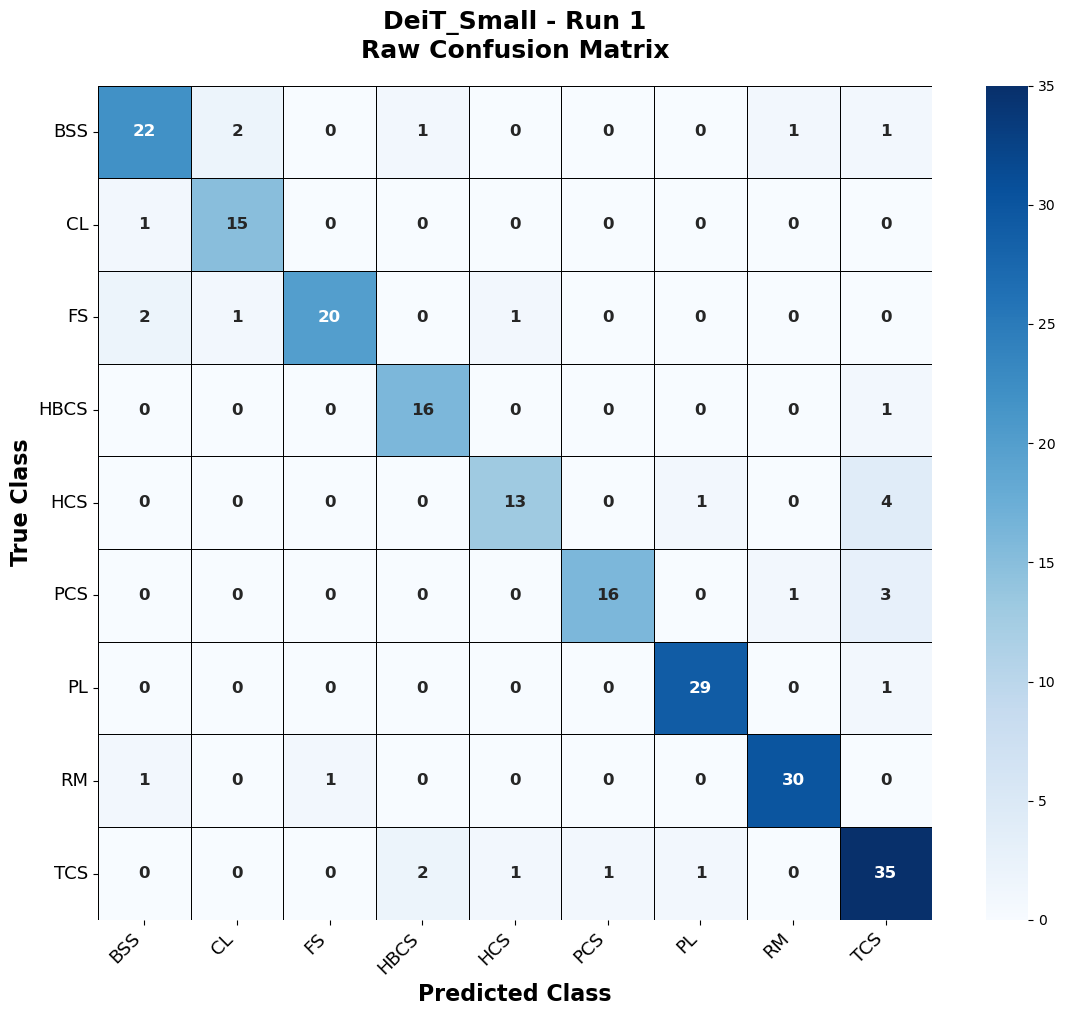

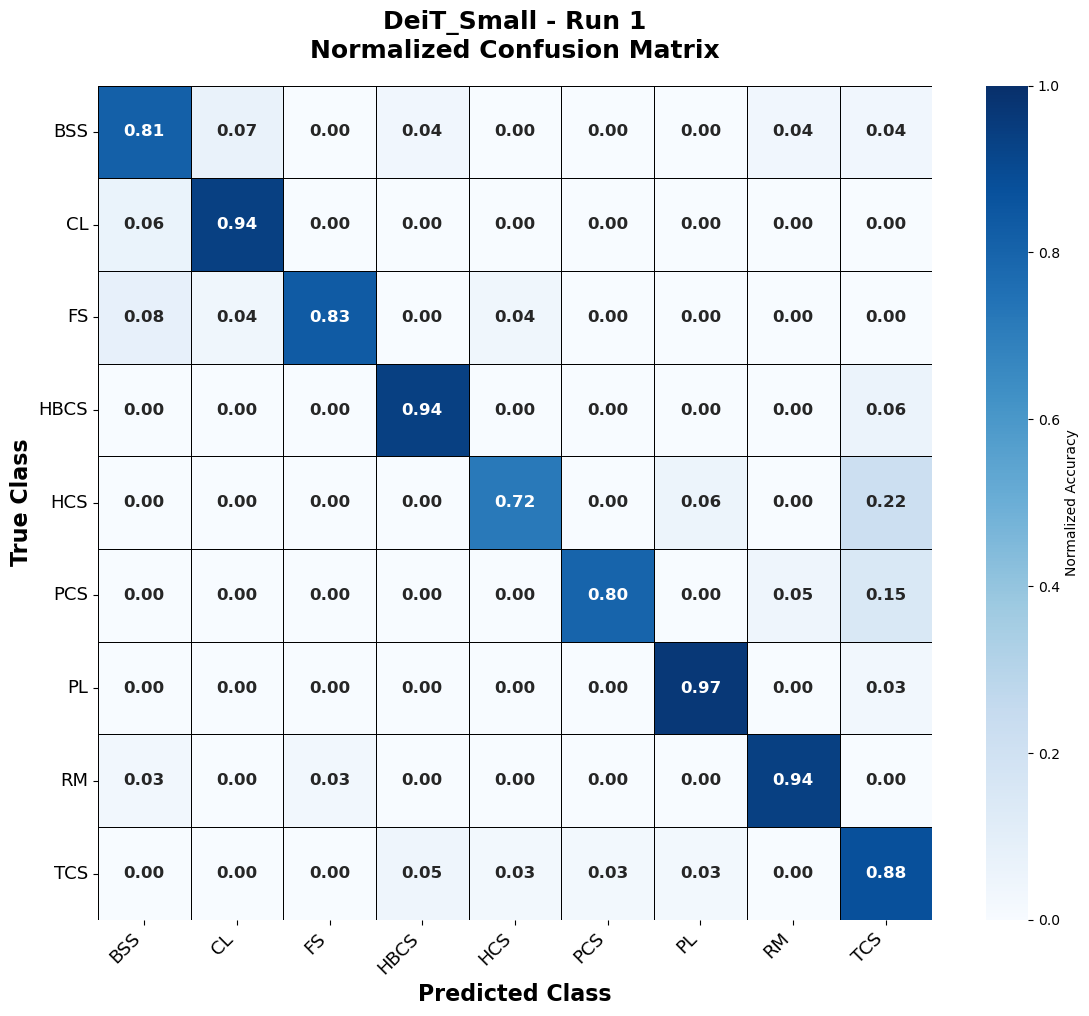


✓ Confusion matrices saved successfully

Files Saved Successfully
------------------------------------------------------------
Raw Confusion CSV          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\DeiT_Small_Run1_Raw.csv
Normalized Confusion CSV   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\DeiT_Small_Run1_Normalized.csv
Raw Confusion PNG          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\DeiT_Small_Run1_Raw.png
Normalized Confusion PNG   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\DeiT_Small_Run1_Normalized.png
Most Confused Classes CSV  : C:\Users\Frontech\Desktop\Codes\Combined 

In [15]:
# ============================================================
# TEST SECTION 6 : CONFUSION MATRIX
# ============================================================

result = plot_confusion_matrix(result)

print("\n" + "="*80)
print("SECTION 6 TEST PASSED")
print("="*80)

print(f"Raw CSV               : {result['raw_confusion_csv']}")
print(f"Normalized CSV        : {result['normalized_confusion_csv']}")
print(f"Raw PNG               : {result['raw_confusion_png']}")
print(f"Normalized PNG        : {result['normalized_confusion_png']}")
print(f"Misclassified CSV     : {result['misclassified_csv']}")

In [16]:
# ============================================================
# STEP 7 : BUILD PREDICTION TABLE
# ============================================================

def build_prediction_table(result):

    print("=" * 80)
    print(f"Prediction Table : {result['model_name']} | Run {result['run']}")
    print("=" * 80)

    # --------------------------------------------------------
    # Extract prediction results
    # --------------------------------------------------------

    y_true = result["y_true"]
    y_pred = result["y_pred"]
    y_prob = result["y_prob"]

    classes = result["classes"]

    image_names = result["test_files"]
    image_paths = result["test_paths"]

    model_name = result["model_name"]
    run_number = result["run"]

    # --------------------------------------------------------
    # Initialize prediction table
    # --------------------------------------------------------

    prediction_rows = []

    # --------------------------------------------------------
    # Process every test image
    # --------------------------------------------------------

    for i in range(len(y_true)):

        probs = y_prob[i]

        # Top-1 prediction
        top1_idx = np.argmax(probs)
        top1_prob = probs[top1_idx]

        # Top-2 prediction
        sorted_idx = np.argsort(probs)[::-1]

        top2_idx = sorted_idx[1]
        top2_prob = probs[top2_idx]

        # True class probability
        true_prob = probs[y_true[i]]

        # Confidence margin
        margin = top1_prob - top2_prob

        prediction_rows.append({

            "Model": model_name,

            "Run": run_number,

            "Image_Name": image_names[i],

            "Image_Path": image_paths[i],

            "True_Index": int(y_true[i]),

            "Predicted_Index": int(y_pred[i]),

            "True_Class": classes[y_true[i]],

            "Predicted_Class": classes[y_pred[i]],

            "Correct": y_true[i] == y_pred[i],

            "Prediction_Probability": float(top1_prob),

            "True_Class_Probability": float(true_prob),

            "Second_Best_Class": classes[top2_idx],

            "Second_Best_Probability": float(top2_prob),

            "Confidence_Margin": float(margin)

        })

    # --------------------------------------------------------
    # Create DataFrame
    # --------------------------------------------------------

    prediction_df = pd.DataFrame(prediction_rows)

    # --------------------------------------------------------
    # Confidence Category
    # --------------------------------------------------------
    
    prediction_df["Confidence_Category"] = np.select(
    
        [
    
            prediction_df["Prediction_Probability"] >= 0.90,
    
            prediction_df["Prediction_Probability"] >= 0.75,
    
            prediction_df["Prediction_Probability"] >= 0.50
    
        ],
    
        [
    
            "Very High",
    
            "High",
    
            "Moderate"
    
        ],
    
        default="Low"
    
    )    
        
    # --------------------------------------------------------
    # Rank by confidence
    # --------------------------------------------------------

    prediction_df = prediction_df.sort_values(
        by="Prediction_Probability",
        ascending=False
    ).reset_index(drop=True)

    prediction_df.insert(
        0,
        "Confidence_Rank",
        np.arange(1, len(prediction_df) + 1)
    )

    # --------------------------------------------------------
    # --------------------------------------------------------
    # Store in Result Dictionary
    # --------------------------------------------------------
    
    result["prediction_table"] = prediction_df
    
    # --------------------------------------------------------
    # Save Prediction Table
    # --------------------------------------------------------
    
    if SAVE_PREDICTIONS:
    
        prediction_file = (
            PREDICTIONS_DIR /
            f"{result['model_name']}_Run{result['run']}_Prediction_Table.csv"
        )
    
        prediction_df.to_csv(
            prediction_file,
            index=False
        )
    
        result["prediction_table_file"] = prediction_file
    
    print("\nPrediction Table Created Successfully")
    print(f"Total Predictions : {len(prediction_df)}")
    
    if SAVE_PREDICTIONS:
    
        print("\nFiles Saved Successfully")
        print("-"*60)
        print(f"Prediction Table CSV : {prediction_file.resolve()}")
    
    else:
    
        print("\nSAVE_PREDICTIONS = False")
        print("Prediction table was not saved.")
    
    return result

print("=" * 80)
print("STEP 7 READY")
print("=" * 80)

STEP 7 READY


In [17]:
# ============================================================
# TEST SECTION 7 : BUILD PREDICTION TABLE
# ============================================================

result = build_prediction_table(result)

print("\n" + "="*80)
print("SECTION 7 TEST PASSED")
print("="*80)

print(f"Prediction Table Shape : {result['prediction_table'].shape}")

if SAVE_PREDICTIONS:
    print(f"Prediction CSV : {result['prediction_table_file']}")

Prediction Table : DeiT_Small | Run 1

Prediction Table Created Successfully
Total Predictions : 224

Files Saved Successfully
------------------------------------------------------------
Prediction Table CSV : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Predictions\DeiT_Small_Run1_Prediction_Table.csv

SECTION 7 TEST PASSED
Prediction Table Shape : (224, 16)
Prediction CSV : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Predictions\DeiT_Small_Run1_Prediction_Table.csv


In [18]:
# ============================================================
# TEST SECTION 7 : PREDICTION SUMMARY
# ============================================================

def prediction_summary(result):

    print("=" * 80)
    print(f"Prediction Summary : {result['model_name']} | Run {result['run']}")
    print("=" * 80)

    # --------------------------------------------------------
    # Load Prediction Table
    # --------------------------------------------------------

    prediction_df = result["prediction_table"]

    # --------------------------------------------------------
    # Basic Statistics
    # --------------------------------------------------------

    total_images = len(prediction_df)

    correct_predictions = prediction_df["Correct"].sum()

    incorrect_predictions = total_images - correct_predictions

    accuracy = (correct_predictions / total_images) * 100

    # --------------------------------------------------------
    # Confidence Statistics
    # --------------------------------------------------------

    avg_confidence = (
        prediction_df["Prediction_Probability"].mean() * 100
    )

    avg_true_probability = (
        prediction_df["True_Class_Probability"].mean() * 100
    )

    avg_margin = (
        prediction_df["Confidence_Margin"].mean() * 100
    )

    # --------------------------------------------------------
    # Correct / Incorrect Confidence
    # --------------------------------------------------------

    correct_df = prediction_df[prediction_df["Correct"]]

    incorrect_df = prediction_df[~prediction_df["Correct"]]

    correct_confidence = (
        correct_df["Prediction_Probability"].mean() * 100
        if len(correct_df) > 0 else 0
    )

    incorrect_confidence = (
        incorrect_df["Prediction_Probability"].mean() * 100
        if len(incorrect_df) > 0 else 0
    )

    # --------------------------------------------------------
    # Build Summary
    # --------------------------------------------------------

    summary = {

        "Model": result["model_name"],

        "Run": result["run"],

        "Total Images": total_images,

        "Correct Predictions": int(correct_predictions),

        "Incorrect Predictions": int(incorrect_predictions),

        "Accuracy": round(accuracy, 2),

        "Average Prediction Confidence (%)":
            round(avg_confidence, 2),

        "Average True-Class Probability (%)":
            round(avg_true_probability, 2),

        "Average Confidence Margin (%)":
            round(avg_margin, 2),

        "Correct Prediction Confidence (%)":
            round(correct_confidence, 2),

        "Incorrect Prediction Confidence (%)":
            round(incorrect_confidence, 2)

    }

    summary_df = pd.DataFrame([summary])

    # --------------------------------------------------------
    # --------------------------------------------------------
    # Store Results
    # --------------------------------------------------------
    
    result["prediction_summary"] = summary_df
    
    # --------------------------------------------------------
    # Save Prediction Summary
    # --------------------------------------------------------
    
    if SAVE_PREDICTIONS:
    
        summary_file = (
            PREDICTIONS_DIR /
            f"{result['model_name']}_Run{result['run']}_Prediction_Summary.csv"
        )
    
        summary_df.to_csv(
            summary_file,
            index=False
        )
    
        result["prediction_summary_file"] = summary_file
    
    # --------------------------------------------------------
    # Display Summary
    # --------------------------------------------------------
    
    print(f"Model                          : {result['model_name']}")
    print(f"Run                            : {result['run']}")
    print("-" * 80)
    print(f"Total Images                   : {total_images}")
    print(f"Correct Predictions            : {correct_predictions}")
    print(f"Incorrect Predictions          : {incorrect_predictions}")
    print(f"Accuracy                   : {accuracy:.2f}")
    print("-" * 80)
    print(f"Average Prediction Confidence  : {avg_confidence:.2f}%")
    print(f"Average True-Class Probability : {avg_true_probability:.2f}%")
    print(f"Average Confidence Margin      : {avg_margin:.2f}%")
    print("-" * 80)
    print(f"Correct Prediction Confidence  : {correct_confidence:.2f}%")
    print(f"Incorrect Prediction Confidence: {incorrect_confidence:.2f}%")
    
    if SAVE_PREDICTIONS:
    
        print("\nFiles Saved Successfully")
        print("-" * 60)
        print(f"Prediction Summary CSV : {summary_file.resolve()}")
    
    else:
    
        print("\nSAVE_PREDICTIONS = False")
        print("Prediction summary was not saved.")
    
    return result


print("=" * 80)
print("TEST SECTION 7 : PREDICTION SUMMARY")
print("=" * 80)

TEST SECTION 7 : PREDICTION SUMMARY


In [19]:
# ============================================================
# TEST SECTION 7 : PREDICTION SUMMARY
# ============================================================

result = prediction_summary(result)

print("\n" + "=" * 80)
print("SECTION 7 TEST PASSED")
print("=" * 80)

print(result["prediction_summary"])

if SAVE_PREDICTIONS:
    print(f"\nPrediction Summary CSV : {result['prediction_summary_file']}")

Prediction Summary : DeiT_Small | Run 1
Model                          : DeiT_Small
Run                            : 1
--------------------------------------------------------------------------------
Total Images                   : 224
Correct Predictions            : 196
Incorrect Predictions          : 28
Accuracy                   : 87.50
--------------------------------------------------------------------------------
Average Prediction Confidence  : 93.81%
Average True-Class Probability : 85.42%
Average Confidence Margin      : 89.38%
--------------------------------------------------------------------------------
Correct Prediction Confidence  : 96.09%
Incorrect Prediction Confidence: 77.81%

Files Saved Successfully
------------------------------------------------------------
Prediction Summary CSV : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Predictions\DeiT_Small_Run1_Prediction_Summary.csv

SE

In [20]:
# ============================================================
# STEP 7C : BEST & WORST PREDICTIONS
# ============================================================

def analyze_predictions(result):

    print("=" * 80)
    print(f"Prediction Analysis : {result['model_name']} | Run {result['run']}")
    print("=" * 80)

    # --------------------------------------------------------
    # Load Prediction Table
    # --------------------------------------------------------

    prediction_df = result["prediction_table"]

    # --------------------------------------------------------
    # Separate Correct and Incorrect Predictions
    # --------------------------------------------------------

    correct_df = prediction_df[
        prediction_df["Correct"] == True
    ].copy()

    incorrect_df = prediction_df[
        prediction_df["Correct"] == False
    ].copy()

    # --------------------------------------------------------
    # Highest Confidence Correct Predictions
    # --------------------------------------------------------

    best_predictions = correct_df.sort_values(
        by="Prediction_Probability",
        ascending=False
    ).reset_index(drop=True)

    # --------------------------------------------------------
    # Lowest Confidence Correct Predictions
    # --------------------------------------------------------

    weakest_correct = correct_df.sort_values(
        by="Prediction_Probability",
        ascending=True
    ).reset_index(drop=True)

    # --------------------------------------------------------
    # Highest Confidence Incorrect Predictions
    # --------------------------------------------------------

    dangerous_predictions = incorrect_df.sort_values(
        by="Prediction_Probability",
        ascending=False
    ).reset_index(drop=True)

    # --------------------------------------------------------
    # Lowest Confidence Incorrect Predictions
    # --------------------------------------------------------

    uncertain_predictions = incorrect_df.sort_values(
        by="Prediction_Probability",
        ascending=True
    ).reset_index(drop=True)

    # --------------------------------------------------------
    # --------------------------------------------------------
    # Store Results
    # --------------------------------------------------------
    
    result["best_predictions"] = best_predictions
    result["weakest_correct_predictions"] = weakest_correct
    result["dangerous_predictions"] = dangerous_predictions
    result["uncertain_predictions"] = uncertain_predictions
    
    # --------------------------------------------------------
    # Save Analysis Tables
    # --------------------------------------------------------
    
    if SAVE_PREDICTIONS:
    
        best_file = (
            PREDICTIONS_DIR /
            f"{result['model_name']}_Run{result['run']}_Best_Predictions.csv"
        )
    
        weakest_file = (
            PREDICTIONS_DIR /
            f"{result['model_name']}_Run{result['run']}_Weakest_Correct_Predictions.csv"
        )
    
        dangerous_file = (
            PREDICTIONS_DIR /
            f"{result['model_name']}_Run{result['run']}_Dangerous_Predictions.csv"
        )
    
        uncertain_file = (
            PREDICTIONS_DIR /
            f"{result['model_name']}_Run{result['run']}_Uncertain_Predictions.csv"
        )
    
        best_predictions.to_csv(best_file, index=False)
        weakest_correct.to_csv(weakest_file, index=False)
        dangerous_predictions.to_csv(dangerous_file, index=False)
        uncertain_predictions.to_csv(uncertain_file, index=False)
    
        result["best_predictions_file"] = best_file
        result["weakest_correct_predictions_file"] = weakest_file
        result["dangerous_predictions_file"] = dangerous_file
        result["uncertain_predictions_file"] = uncertain_file
    
    # --------------------------------------------------------
    # Display Summary
    # --------------------------------------------------------
    
    print(f"Best Correct Predictions          : {len(best_predictions)}")
    print(f"Weakest Correct Predictions       : {len(weakest_correct)}")
    print(f"High Confidence Wrong Predictions : {len(dangerous_predictions)}")
    print(f"Low Confidence Wrong Predictions  : {len(uncertain_predictions)}")
    
    if SAVE_PREDICTIONS:
    
        print("\nFiles Saved Successfully")
        print("-" * 60)
        print(f"Best Predictions CSV             : {best_file.resolve()}")
        print(f"Weakest Correct CSV              : {weakest_file.resolve()}")
        print(f"Dangerous Predictions CSV        : {dangerous_file.resolve()}")
        print(f"Uncertain Predictions CSV        : {uncertain_file.resolve()}")
    
    else:
    
        print("\nSAVE_PREDICTIONS = False")
        print("Prediction analysis tables were not saved.")
    
    return result

print("=" * 80)
print("STEP 7C READY")
print("=" * 80)

STEP 7C READY


In [21]:
# ============================================================
# TEST SECTION 7C : PREDICTION ANALYSIS
# ============================================================

result = analyze_predictions(result)

print("\n" + "=" * 80)
print("SECTION 7 TEST PASSED")
print("=" * 80)

print(f"Best Predictions           : {len(result['best_predictions'])}")
print(f"Weakest Correct            : {len(result['weakest_correct_predictions'])}")
print(f"Dangerous Predictions      : {len(result['dangerous_predictions'])}")
print(f"Uncertain Predictions      : {len(result['uncertain_predictions'])}")

if SAVE_PREDICTIONS:
    print(f"\nBest Predictions CSV       : {result['best_predictions_file']}")
    print(f"Weakest Correct CSV        : {result['weakest_correct_predictions_file']}")
    print(f"Dangerous Predictions CSV  : {result['dangerous_predictions_file']}")
    print(f"Uncertain Predictions CSV  : {result['uncertain_predictions_file']}")

Prediction Analysis : DeiT_Small | Run 1
Best Correct Predictions          : 196
Weakest Correct Predictions       : 196
High Confidence Wrong Predictions : 28
Low Confidence Wrong Predictions  : 28

Files Saved Successfully
------------------------------------------------------------
Best Predictions CSV             : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Predictions\DeiT_Small_Run1_Best_Predictions.csv
Weakest Correct CSV              : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Predictions\DeiT_Small_Run1_Weakest_Correct_Predictions.csv
Dangerous Predictions CSV        : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Predictions\DeiT_Small_Run1_Dangerous_Predictions.csv
Uncertain Predictions CSV        : C:\Users\Frontech\Desktop\Code

In [22]:
# ============================================================
# STEP 8 : CONFIDENCE CATEGORIZATION
# ============================================================

def confidence_analysis(result):

    print("=" * 80)
    print(f"Confidence Analysis : {result['model_name']} | Run {result['run']}")
    print("=" * 80)

    # --------------------------------------------------------
    # Load Prediction Table
    # --------------------------------------------------------

    prediction_df = result["prediction_table"].copy()

    # --------------------------------------------------------
    # Confidence Categorization Function
    # --------------------------------------------------------

    def classify_confidence(prob):

        if prob >= 0.90:
            return "Excellent", "Very High Confidence"

        elif prob >= 0.70:
            return "Good", "High Confidence"

        elif prob >= 0.50:
            return "Average", "Moderate Confidence"

        else:
            return "Poor", "Low Confidence"

    # --------------------------------------------------------
    # Assign Categories
    # --------------------------------------------------------

    categories = prediction_df["Prediction_Probability"].apply(
        classify_confidence
    )

    prediction_df["Confidence_Category"] = [
        c[0] for c in categories
    ]

    prediction_df["Confidence_Level"] = [
        c[1] for c in categories
    ]

    # --------------------------------------------------------
    # Store Updated Table
    # --------------------------------------------------------

    result["prediction_table"] = prediction_df

    # --------------------------------------------------------
    # Category Statistics
    # --------------------------------------------------------

    confidence_summary = (
        prediction_df["Confidence_Category"]
        .value_counts()
        .reindex(
            ["Excellent", "Good", "Average", "Poor"],
            fill_value=0
        )
    )

    confidence_df = confidence_summary.reset_index()

    confidence_df.columns = [
        "Confidence_Category",
        "Number_of_Images"
    ]

    confidence_df["Percentage"] = (
        confidence_df["Number_of_Images"]
        / len(prediction_df)
        * 100
    ).round(2)

    # --------------------------------------------------------
    # --------------------------------------------------------
    # Store Results
    # --------------------------------------------------------
    
    result["confidence_summary"] = confidence_df
    
    # --------------------------------------------------------
    # Save Confidence Summary
    # --------------------------------------------------------
    
    if SAVE_PREDICTIONS:
    
        confidence_file = (
            PREDICTIONS_DIR /
            f"{result['model_name']}_Run{result['run']}_Confidence_Summary.csv"
        )
    
        confidence_df.to_csv(
            confidence_file,
            index=False
        )
    
        result["confidence_summary_file"] = confidence_file
    
    # --------------------------------------------------------
    # Display Results
    # --------------------------------------------------------
    
    print("\nConfidence Category Distribution")
    print("-" * 80)
    print(confidence_df)
    
    if SAVE_PREDICTIONS:
    
        print("\nFiles Saved Successfully")
        print("-" * 60)
        print(f"Confidence Summary CSV : {confidence_file.resolve()}")
    
    else:
    
        print("\nSAVE_PREDICTIONS = False")
        print("Confidence summary was not saved.")
    
    return result


print("=" * 80)
print("STEP 8 READY")
print("=" * 80)

STEP 8 READY


In [23]:
# ============================================================
# TEST SECTION 8 : CONFIDENCE CATEGORIZATION
# ============================================================

result = confidence_analysis(result)

print("\n" + "=" * 80)
print("SECTION 8 TEST PASSED")
print("=" * 80)

print(result["confidence_summary"])

if SAVE_PREDICTIONS:
    print(f"\nConfidence Summary CSV : {result['confidence_summary_file']}")

Confidence Analysis : DeiT_Small | Run 1

Confidence Category Distribution
--------------------------------------------------------------------------------
  Confidence_Category  Number_of_Images  Percentage
0           Excellent               179       79.91
1                Good                29       12.95
2             Average                13        5.80
3                Poor                 3        1.34

Files Saved Successfully
------------------------------------------------------------
Confidence Summary CSV : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Predictions\DeiT_Small_Run1_Confidence_Summary.csv

SECTION 8 TEST PASSED
  Confidence_Category  Number_of_Images  Percentage
0           Excellent               179       79.91
1                Good                29       12.95
2             Average                13        5.80
3                Poor                 3        1.34

Confidence

In [24]:
# ============================================================
# STEP 8B : CONFIDENCE vs CORRECTNESS ANALYSIS
# ============================================================

def confidence_correctness_analysis(result):

    print("=" * 80)
    print(f"Confidence vs Correctness : {result['model_name']} | Run {result['run']}")
    print("=" * 80)

    # --------------------------------------------------------
    # Load Prediction Table
    # --------------------------------------------------------

    prediction_df = result["prediction_table"].copy()

    confidence_order = [
        "Excellent",
        "Good",
        "Average",
        "Poor"
    ]

    # --------------------------------------------------------
    # Confidence vs Correctness
    # --------------------------------------------------------

    summary = []

    for category in confidence_order:

        subset = prediction_df[
            prediction_df["Confidence_Category"] == category
        ]

        total = len(subset)

        correct = subset["Correct"].sum()

        incorrect = total - correct

        accuracy = (
            (correct / total) * 100
            if total > 0 else 0
        )

        mean_confidence = (
            subset["Prediction_Probability"].mean() * 100
            if total > 0 else 0
        )

        summary.append({

            "Confidence_Category": category,

            "Total_Images": total,

            "Correct": int(correct),

            "Incorrect": int(incorrect),

            "Accuracy": round(accuracy, 2),

            "Mean_Confidence (%)": round(mean_confidence, 2)

        })

    confidence_correctness_df = pd.DataFrame(summary)

    # --------------------------------------------------------
    # High Confidence Wrong Predictions
    # --------------------------------------------------------

    high_conf_wrong = prediction_df[
        (prediction_df["Correct"] == False) &
        (prediction_df["Confidence_Category"].isin(
            ["Excellent", "Good"]
        ))
    ].copy()

    high_conf_wrong = high_conf_wrong.sort_values(
        by="Prediction_Probability",
        ascending=False
    )

    # --------------------------------------------------------
    # Low Confidence Correct Predictions
    # --------------------------------------------------------

    low_conf_correct = prediction_df[
        (prediction_df["Correct"] == True) &
        (prediction_df["Confidence_Category"].isin(
            ["Average", "Poor"]
        ))
    ].copy()

    low_conf_correct = low_conf_correct.sort_values(
        by="Prediction_Probability",
        ascending=True
    )

    # --------------------------------------------------------
    # --------------------------------------------------------
    # Store Results
    # --------------------------------------------------------
    
    result["confidence_correctness"] = confidence_correctness_df
    result["high_confidence_wrong"] = high_conf_wrong
    result["low_confidence_correct"] = low_conf_correct
    
    # --------------------------------------------------------
    # Save Results
    # --------------------------------------------------------
    
    if SAVE_PREDICTIONS:
    
        summary_file = (
            PREDICTIONS_DIR /
            f"{result['model_name']}_Run{result['run']}_Confidence_Correctness_Summary.csv"
        )
    
        high_wrong_file = (
            PREDICTIONS_DIR /
            f"{result['model_name']}_Run{result['run']}_High_Confidence_Wrong.csv"
        )
    
        low_correct_file = (
            PREDICTIONS_DIR /
            f"{result['model_name']}_Run{result['run']}_Low_Confidence_Correct.csv"
        )
    
        confidence_correctness_df.to_csv(summary_file, index=False)
        high_conf_wrong.to_csv(high_wrong_file, index=False)
        low_conf_correct.to_csv(low_correct_file, index=False)
    
        result["confidence_correctness_file"] = summary_file
        result["high_confidence_wrong_file"] = high_wrong_file
        result["low_confidence_correct_file"] = low_correct_file
    
    # --------------------------------------------------------
    # Display Results
    # --------------------------------------------------------
    
    print("\nConfidence vs Correctness Summary")
    print("-" * 80)
    print(confidence_correctness_df)
    
    print(f"\nHigh Confidence Wrong Predictions : {len(high_conf_wrong)}")
    print(f"Low Confidence Correct Predictions: {len(low_conf_correct)}")
    
    if SAVE_PREDICTIONS:
    
        print("\nFiles Saved Successfully")
        print("-" * 60)
        print(f"Confidence Summary CSV     : {summary_file.resolve()}")
        print(f"High Confidence Wrong CSV  : {high_wrong_file.resolve()}")
        print(f"Low Confidence Correct CSV : {low_correct_file.resolve()}")
    
    else:
    
        print("\nSAVE_PREDICTIONS = False")
        print("Confidence analysis files were not saved.")
    
    return result


print("=" * 80)
print("STEP 8B READY")
print("=" * 80)

STEP 8B READY


In [25]:
# ============================================================
# TEST SECTION 8B : CONFIDENCE vs CORRECTNESS ANALYSIS
# ============================================================

result = confidence_correctness_analysis(result)

print("\n" + "=" * 80)
print("SECTION 8 TEST PASSED")
print("=" * 80)

print(result["confidence_correctness"])

if SAVE_PREDICTIONS:
    print(f"\nSummary CSV              : {result['confidence_correctness_file']}")
    print(f"High Wrong CSV           : {result['high_confidence_wrong_file']}")
    print(f"Low Correct CSV          : {result['low_confidence_correct_file']}")

Confidence vs Correctness : DeiT_Small | Run 1

Confidence vs Correctness Summary
--------------------------------------------------------------------------------
  Confidence_Category  Total_Images  Correct  Incorrect  Accuracy  \
0           Excellent           179      171          8     95.53   
1                Good            29       19         10     65.52   
2             Average            13        5          8     38.46   
3                Poor             3        1          2     33.33   

   Mean_Confidence (%)  
0                98.84  
1                82.61  
2                60.37  
3                46.54  

High Confidence Wrong Predictions : 18
Low Confidence Correct Predictions: 6

Files Saved Successfully
------------------------------------------------------------
Confidence Summary CSV     : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Predictions\DeiT_Small_Run1_Confidence_Correc

In [26]:
# ============================================================
# STEP 8C : CLASS-WISE CONFIDENCE ANALYSIS
# ============================================================

def classwise_confidence_analysis(result):

    print("=" * 80)
    print(f"Class-wise Confidence Analysis : {result['model_name']} | Run {result['run']}")
    print("=" * 80)

    # --------------------------------------------------------
    # Load Prediction Table
    # --------------------------------------------------------

    prediction_df = result["prediction_table"].copy()

    classes = result["classes"]

    confidence_order = [
        "Excellent",
        "Good",
        "Average",
        "Poor"
    ]

    # --------------------------------------------------------
    # Class-wise Analysis
    # --------------------------------------------------------

    class_summary = []

    for cls in classes:

        class_df = prediction_df[
            prediction_df["True_Class"] == cls
        ]

        total = len(class_df)

        if total == 0:
            continue

        correct = class_df["Correct"].sum()

        incorrect = total - correct

        accuracy = (correct / total) * 100

        mean_conf = (
            class_df["Prediction_Probability"].mean() * 100
        )

        median_conf = (
            class_df["Prediction_Probability"].median() * 100
        )

        min_conf = (
            class_df["Prediction_Probability"].min() * 100
        )

        max_conf = (
            class_df["Prediction_Probability"].max() * 100
        )

        std_conf = (
            class_df["Prediction_Probability"].std() * 100
        )

        row = {

            "Class": cls,

            "Total Images": total,

            "Correct": int(correct),

            "Incorrect": int(incorrect),

            "Accuracy": round(accuracy,2),

            "Mean Confidence (%)": round(mean_conf,2),

            "Median Confidence (%)": round(median_conf,2),

            "Std Confidence (%)": round(std_conf,2),

            "Min Confidence (%)": round(min_conf,2),

            "Max Confidence (%)": round(max_conf,2)

        }

        # --------------------------------------------
        # Confidence Category Counts
        # --------------------------------------------

        for category in confidence_order:

            row[category] = int(
                (class_df["Confidence_Category"] == category).sum()
            )

        class_summary.append(row)

    classwise_df = pd.DataFrame(class_summary)

    # --------------------------------------------------------
    # Sort by Accuracy
    # --------------------------------------------------------

    classwise_df = classwise_df.sort_values(
        by="Accuracy",
        ascending=False
    ).reset_index(drop=True)

    # --------------------------------------------------------
    # --------------------------------------------------------
    # Store Results
    # --------------------------------------------------------
    
    result["classwise_confidence"] = classwise_df
    
    # --------------------------------------------------------
    # Save Results
    # --------------------------------------------------------
    
    if SAVE_PREDICTIONS:
    
        classwise_file = (
            PREDICTIONS_DIR /
            f"{result['model_name']}_Run{result['run']}_Classwise_Confidence_Analysis.csv"
        )
    
        classwise_df.to_csv(
            classwise_file,
            index=False
        )
    
        result["classwise_confidence"] = classwise_file
    
    # --------------------------------------------------------
    # Display
    # --------------------------------------------------------
    
    print("\nClass-wise Confidence Summary")
    print("-" * 80)
    print(classwise_df)
    
    if SAVE_PREDICTIONS:
    
        print("\nFiles Saved Successfully")
        print("-" * 60)
        print(f"Class-wise Confidence CSV : {classwise_file.resolve()}")
    
    else:
    
        print("\nSAVE_PREDICTIONS = False")
        print("Class-wise confidence analysis was not saved.")
    
    return result


print("=" * 80)
print("STEP 8C READY")
print("=" * 80)

STEP 8C READY


In [27]:
# ============================================================
# TEST SECTION 8 : CLASS-WISE CONFIDENCE ANALYSIS
# ============================================================

result = classwise_confidence_analysis(result)

print("\n" + "=" * 80)
print("SECTION 8 TEST PASSED")
print("=" * 80)

print(result["classwise_confidence"])

if SAVE_PREDICTIONS:
    print(f"\nClass-wise Confidence CSV : {result['classwise_confidence']}")

Class-wise Confidence Analysis : DeiT_Small | Run 1

Class-wise Confidence Summary
--------------------------------------------------------------------------------
  Class  Total Images  Correct  Incorrect  Accuracy  Mean Confidence (%)  \
0    PL            30       29          1     96.67                96.38   
1  HBCS            17       16          1     94.12                98.57   
2    RM            32       30          2     93.75                96.54   
3    CL            16       15          1     93.75                96.32   
4   TCS            40       35          5     87.50                95.61   
5    FS            24       20          4     83.33                89.17   
6   BSS            27       22          5     81.48                91.50   
7   PCS            20       16          4     80.00                94.20   
8   HCS            18       13          5     72.22                83.09   

   Median Confidence (%)  Std Confidence (%)  Min Confidence (%)  \
0      

In [28]:
# ============================================================
# STEP 9 : MULTI-CLASS ROC CURVES & AUC ANALYSIS
# ============================================================

from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

def plot_multiclass_roc(result):

    print("=" * 80)
    print(f"ROC Curve : {result['model_name']} | Run {result['run']}")
    print("=" * 80)

    # --------------------------------------------------------
    # Load Data
    # --------------------------------------------------------

    y_true = result["y_true"]
    y_prob = result["y_prob"]
    classes = result["classes"]

    n_classes = len(classes)

    # --------------------------------------------------------
    # Binarize Labels
    # --------------------------------------------------------

    y_true_bin = label_binarize(
        y_true,
        classes=np.arange(n_classes)
    )

    fpr = {}
    tpr = {}
    roc_auc = {}

    # --------------------------------------------------------
    # Per-Class ROC
    # --------------------------------------------------------

    for i in range(n_classes):

        fpr[i], tpr[i], _ = roc_curve(
            y_true_bin[:, i],
            y_prob[:, i]
        )

        roc_auc[i] = auc(
            fpr[i],
            tpr[i]
        )

    # --------------------------------------------------------
    # Micro Average
    # --------------------------------------------------------

    fpr["micro"], tpr["micro"], _ = roc_curve(
        y_true_bin.ravel(),
        y_prob.ravel()
    )

    roc_auc["micro"] = auc(
        fpr["micro"],
        tpr["micro"]
    )

    # --------------------------------------------------------
    # Macro Average
    # --------------------------------------------------------

    roc_auc["macro"] = np.mean(
        [roc_auc[i] for i in range(n_classes)]
    )

    # --------------------------------------------------------
    # Weighted Average
    # --------------------------------------------------------

    class_counts = np.bincount(y_true)

    roc_auc["weighted"] = np.average(
        [roc_auc[i] for i in range(n_classes)],
        weights=class_counts
    )

    # --------------------------------------------------------
    # Plot ROC Curves
    # --------------------------------------------------------

    plt.figure(figsize=(10,8))

    # --------------------------------------------------------
    # Plot ROC Curves (Sorted by AUC)
    # --------------------------------------------------------
    
    sorted_classes = sorted(
        range(n_classes),
        key=lambda x: roc_auc[x],
        reverse=True
    )
    
    colors = plt.cm.tab10(np.linspace(0,1,n_classes))
    
    for color, i in zip(colors, sorted_classes):
    
        plt.plot(
            fpr[i],
            tpr[i],
            lw=2,
            color=color,
            label=f"{classes[i]} (AUC={roc_auc[i]:.3f})"
        )
    plt.plot(
        fpr["micro"],
        tpr["micro"],
        color="black",
        linestyle="--",
        linewidth=4,
        label=f"Micro Average (AUC={roc_auc['micro']:.3f})"
    )

    plt.plot(
        [0,1],
        [0,1],
        linestyle=":",
        color="gray"
    )

    plt.xlabel(
        "False Positive Rate",
        fontsize=16,
        fontweight="bold"
    )

    plt.ylabel(
        "True Positive Rate",
        fontsize=16,
        fontweight="bold"
    )

    plt.title(
        f"{result['model_name']} | Run {result['run']}\nMulti-Class ROC Curve (One-vs-Rest)",
        fontsize=18,
        fontweight="bold"
    )

    plt.xticks(fontsize=13)
    plt.yticks(fontsize=13)

    plt.legend(
        fontsize=9,
        loc="lower right",
        frameon=True
    )
    plt.grid(alpha=0.3)
    
    plt.xlim([0,1])
    plt.ylim([0,1.02])
    
    plt.tight_layout()

    # --------------------------------------------------------
    # Save Figure
    # --------------------------------------------------------

    save_png = (
        ROC_DIR /
        f"{result['model_name']}_Run{result['run']}_ROC.png"
    )


    
    if SAVE_ROC:
    
        plt.savefig(
            save_png,
            dpi=300,
            bbox_inches="tight"
        )
    
    plt.show()


    # --------------------------------------------------------
    # --------------------------------------------------------
    # AUC Interpretation Function
    # --------------------------------------------------------
    
    def auc_interpretation(x):
    
        if x >= 0.99:
            return "Outstanding"
    
        elif x >= 0.90:
            return "Excellent"
    
        elif x >= 0.80:
            return "Good"
    
        elif x >= 0.70:
            return "Fair"
    
        elif x >= 0.60:
            return "Poor"
    
        else:
            return "Fail"
    
     
    # --------------------------------------------------------
    # --------------------------------------------------------
    # Create Class-wise AUC Table
    # --------------------------------------------------------
    
    class_auc_df = pd.DataFrame({
    
        "Class": classes,
    
        "AUC": [roc_auc[i] for i in range(n_classes)]
    
    })
    
    class_auc_df["Performance"] = (
        class_auc_df["AUC"]
        .apply(auc_interpretation)
    )
    
    class_auc_df = class_auc_df.sort_values(
        by="AUC",
        ascending=False
    ).reset_index(drop=True)
    
    # --------------------------------------------------------
    # Best & Worst AUC Classes
    # --------------------------------------------------------
    
    result["best_auc_class"] = class_auc_df.iloc[0].to_dict()
    result["worst_auc_class"] = class_auc_df.iloc[-1].to_dict()
    
    # --------------------------------------------------------
    # Overall ROC Summary
    # --------------------------------------------------------
    
    excellent_classes = int(
        (class_auc_df["AUC"] >= 0.90).sum()
    )
    
    result["excellent_auc_classes"] = excellent_classes
    result["n_classes"] = n_classes
    
    summary_df = pd.DataFrame({
    
        "Class": [
            "Micro Average",
            "Macro Average",
            "Weighted Average"
        ],
    
        "AUC": [
            roc_auc["micro"],
            roc_auc["macro"],
            roc_auc["weighted"]
        ],
    
        "Performance": [
            "Summary",
            "Summary",
            "Summary"
        ]
    
    })
    
    # --------------------------------------------------------
    # Final AUC Table
    # --------------------------------------------------------
    
    auc_df = pd.concat(
        [class_auc_df, summary_df],
        ignore_index=True
    )    
    # --------------------------------------------------------
    # Save CSV
    # --------------------------------------------------------

    auc_csv = (
        ROC_DIR /
        f"{result['model_name']}_Run{result['run']}_AUC.csv"
    )

    if SAVE_ROC:
    
        auc_df.to_csv(
            auc_csv,
            index=False
        )

    # --------------------------------------------------------
    # Store Results
    # --------------------------------------------------------
    
    result["roc_fpr"] = fpr
    result["roc_tpr"] = tpr
    result["roc_auc"] = roc_auc
    result["auc_table"] = auc_df
    result["n_classes"] = n_classes
    
    result["roc_curve_png"] = save_png
    result["auc_csv"] = auc_csv
    
    result["auc_summary"] = {
    
        "Micro AUC": round(roc_auc["micro"], 4),
        "Macro AUC": round(roc_auc["macro"], 4),
        "Weighted AUC": round(roc_auc["weighted"], 4)
    
    }
    # ============================================================
    # Save ROC Coordinates
    # ============================================================
    
    roc_rows = []
    
    for i in range(n_classes):
    
        for x, y in zip(fpr[i], tpr[i]):
    
            roc_rows.append({
    
                "Model": result["model_name"],
                "Run": result["run"],                
                "Class": classes[i],
                "AUC": roc_auc[i],
                "FPR": x,
                "TPR": y
    
            })
    
    roc_df = pd.DataFrame(roc_rows)
    
    roc_csv = (
        ROC_DIR /
        f"{result['model_name']}_Run{result['run']}_ROC.csv"
    )
    
    if SAVE_ROC:
    
        roc_df.to_csv(
            roc_csv,
            index=False
        )
    
    result["roc_csv"] = roc_csv
    
    # --------------------------------------------------------
    # Display Results
    # --------------------------------------------------------
    
    print("\nAUC Values")
    print("-" * 80)
    
    print(auc_df)
    
    print("\nROC Summary")
    print("-" * 80)
    
    excellent_classes = (
        class_auc_df["AUC"] >= 0.90
    ).sum()
    
    result["excellent_auc_classes"] = int(excellent_classes)
    
    print(f"Number of Classes           : {n_classes}")
    print(f"Excellent ROC (AUC ≥ 0.90)  : {excellent_classes}/{n_classes}")
    
    print()
    
    best = result["best_auc_class"]
    worst = result["worst_auc_class"]
    
    print(f"Best Class                  : {best['Class']} ({best['Performance']})")
    print(f"Best AUC                    : {best['AUC']:.4f}")
    
    print()
    
    print(f"Worst Class                 : {worst['Class']} ({worst['Performance']})")
    print(f"Worst AUC                   : {worst['AUC']:.4f}")
    
    print()
    
    print(f"Micro Average               : {roc_auc['micro']:.4f}")
    print(f"Macro Average               : {roc_auc['macro']:.4f}")
    print(f"Weighted Average            : {roc_auc['weighted']:.4f}")
    
    # --------------------------------------------------------
    # Saved Files
    # --------------------------------------------------------
    
    if SAVE_ROC:
    
        print("\nFiles Saved Successfully")
        print("-" * 60)
        print(f"ROC Curve PNG : {save_png.resolve()}")
        print(f"AUC Table CSV : {auc_csv.resolve()}")
    
    else:
    
        print("\nSAVE_ROC = False")
        print("ROC outputs were not saved.")
    
    return result


ROC Curve : DeiT_Small | Run 1


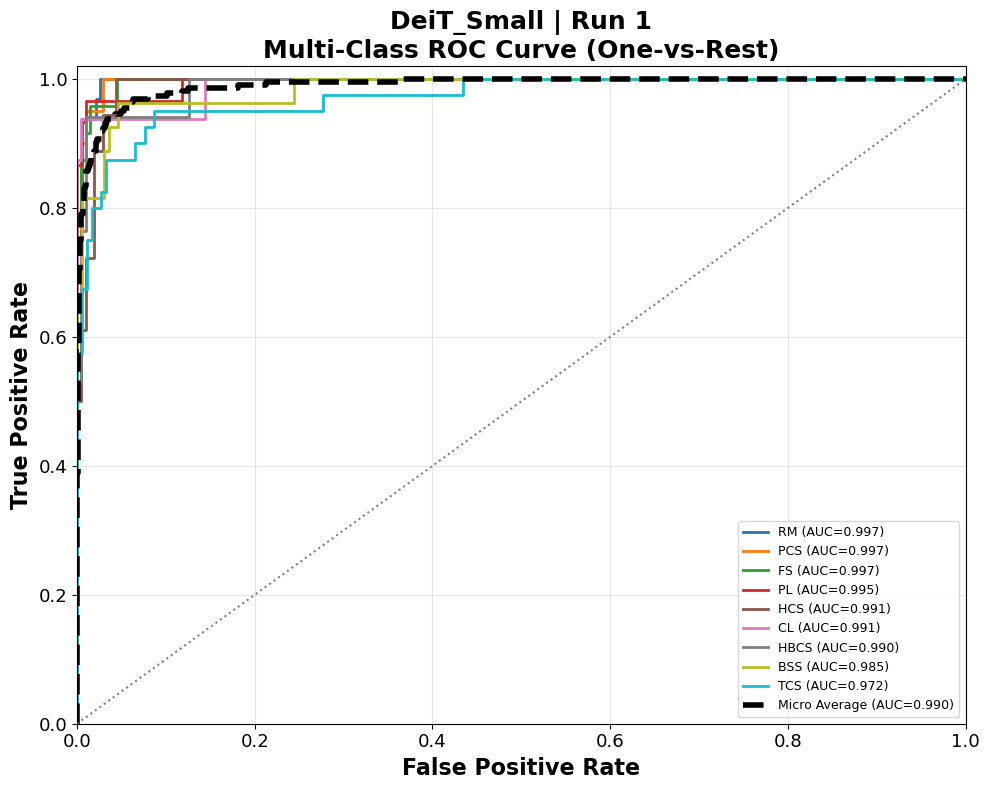


AUC Values
--------------------------------------------------------------------------------
               Class       AUC  Performance
0                 RM  0.997396  Outstanding
1                PCS  0.997304  Outstanding
2                 FS  0.996667  Outstanding
3                 PL  0.995361  Outstanding
4                HCS  0.991100  Outstanding
5                 CL  0.990685  Outstanding
6               HBCS  0.989770    Excellent
7                BSS  0.984960    Excellent
8                TCS  0.972011    Excellent
9      Micro Average  0.989978      Summary
10     Macro Average  0.990584      Summary
11  Weighted Average  0.989441      Summary

ROC Summary
--------------------------------------------------------------------------------
Number of Classes           : 9
Excellent ROC (AUC ≥ 0.90)  : 9/9

Best Class                  : RM (Outstanding)
Best AUC                    : 0.9974

Worst Class                 : TCS (Excellent)
Worst AUC                   : 0.9720

Micro

In [29]:
# ============================================================
# TEST SECTION 9 : ROC CURVE & AUC ANALYSIS
# ============================================================

result = plot_multiclass_roc(result)

print("\n" + "=" * 80)
print("SECTION 9 TEST PASSED")
print("=" * 80)

print(result["auc_table"])

if SAVE_ROC:
    print(f"\nROC Curve PNG : {result['roc_curve_png']}")
    print(f"AUC Table CSV : {result['auc_csv']}")

In [30]:
# Section 10 Misclassification analysis
def misclassification_analysis(result):

    print("=" * 80)
    print(f"Misclassification Analysis : {result['model_name']} | Run {result['run']}")
    print("=" * 80)

    # --------------------------------------------------------
    # Load Prediction Table
    # --------------------------------------------------------

    prediction_df = result["prediction_table"].copy()

    # --------------------------------------------------------
    # Keep Only Incorrect Predictions
    # --------------------------------------------------------

    misclassified_df = prediction_df[
        prediction_df["Correct"] == False
    ].copy()

    total_errors = len(misclassified_df)

    if total_errors == 0:

        print("\nNo misclassified samples found.")

        result["misclassification_analysis"] = pd.DataFrame()

        return result

    # --------------------------------------------------------
    # Support (Total Images per True Class)
    # --------------------------------------------------------

    class_support = (
        prediction_df
        .groupby("True_Class")
        .size()
        .to_dict()
    )

    # --------------------------------------------------------
    # Group by Confused Class Pairs
    # --------------------------------------------------------

    summary_df = (

        misclassified_df

        .groupby(
            ["True_Class", "Predicted_Class"],
            as_index=False
        )

        .agg(

            Count=("Correct", "count"),

            Mean_Confidence=(
                "Prediction_Probability",
                lambda x: round(x.mean() * 100, 2)
            ),

            Max_Confidence=(
                "Prediction_Probability",
                lambda x: round(x.max() * 100, 2)
            ),

            Min_Confidence=(
                "Prediction_Probability",
                lambda x: round(x.min() * 100, 2)
            )

        )

    )

    # --------------------------------------------------------
    # Add Support
    # --------------------------------------------------------

    summary_df["Support"] = summary_df["True_Class"].map(class_support)

    # --------------------------------------------------------
    # Overall Error Percentage
    # --------------------------------------------------------

    summary_df["Overall Error (%)"] = (
        summary_df["Count"] /
        total_errors *
        100
    ).round(2)

    # --------------------------------------------------------
    # Class Error Percentage
    # --------------------------------------------------------

    summary_df["Class Error (%)"] = (
        summary_df["Count"] /
        summary_df["Support"] *
        100
    ).round(2)

    # --------------------------------------------------------
    # Sort by Count
    # --------------------------------------------------------

    summary_df = summary_df.sort_values(
        by="Count",
        ascending=False
    ).reset_index(drop=True)

    # --------------------------------------------------------
    # Add Rank
    # --------------------------------------------------------

    summary_df.insert(
        0,
        "Rank",
        np.arange(1, len(summary_df) + 1)
    )

    # --------------------------------------------------------
    # Store Results
    # --------------------------------------------------------

    result["misclassification_analysis"] = summary_df

    # --------------------------------------------------------
    # Save CSV
    # --------------------------------------------------------

    if SAVE_PREDICTIONS:

        misclassification_file = (

            PREDICTIONS_DIR /

            f"{result['model_name']}_Run{result['run']}_Misclassification_Analysis.csv"

        )

        summary_df.to_csv(
            misclassification_file,
            index=False
        )

        result["misclassification_analysis_file"] = misclassification_file

    # --------------------------------------------------------
    # Display
    # --------------------------------------------------------

    print(f"\nTotal Misclassified Images : {total_errors}")

    print("-" * 80)

    print(summary_df)

    if SAVE_PREDICTIONS:

        print("\nFiles Saved Successfully")

        print("-" * 60)

        print(
            f"Misclassification CSV : "
            f"{misclassification_file.resolve()}"
        )

    else:

        print("\nSAVE_PREDICTIONS = False")

        print("Misclassification analysis was not saved.")

    return result

In [31]:
# ============================================================
# TEST SECTION 10 : MISCLASSIFICATION ANALYSIS
# ============================================================

result = misclassification_analysis(result)

print("\n" + "=" * 80)
print("SECTION 10 TEST PASSED")
print("=" * 80)

print(result["misclassification_analysis"])

if SAVE_PREDICTIONS:

    print(
        f"\nCSV : {result['misclassification_analysis_file']}"
    )

Misclassification Analysis : DeiT_Small | Run 1

Total Misclassified Images : 28
--------------------------------------------------------------------------------
    Rank True_Class Predicted_Class  Count  Mean_Confidence  Max_Confidence  \
0      1        HCS             TCS      4            65.66           95.67   
1      2        PCS             TCS      3            87.21           92.57   
2      3        BSS              CL      2            61.19           76.33   
3      4        TCS            HBCS      2            99.50           99.75   
4      5         FS             BSS      2            66.58           77.43   
5      6        BSS             TCS      1            65.86           65.86   
6      7        BSS            HBCS      1            56.65           56.65   
7      8        BSS              RM      1            99.02           99.02   
8      9         FS             HCS      1            69.37           69.37   
9     10       HBCS             TCS      1      

In [32]:
# ============================================================
# SECTION 11 : BENCHMARK SUMMARY
# ============================================================

def benchmark_summary(result):

    print("=" * 80)
    print(f"Benchmark Summary : {result['model_name']} | Run {result['run']}")
    print("=" * 80)

    # --------------------------------------------------------
    # Load Results
    # --------------------------------------------------------

    metrics = result["metrics"]

    roc = result["auc_summary"]

    benchmark = {
    
        "Model": result["model_name"],
    
        "Run": result["run"],
    
        "Total Images": result["total_images"],
    
        "Accuracy": round(metrics["Accuracy"], 4),
    
        "Precision Macro": round(metrics["Precision_Macro"], 4),
    
        "Recall Macro": round(metrics["Recall_Macro"], 4),
    
        "F1 Macro": round(metrics["F1_Macro"], 4),
    
        "Precision Weighted": round(metrics["Precision_Weighted"], 4),
    
        "Recall Weighted": round(metrics["Recall_Weighted"], 4),
    
        "F1 Weighted": round(metrics["F1_Weighted"], 4),
    
        "Balanced Accuracy": round(metrics["Balanced_Accuracy"], 4),
    
        "Cohen Kappa": round(metrics["Cohen_Kappa"], 4),
    
        "MCC": round(metrics["MCC"], 4),
    
        "Log Loss": round(metrics["Log_Loss"], 4),
    
        "Parameters": metrics["Parameters"],
    
        "Trainable Parameters": metrics["Trainable_Parameters"],
    
        "Inference Time (Total, s)": round(
            metrics["Inference_Time_Total"], 4
        ),
    
        "Inference Time/Image (ms)": round(
            metrics["Inference_Time_Per_Image"] * 1000,
            4
        ),
    
        "Micro AUC": roc["Micro AUC"],
    
        "Macro AUC": roc["Macro AUC"],
    
        "Weighted AUC": roc["Weighted AUC"]
    
    }
    benchmark_df = pd.DataFrame([benchmark])

    # --------------------------------------------------------
    # Store Results
    # --------------------------------------------------------

    result["benchmark_summary"] = benchmark_df

    # --------------------------------------------------------
    # Save Results
    # --------------------------------------------------------

    if SAVE_BENCHMARK:

        benchmark_file = (

            BENCHMARK_DIR /

            f"{result['model_name']}_Run{result['run']}_Benchmark_Summary.csv"

        )

        benchmark_df.to_csv(
            benchmark_file,
            index=False
        )

        result["benchmark_summary_file"] = benchmark_file

    # --------------------------------------------------------
    # Display
    # --------------------------------------------------------

    print(benchmark_df)

    if SAVE_BENCHMARK:

        print("\nFiles Saved Successfully")

        print("-" * 60)

        print(
            f"Benchmark Summary CSV : "
            f"{benchmark_file.resolve()}"
        )

    else:

        print("\nSAVE_BENCHMARK = False")

        print("Benchmark summary was not saved.")

    return result


print("=" * 80)
print("SECTION 11 READY")
print("=" * 80)

SECTION 11 READY


In [33]:
# ============================================================
# TEST SECTION 11 : BENCHMARK SUMMARY
# ============================================================

result = benchmark_summary(result)

print("\n" + "=" * 80)
print("SECTION 11 TEST PASSED")
print("=" * 80)

print(result["benchmark_summary"])

if SAVE_BENCHMARK:

    print(
        f"\nBenchmark CSV : "
        f"{result['benchmark_summary_file']}"
    )

Benchmark Summary : DeiT_Small | Run 1
        Model  Run  Total Images  Accuracy  Precision Macro  Recall Macro  \
0  DeiT_Small    1           224     0.875           0.8814        0.8698   

   F1 Macro  Precision Weighted  Recall Weighted  F1 Weighted  ...  \
0    0.8728              0.8792            0.875       0.8747  ...   

   Cohen Kappa    MCC  Log Loss  Parameters  Trainable Parameters  \
0       0.8574  0.858    0.4321    21669129              21669129   

   Inference Time (Total, s)  Inference Time/Image (ms)  Micro AUC  Macro AUC  \
0                     5.8971                    26.3262       0.99     0.9906   

   Weighted AUC  
0        0.9894  

[1 rows x 21 columns]

Files Saved Successfully
------------------------------------------------------------
Benchmark Summary CSV : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Benchmark\DeiT_Small_Run1_Benchmark_Summary.csv

SECTION 11 TEST PASSED
     

In [34]:
# ============================================================
# SECTION 12 : EVALUATION SUMMARY
# ============================================================

def evaluation_summary(result):

    print("=" * 80)
    print(f"Evaluation Summary : {result['model_name']} | Run {result['run']}")
    print("=" * 80)

    metrics = result["metrics"]
    benchmark = result["benchmark_summary"]

    print("\nModel Information")
    print("-" * 80)

    print(f"Model                 : {result['model_name']}")
    print(f"Run                   : {result['run']}")
    print(f"Total Images          : {result['total_images']}")

    print("\nPerformance Metrics")
    print("-" * 80)

    print(f"Accuracy              : {metrics['Accuracy']:.4f}")
    print(f"Precision (Macro)     : {metrics['Precision_Macro']:.4f}")
    print(f"Recall (Macro)        : {metrics['Recall_Macro']:.4f}")
    print(f"F1 Score (Macro)      : {metrics['F1_Macro']:.4f}")

    print(f"Precision (Weighted)  : {metrics['Precision_Weighted']:.4f}")
    print(f"Recall (Weighted)     : {metrics['Recall_Weighted']:.4f}")
    print(f"F1 Score (Weighted)   : {metrics['F1_Weighted']:.4f}")

    print(f"Balanced Accuracy     : {metrics['Balanced_Accuracy']:.4f}")
    print(f"Cohen Kappa           : {metrics['Cohen_Kappa']:.4f}")
    print(f"MCC                   : {metrics['MCC']:.4f}")
    print(f"Log Loss              : {metrics['Log_Loss']:.4f}")

    print("\nModel Complexity")
    print("-" * 80)

    print(f"Parameters            : {metrics['Parameters']:,}")
    print(f"Trainable Parameters  : {metrics['Trainable_Parameters']:,}")

    print("\nInference Speed")
    print("-" * 80)

    print(f"Total Time (s)        : {metrics['Inference_Time_Total']:.4f}")
    print(f"Time/Image (ms)       : {metrics['Inference_Time_Per_Image']*1000:.4f}")

    print("\nROC-AUC")
    print("-" * 80)

    print(f"Micro AUC             : {benchmark['Micro AUC'].iloc[0]:.4f}")
    print(f"Macro AUC             : {benchmark['Macro AUC'].iloc[0]:.4f}")
    print(f"Weighted AUC          : {benchmark['Weighted AUC'].iloc[0]:.4f}")

    print("\nGenerated Outputs")
    print("-" * 80)

    print("✓ Metrics")
    print("✓ Classification Report")
    print("✓ Confusion Matrix")
    print("✓ Prediction Table")
    print("✓ Prediction Summary")
    print("✓ Confidence Analysis")
    print("✓ ROC Curve")
    print("✓ Misclassification Analysis")
    print("✓ Benchmark Summary")

    print("\nEvaluation Completed Successfully.")

    return result


print("=" * 80)
print("SECTION 12 READY")
print("=" * 80)

SECTION 12 READY


In [35]:
# ============================================================
# TEST SECTION 12
# ============================================================

result = evaluation_summary(result)

print("\n" + "=" * 80)
print("SECTION 12 TEST PASSED")
print("=" * 80)

Evaluation Summary : DeiT_Small | Run 1

Model Information
--------------------------------------------------------------------------------
Model                 : DeiT_Small
Run                   : 1
Total Images          : 224

Performance Metrics
--------------------------------------------------------------------------------
Accuracy              : 0.8750
Precision (Macro)     : 0.8814
Recall (Macro)        : 0.8698
F1 Score (Macro)      : 0.8728
Precision (Weighted)  : 0.8792
Recall (Weighted)     : 0.8750
F1 Score (Weighted)   : 0.8747
Balanced Accuracy     : 0.8698
Cohen Kappa           : 0.8574
MCC                   : 0.8580
Log Loss              : 0.4321

Model Complexity
--------------------------------------------------------------------------------
Parameters            : 21,669,129
Trainable Parameters  : 21,669,129

Inference Speed
--------------------------------------------------------------------------------
Total Time (s)        : 5.8971
Time/Image (ms)       : 26.326

SECTION 13 : BATCH EVALUATION OF ALL ViT MODELS

MODEL : DeiT_Small

--------------------------------------------------------------------------------
[1/15] Evaluating DeiT_Small | Run 1
--------------------------------------------------------------------------------
Evaluating : DeiT_Small | Run 1

Loading Model : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Saved_Models\DeiT_Small_Run1.pth

✓ Model Loaded Successfully
Architecture          : deit_small_patch16_224
Total Parameters      : 21,669,129
Trainable Parameters  : 21,669,129
Device                : cpu

Testing Images : 224
Classes        : 9
Batches        : 7

Images Evaluated : 224
Total Inference : 6.011 sec
Per Image       : 0.026836 sec
Computing Metrics : DeiT_Small | Run 1

Overall Performance
--------------------------------------------------
Accuracy              : 0.8750
Precision (Macro)     : 0.8814
Recall (Macro)        : 0.8698
F1 Score (Mac

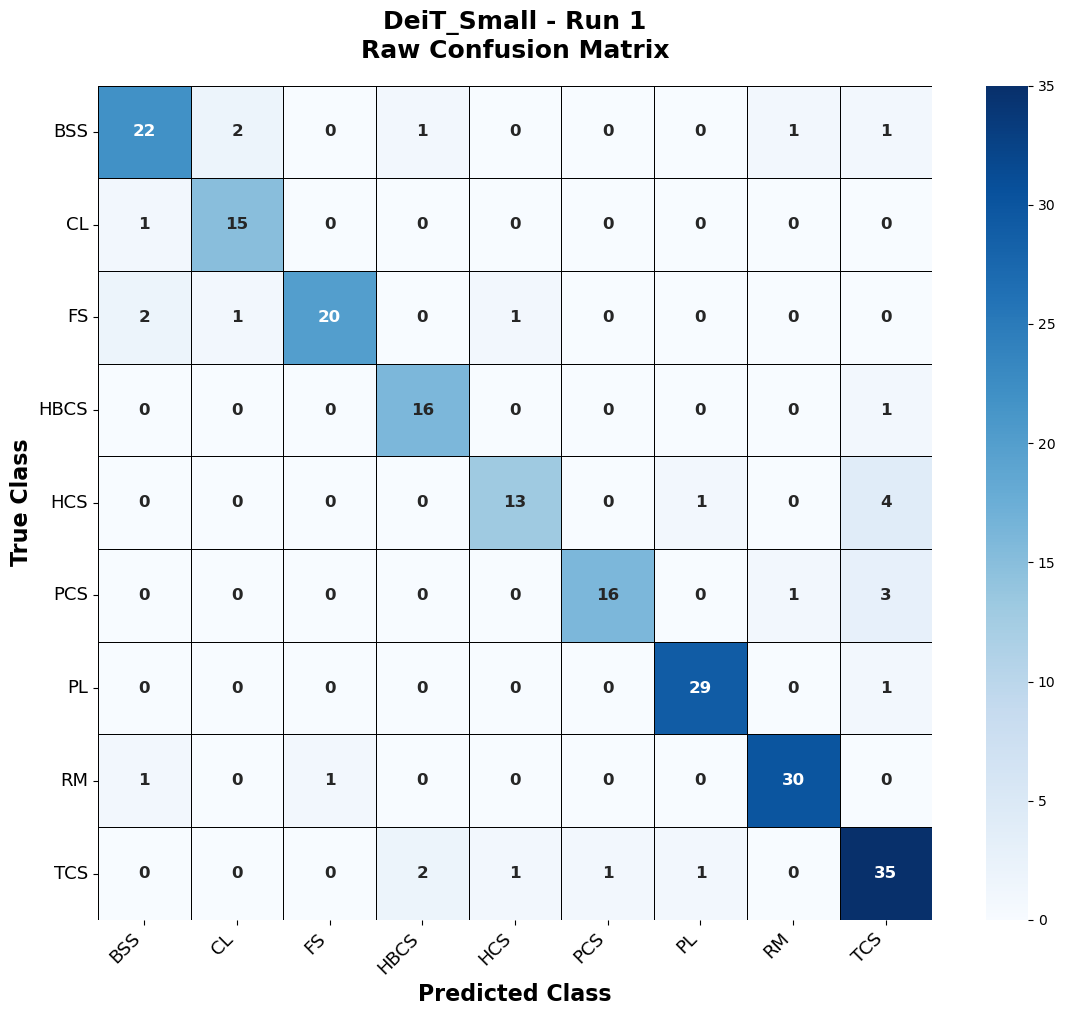

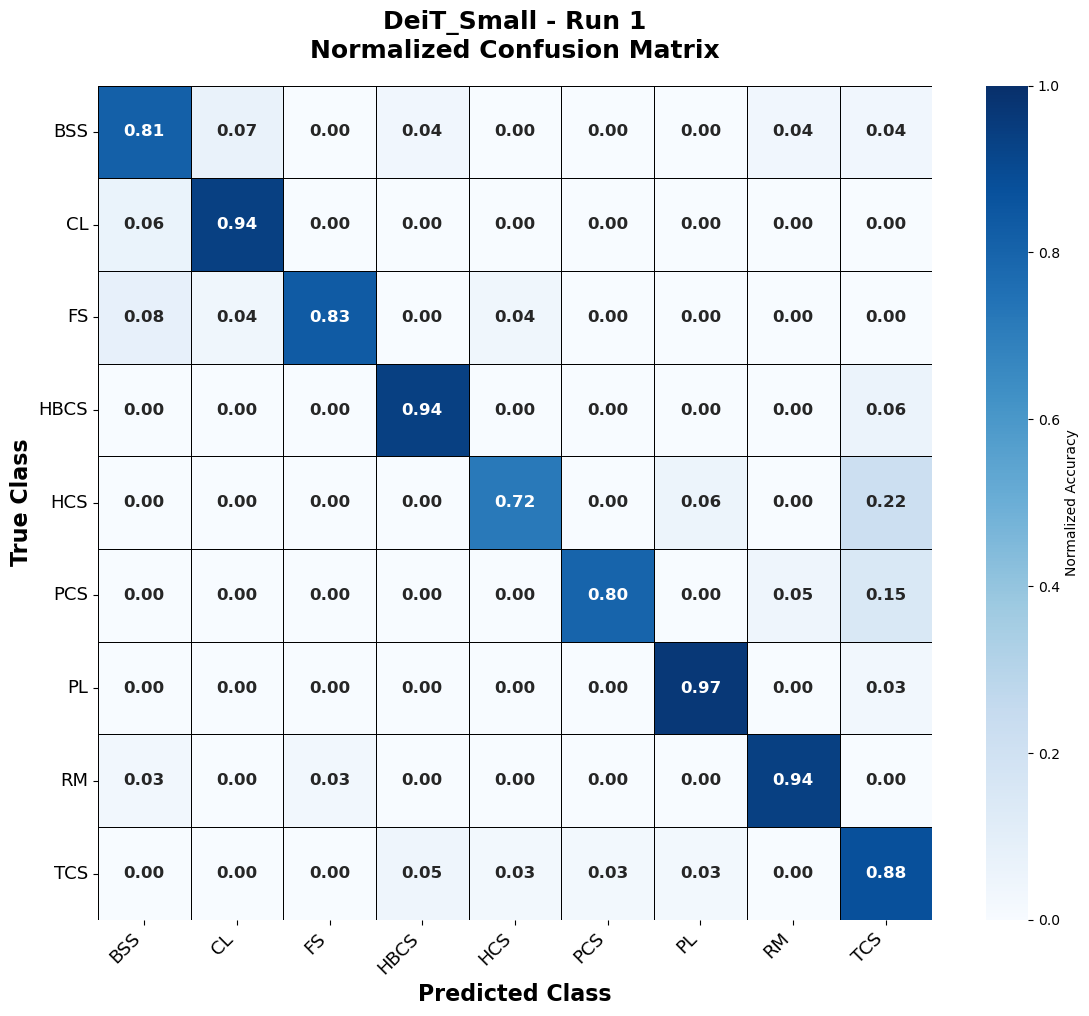


✓ Confusion matrices saved successfully

Files Saved Successfully
------------------------------------------------------------
Raw Confusion CSV          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\DeiT_Small_Run1_Raw.csv
Normalized Confusion CSV   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\DeiT_Small_Run1_Normalized.csv
Raw Confusion PNG          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\DeiT_Small_Run1_Raw.png
Normalized Confusion PNG   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\DeiT_Small_Run1_Normalized.png
Most Confused Classes CSV  : C:\Users\Frontech\Desktop\Codes\Combined 

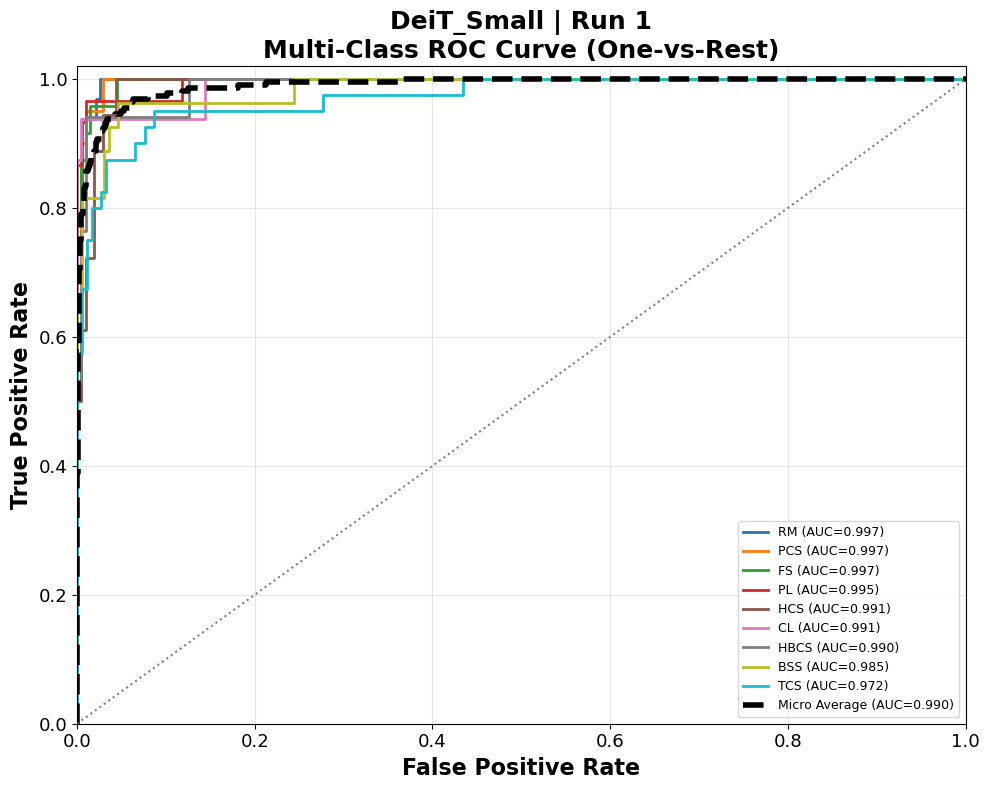


AUC Values
--------------------------------------------------------------------------------
               Class       AUC  Performance
0                 RM  0.997396  Outstanding
1                PCS  0.997304  Outstanding
2                 FS  0.996667  Outstanding
3                 PL  0.995361  Outstanding
4                HCS  0.991100  Outstanding
5                 CL  0.990685  Outstanding
6               HBCS  0.989770    Excellent
7                BSS  0.984960    Excellent
8                TCS  0.972011    Excellent
9      Micro Average  0.989978      Summary
10     Macro Average  0.990584      Summary
11  Weighted Average  0.989441      Summary

ROC Summary
--------------------------------------------------------------------------------
Number of Classes           : 9
Excellent ROC (AUC ≥ 0.90)  : 9/9

Best Class                  : RM (Outstanding)
Best AUC                    : 0.9974

Worst Class                 : TCS (Excellent)
Worst AUC                   : 0.9720

Micro

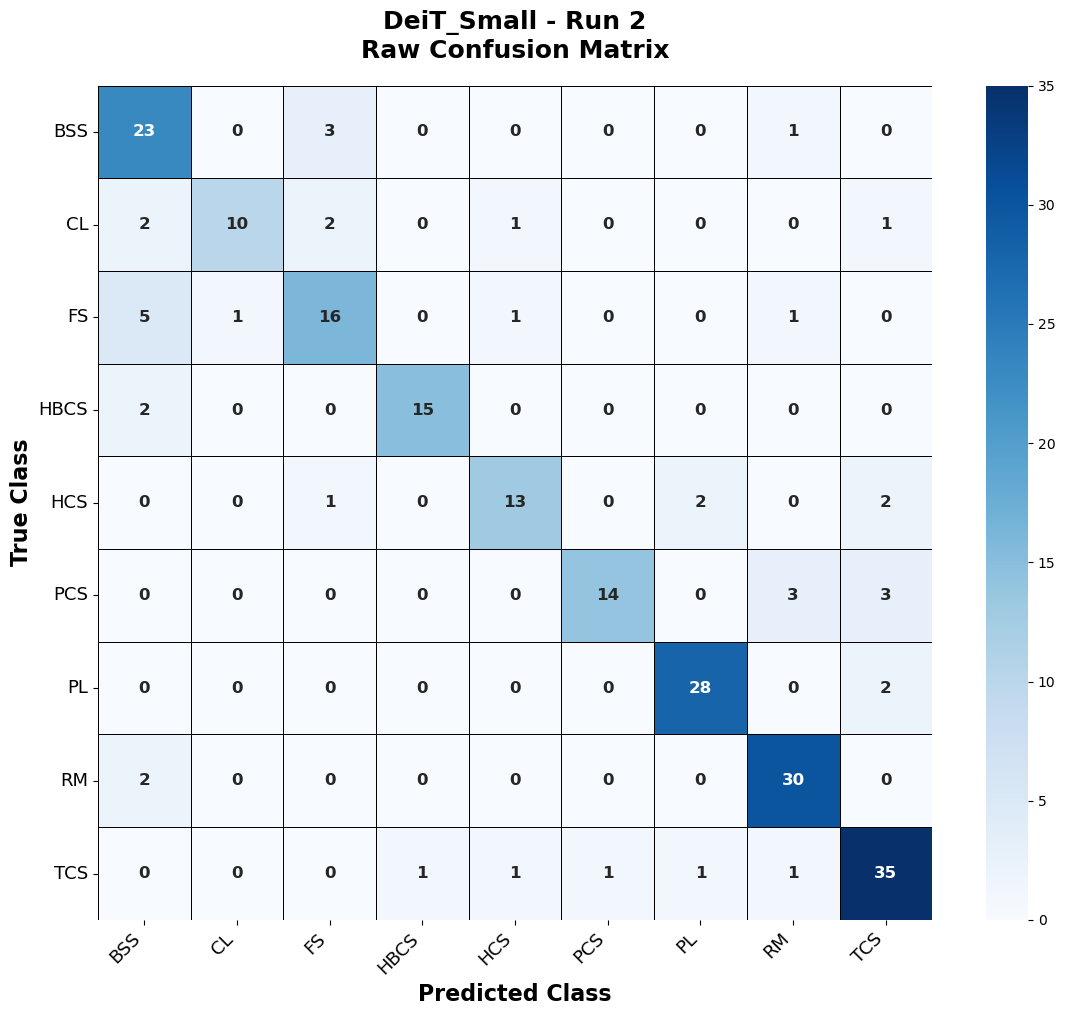

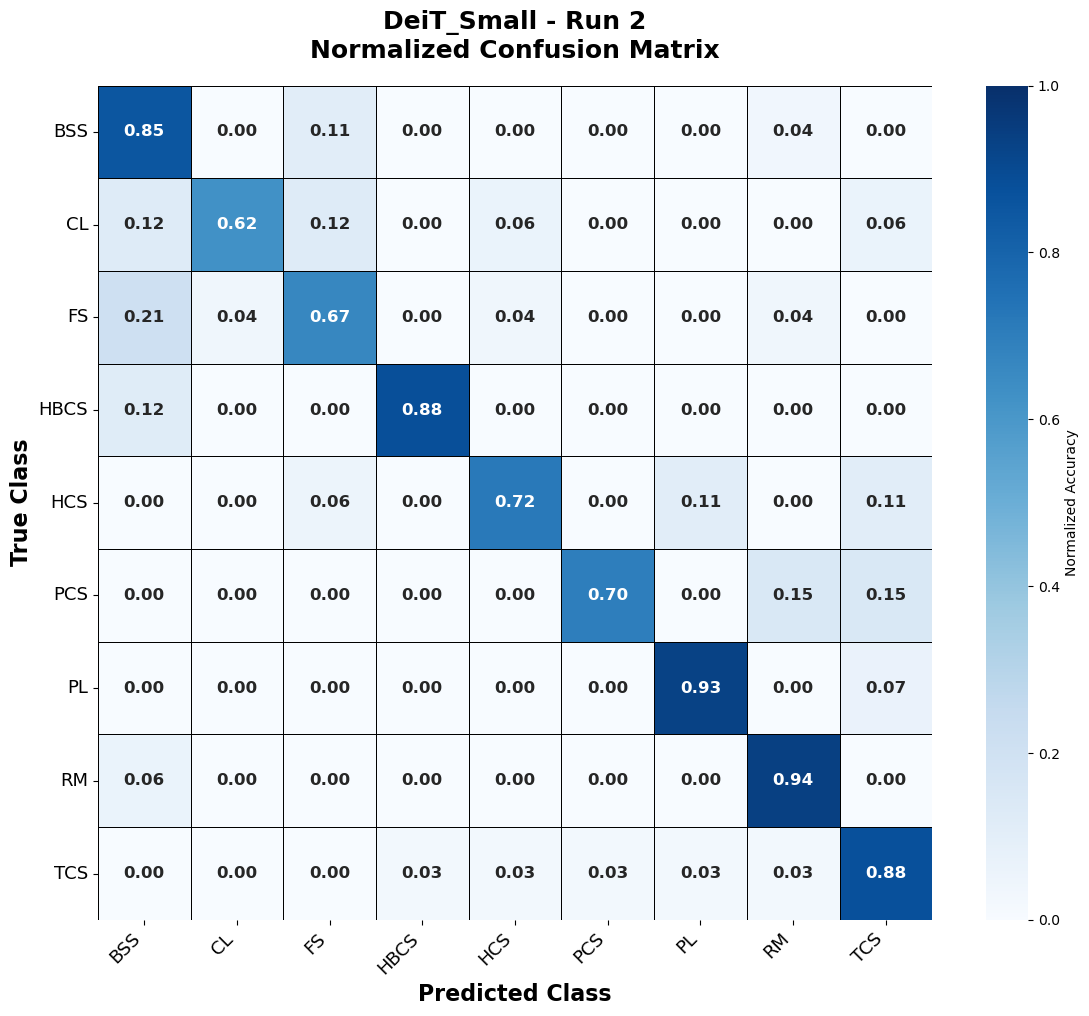


✓ Confusion matrices saved successfully

Files Saved Successfully
------------------------------------------------------------
Raw Confusion CSV          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\DeiT_Small_Run2_Raw.csv
Normalized Confusion CSV   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\DeiT_Small_Run2_Normalized.csv
Raw Confusion PNG          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\DeiT_Small_Run2_Raw.png
Normalized Confusion PNG   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\DeiT_Small_Run2_Normalized.png
Most Confused Classes CSV  : C:\Users\Frontech\Desktop\Codes\Combined 

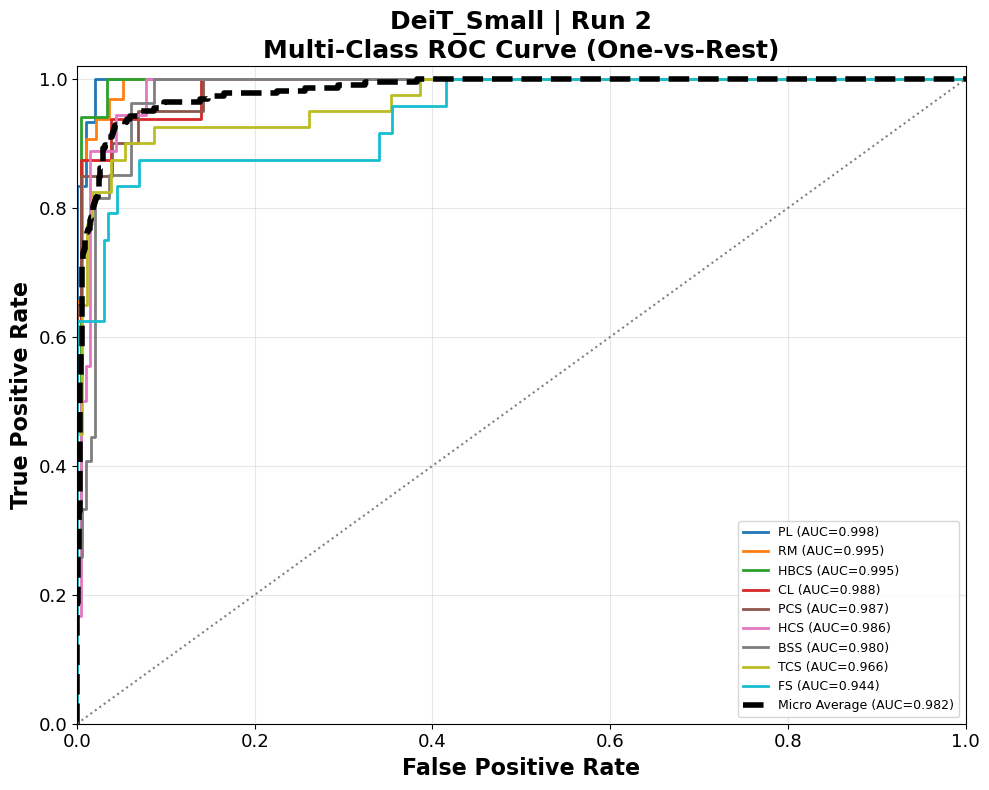


AUC Values
--------------------------------------------------------------------------------
               Class       AUC  Performance
0                 PL  0.997595  Outstanding
1                 RM  0.995117  Outstanding
2               HBCS  0.994885  Outstanding
3                 CL  0.987680    Excellent
4                PCS  0.986520    Excellent
5                HCS  0.986246    Excellent
6                BSS  0.979507    Excellent
7                TCS  0.966304    Excellent
8                 FS  0.943750    Excellent
9      Micro Average  0.982091      Summary
10     Macro Average  0.981956      Summary
11  Weighted Average  0.980889      Summary

ROC Summary
--------------------------------------------------------------------------------
Number of Classes           : 9
Excellent ROC (AUC ≥ 0.90)  : 9/9

Best Class                  : PL (Outstanding)
Best AUC                    : 0.9976

Worst Class                 : FS (Excellent)
Worst AUC                   : 0.9437

Micro 

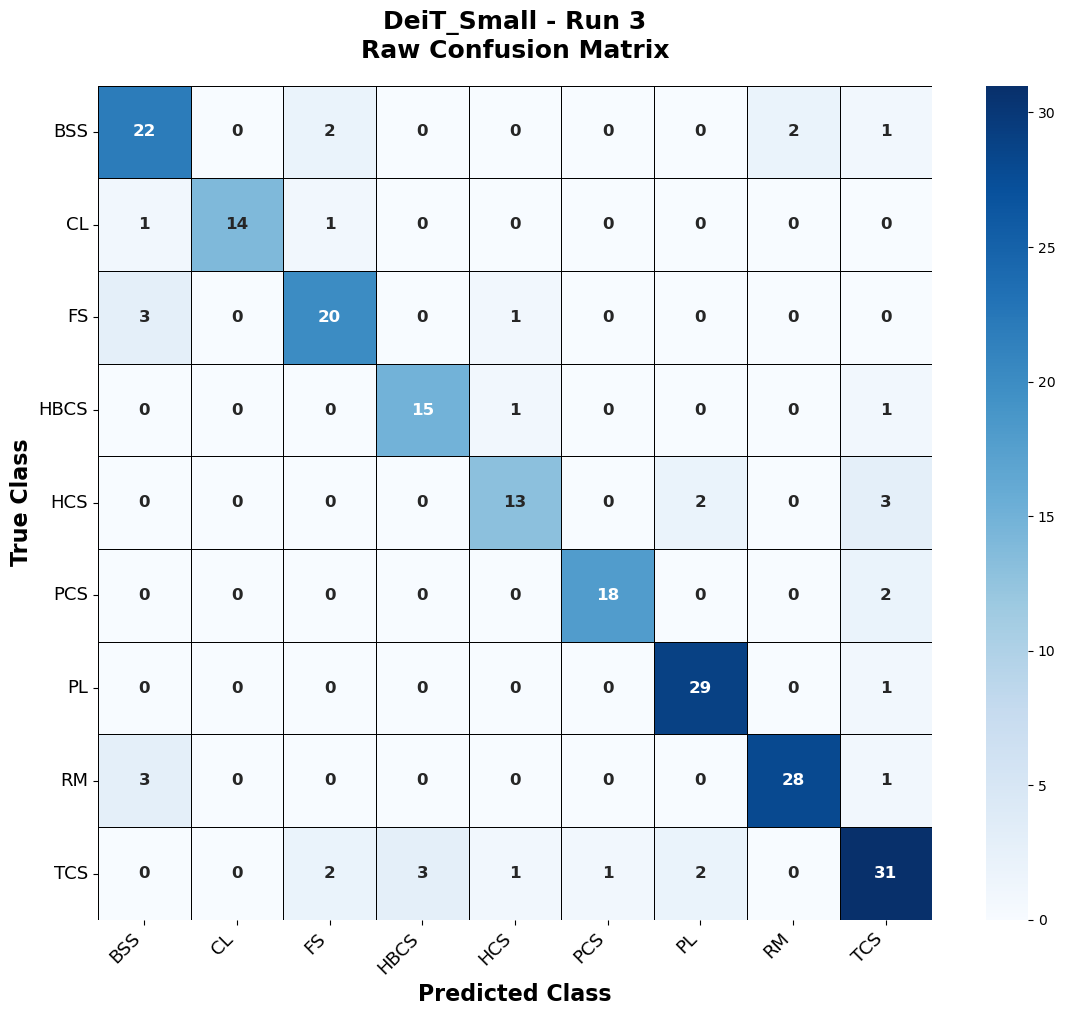

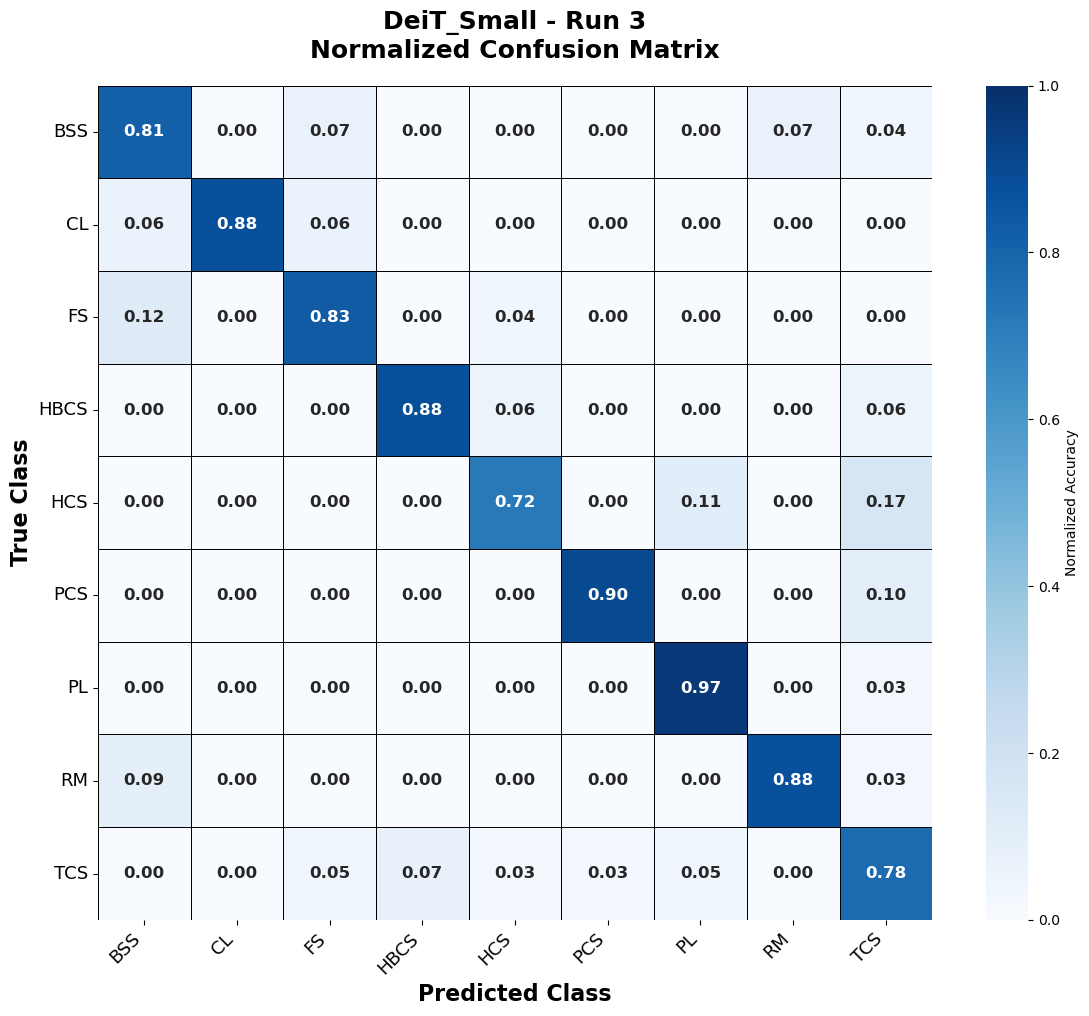


✓ Confusion matrices saved successfully

Files Saved Successfully
------------------------------------------------------------
Raw Confusion CSV          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\DeiT_Small_Run3_Raw.csv
Normalized Confusion CSV   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\DeiT_Small_Run3_Normalized.csv
Raw Confusion PNG          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\DeiT_Small_Run3_Raw.png
Normalized Confusion PNG   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\DeiT_Small_Run3_Normalized.png
Most Confused Classes CSV  : C:\Users\Frontech\Desktop\Codes\Combined 

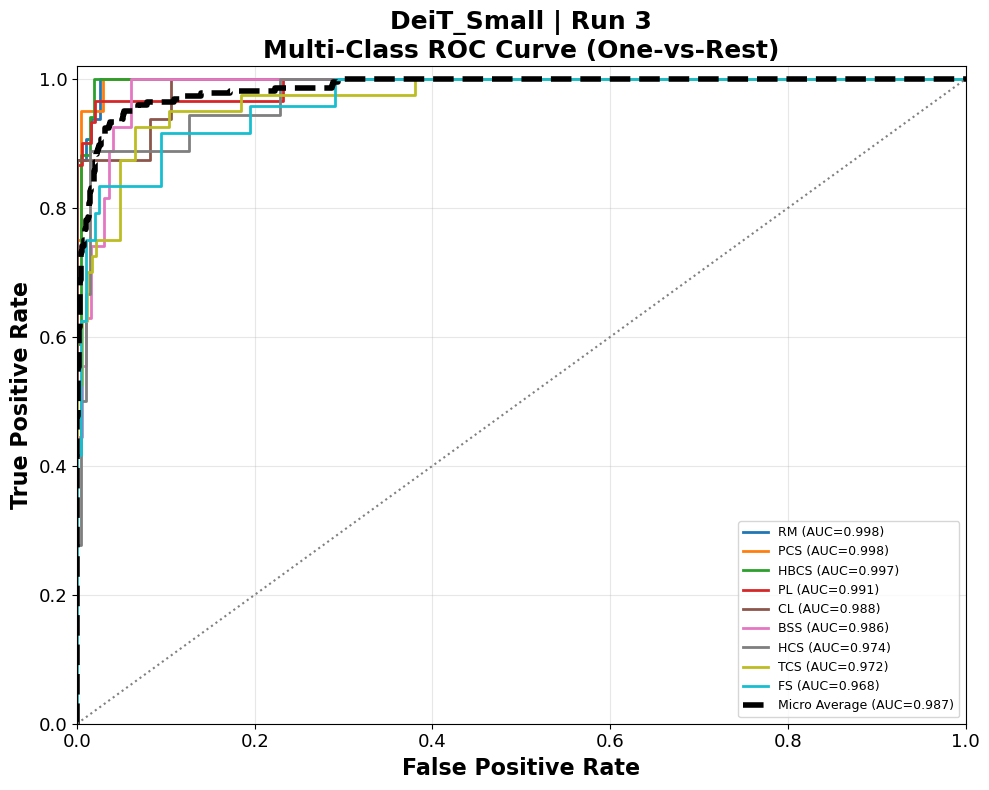


AUC Values
--------------------------------------------------------------------------------
               Class       AUC  Performance
0                 RM  0.997559  Outstanding
1                PCS  0.997549  Outstanding
2               HBCS  0.996590  Outstanding
3                 PL  0.990893  Outstanding
4                 CL  0.988281    Excellent
5                BSS  0.986088    Excellent
6                HCS  0.974380    Excellent
7                TCS  0.971603    Excellent
8                 FS  0.967708    Excellent
9      Micro Average  0.986627      Summary
10     Macro Average  0.985628      Summary
11  Weighted Average  0.984851      Summary

ROC Summary
--------------------------------------------------------------------------------
Number of Classes           : 9
Excellent ROC (AUC ≥ 0.90)  : 9/9

Best Class                  : RM (Outstanding)
Best AUC                    : 0.9976

Worst Class                 : FS (Excellent)
Worst AUC                   : 0.9677

Micro 

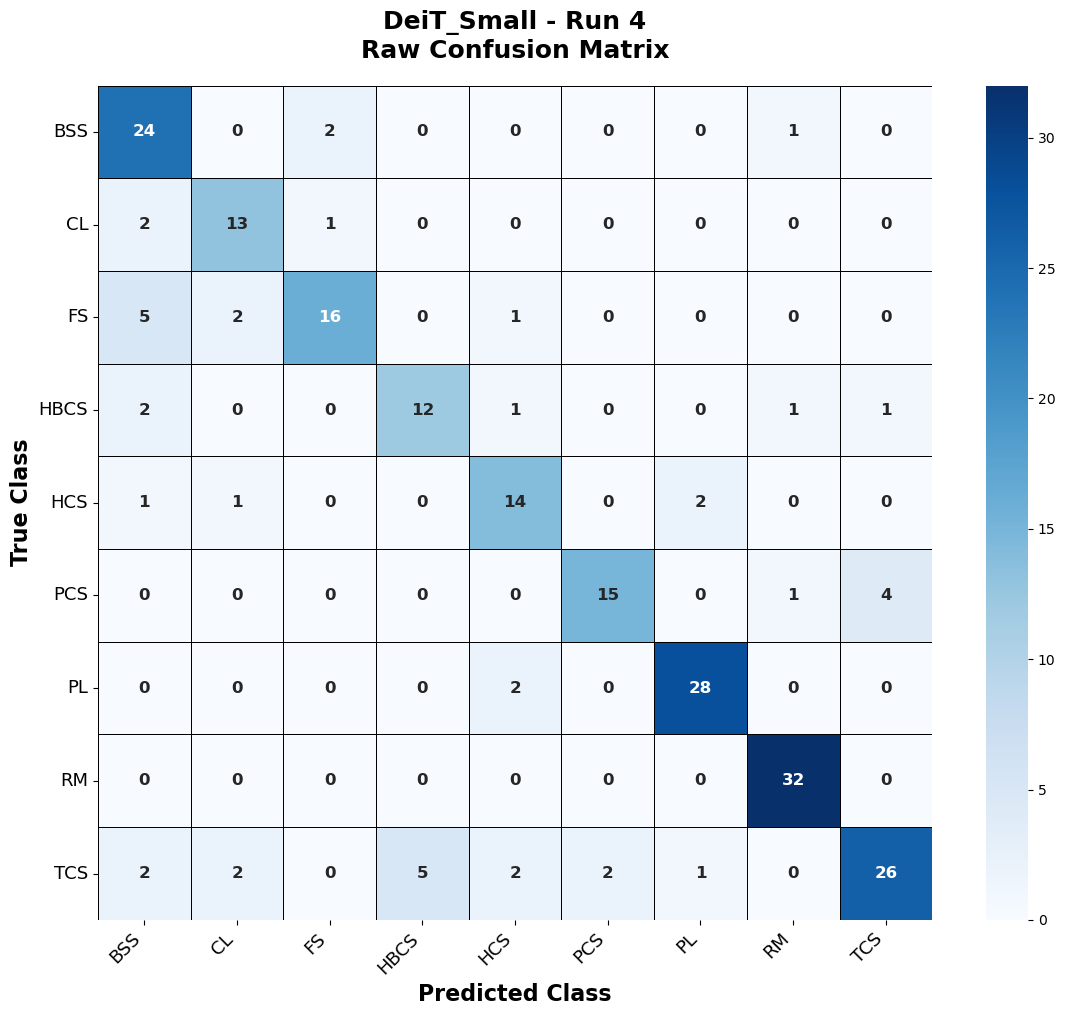

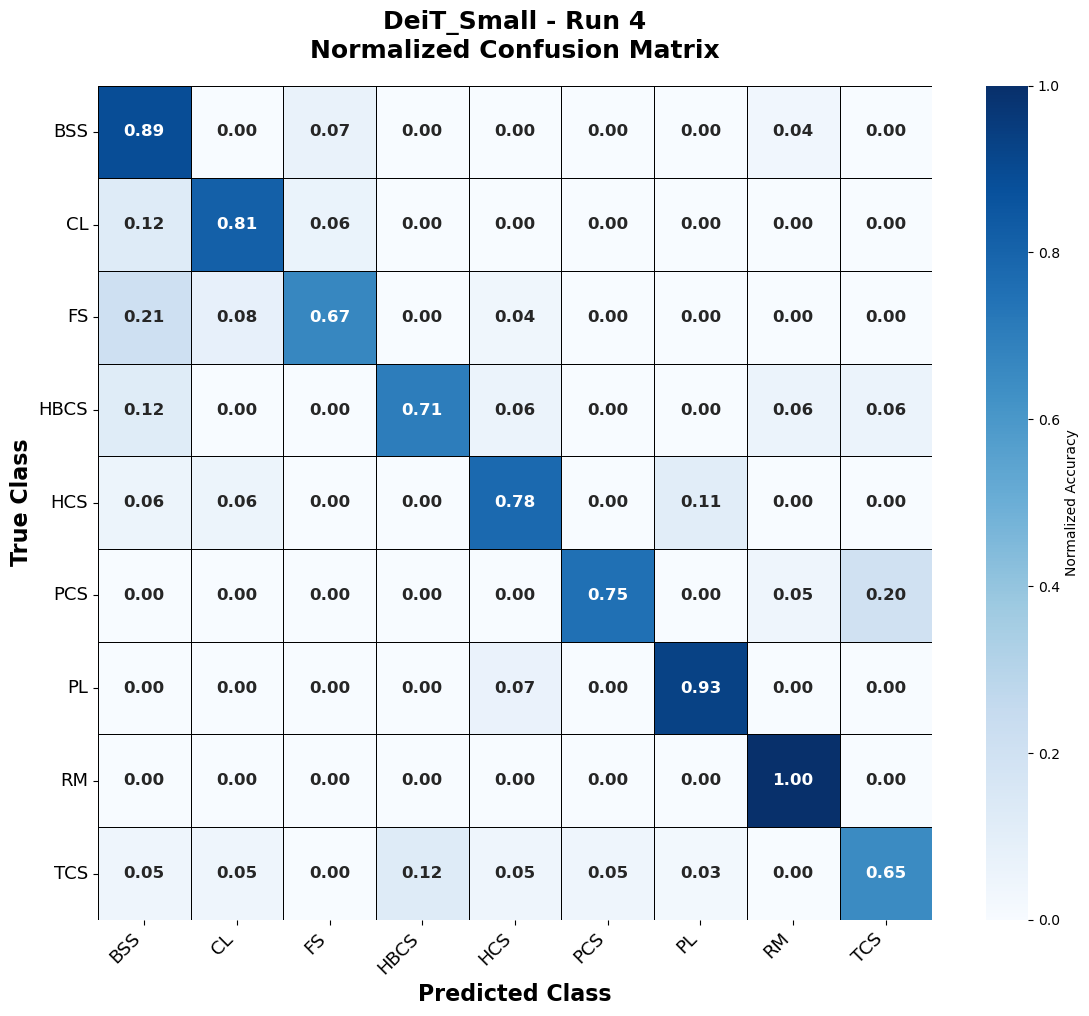


✓ Confusion matrices saved successfully

Files Saved Successfully
------------------------------------------------------------
Raw Confusion CSV          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\DeiT_Small_Run4_Raw.csv
Normalized Confusion CSV   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\DeiT_Small_Run4_Normalized.csv
Raw Confusion PNG          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\DeiT_Small_Run4_Raw.png
Normalized Confusion PNG   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\DeiT_Small_Run4_Normalized.png
Most Confused Classes CSV  : C:\Users\Frontech\Desktop\Codes\Combined 

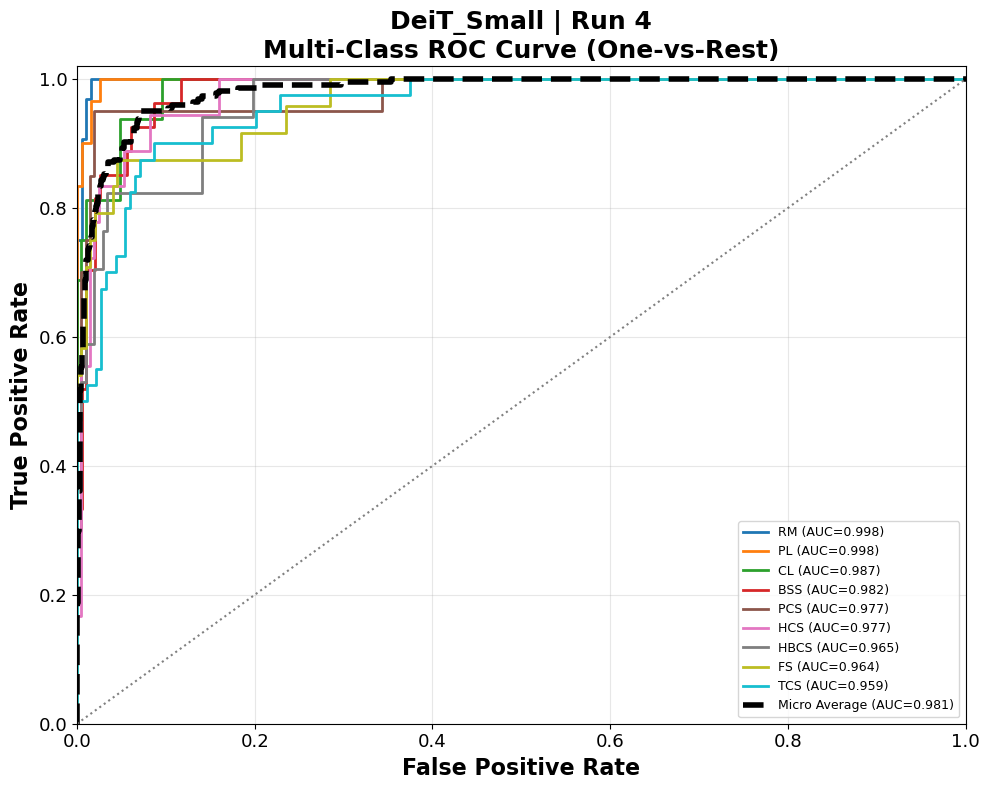


AUC Values
--------------------------------------------------------------------------------
               Class       AUC  Performance
0                 RM  0.998047  Outstanding
1                 PL  0.997766  Outstanding
2                 CL  0.987079    Excellent
3                BSS  0.982139    Excellent
4                PCS  0.976961    Excellent
5                HCS  0.976807    Excellent
6               HBCS  0.965047    Excellent
7                 FS  0.964167    Excellent
8                TCS  0.958832    Excellent
9      Micro Average  0.980922      Summary
10     Macro Average  0.978538      Summary
11  Weighted Average  0.978582      Summary

ROC Summary
--------------------------------------------------------------------------------
Number of Classes           : 9
Excellent ROC (AUC ≥ 0.90)  : 9/9

Best Class                  : RM (Outstanding)
Best AUC                    : 0.9980

Worst Class                 : TCS (Excellent)
Worst AUC                   : 0.9588

Micro

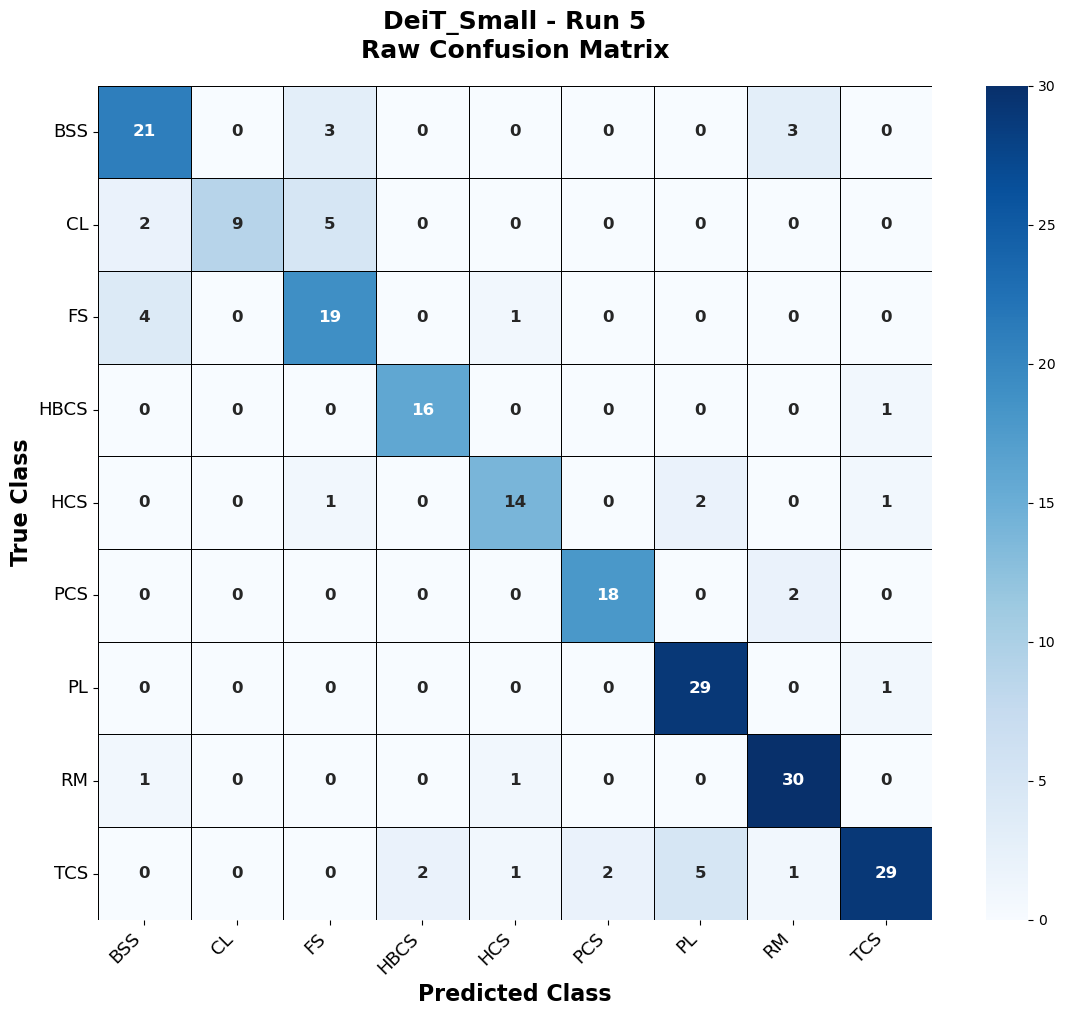

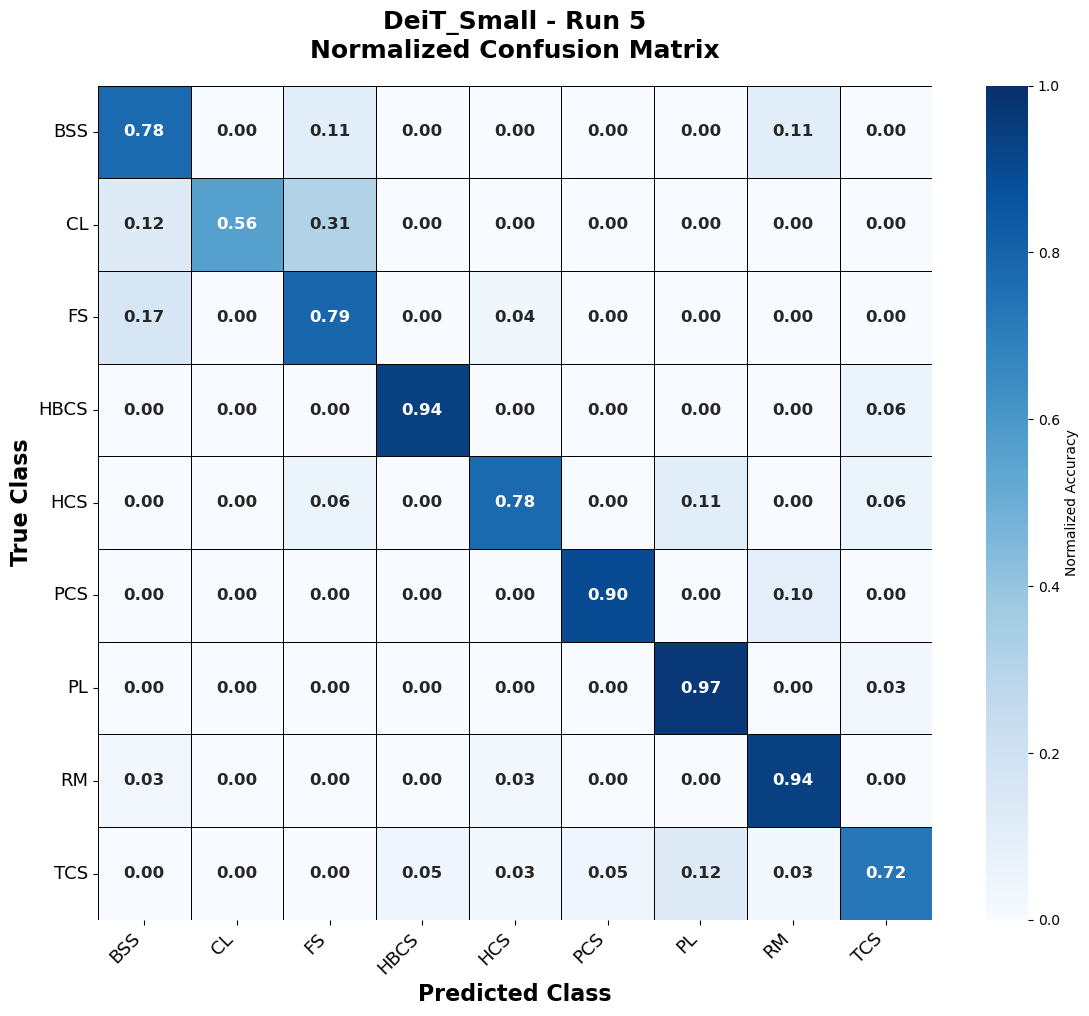


✓ Confusion matrices saved successfully

Files Saved Successfully
------------------------------------------------------------
Raw Confusion CSV          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\DeiT_Small_Run5_Raw.csv
Normalized Confusion CSV   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\DeiT_Small_Run5_Normalized.csv
Raw Confusion PNG          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\DeiT_Small_Run5_Raw.png
Normalized Confusion PNG   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\DeiT_Small_Run5_Normalized.png
Most Confused Classes CSV  : C:\Users\Frontech\Desktop\Codes\Combined 

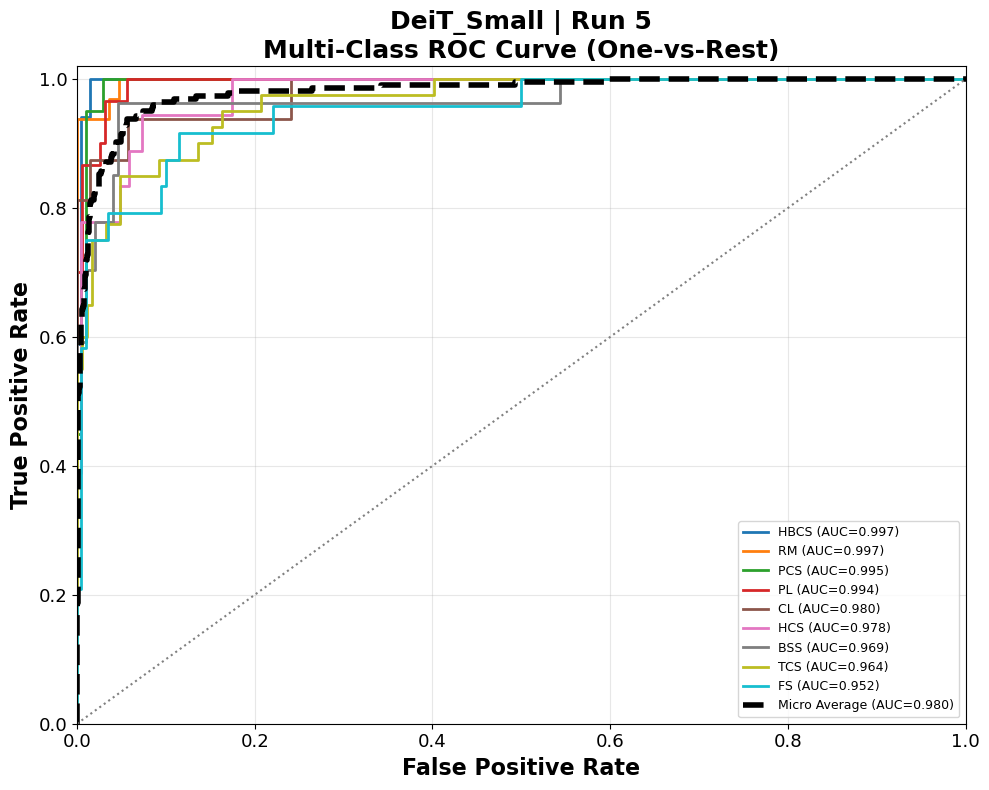


AUC Values
--------------------------------------------------------------------------------
               Class       AUC  Performance
0               HBCS  0.997442  Outstanding
1                 RM  0.997396  Outstanding
2                PCS  0.994853  Outstanding
3                 PL  0.994330  Outstanding
4                 CL  0.980469    Excellent
5                HCS  0.978425    Excellent
6                BSS  0.969167    Excellent
7                TCS  0.964266    Excellent
8                 FS  0.952083    Excellent
9      Micro Average  0.980372      Summary
10     Macro Average  0.980937      Summary
11  Weighted Average  0.979855      Summary

ROC Summary
--------------------------------------------------------------------------------
Number of Classes           : 9
Excellent ROC (AUC ≥ 0.90)  : 9/9

Best Class                  : HBCS (Outstanding)
Best AUC                    : 0.9974

Worst Class                 : FS (Excellent)
Worst AUC                   : 0.9521

Micr

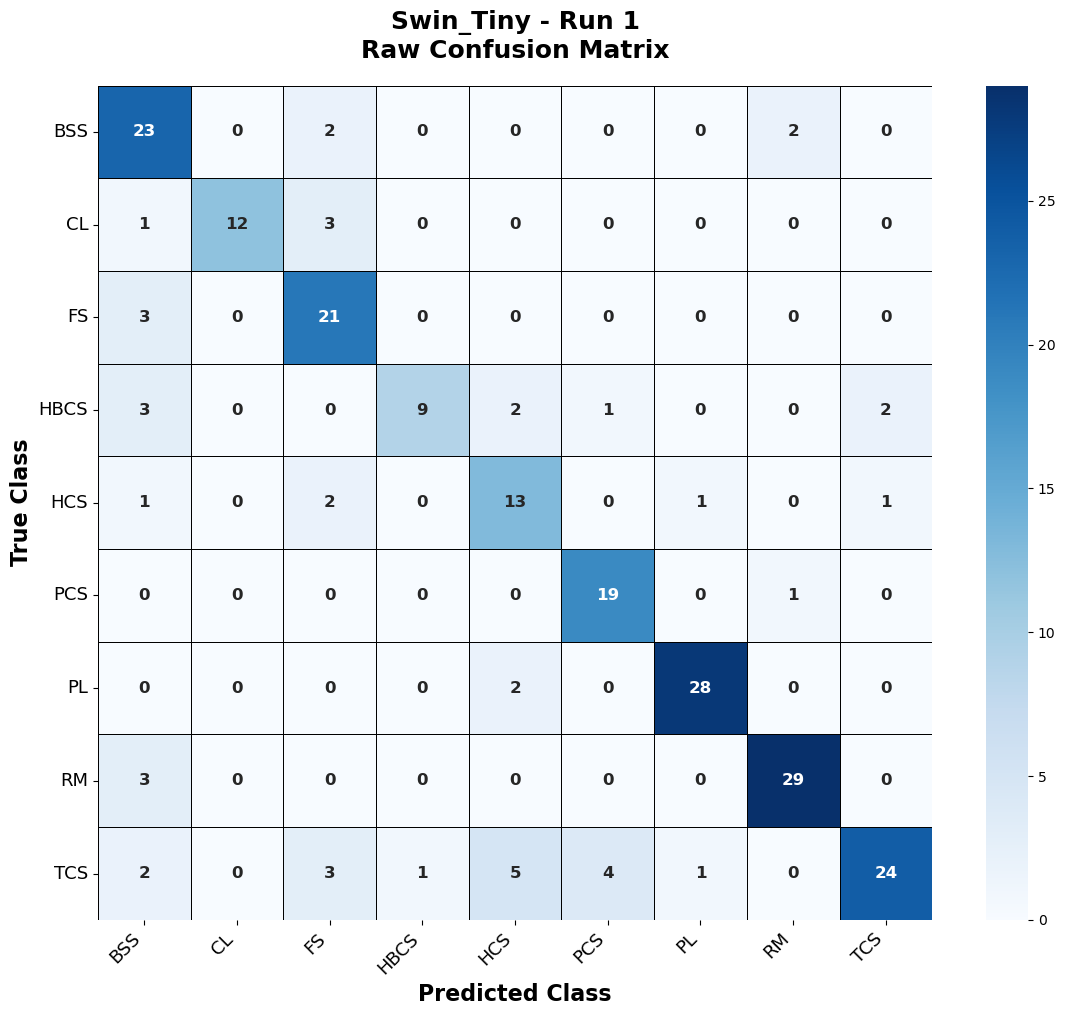

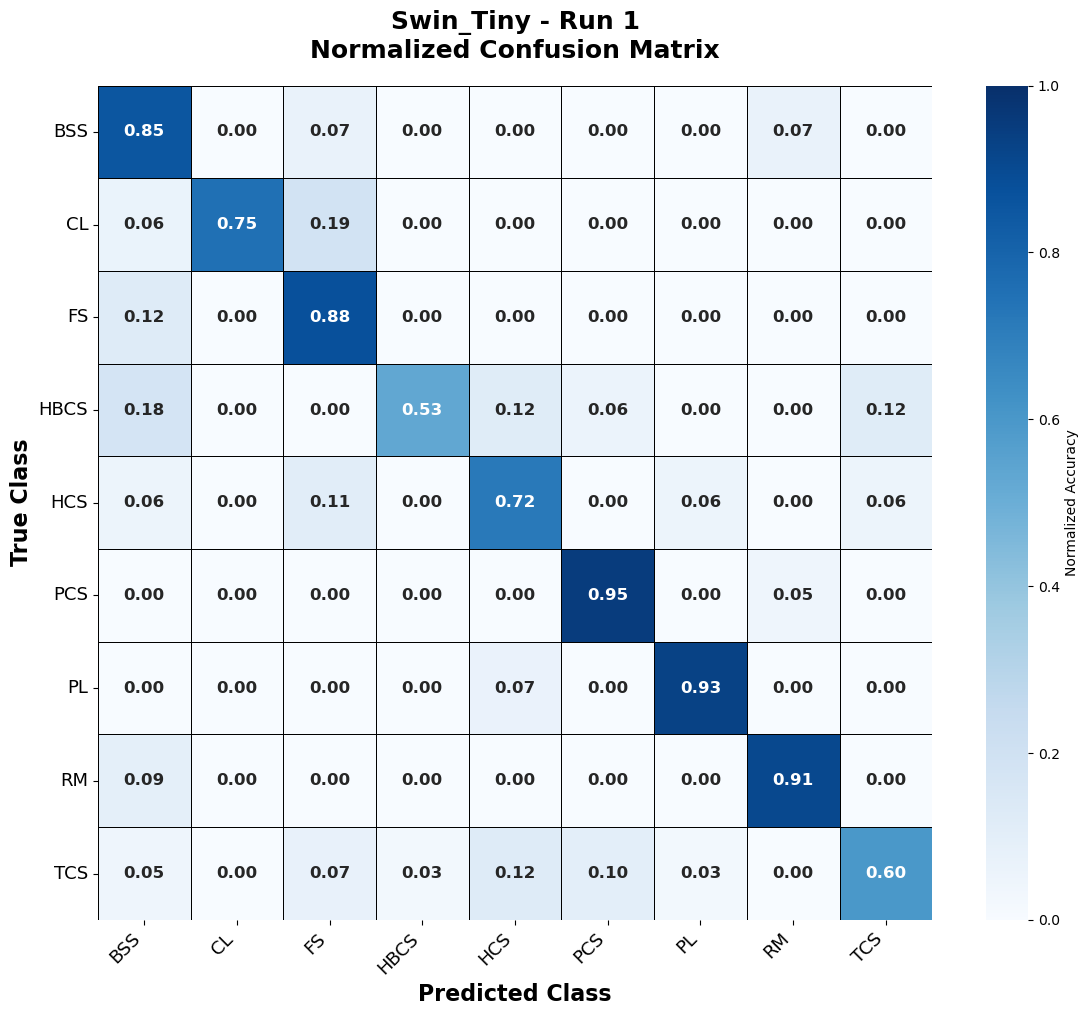


✓ Confusion matrices saved successfully

Files Saved Successfully
------------------------------------------------------------
Raw Confusion CSV          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\Swin_Tiny_Run1_Raw.csv
Normalized Confusion CSV   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\Swin_Tiny_Run1_Normalized.csv
Raw Confusion PNG          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\Swin_Tiny_Run1_Raw.png
Normalized Confusion PNG   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\Swin_Tiny_Run1_Normalized.png
Most Confused Classes CSV  : C:\Users\Frontech\Desktop\Codes\Combined Data

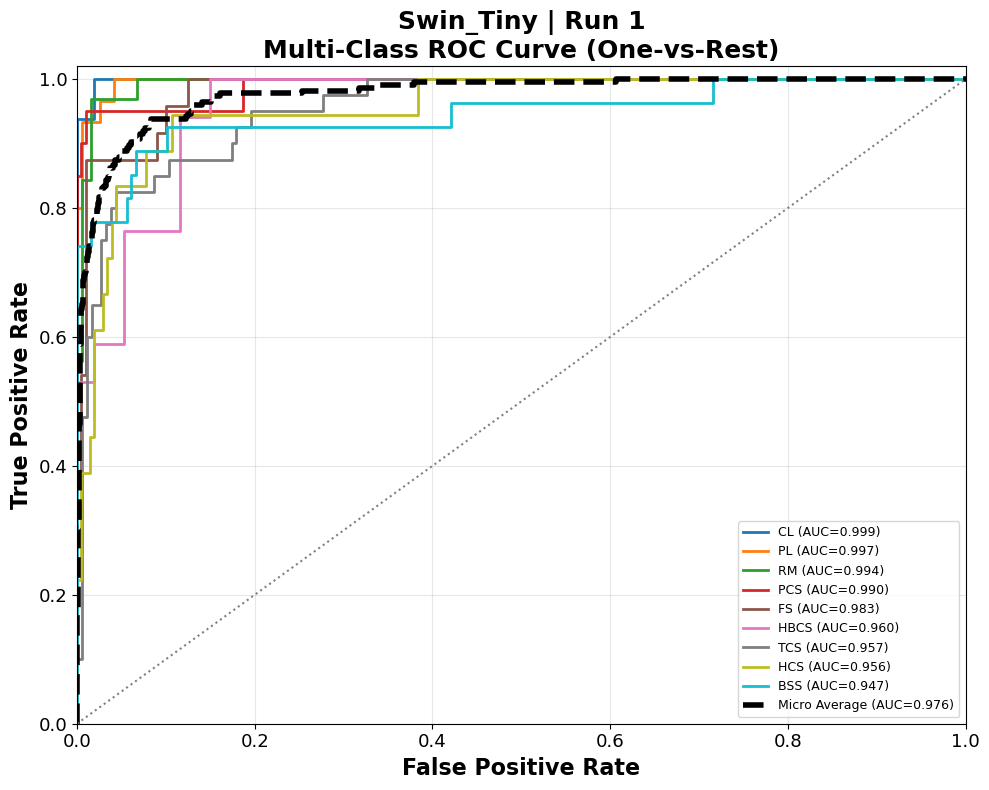


AUC Values
--------------------------------------------------------------------------------
               Class       AUC  Performance
0                 CL  0.998798  Outstanding
1                 PL  0.997079  Outstanding
2                 RM  0.994466  Outstanding
3                PCS  0.989951    Excellent
4                 FS  0.982708    Excellent
5               HBCS  0.960216    Excellent
6                TCS  0.956658    Excellent
7                HCS  0.955502    Excellent
8                BSS  0.946795    Excellent
9      Micro Average  0.976363      Summary
10     Macro Average  0.975797      Summary
11  Weighted Average  0.975235      Summary

ROC Summary
--------------------------------------------------------------------------------
Number of Classes           : 9
Excellent ROC (AUC ≥ 0.90)  : 9/9

Best Class                  : CL (Outstanding)
Best AUC                    : 0.9988

Worst Class                 : BSS (Excellent)
Worst AUC                   : 0.9468

Micro

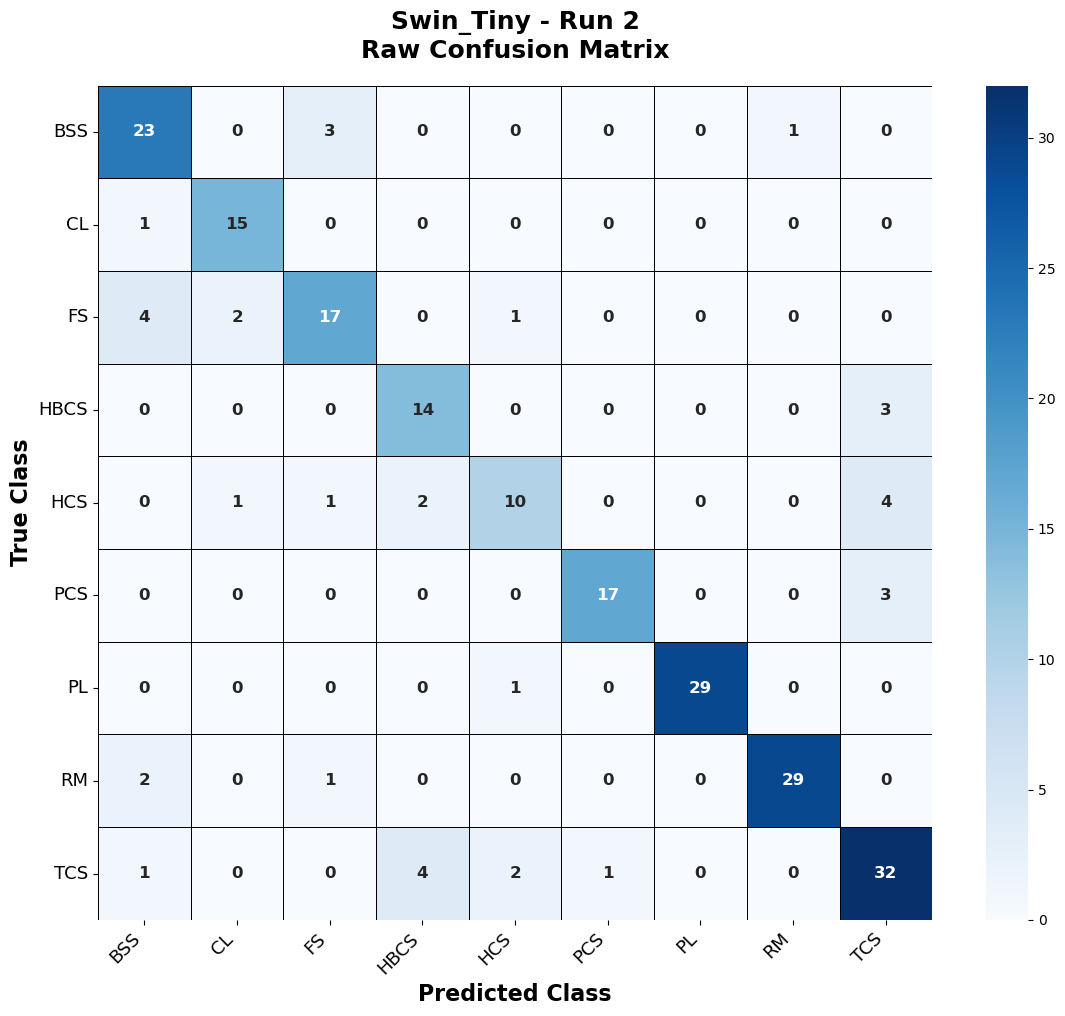

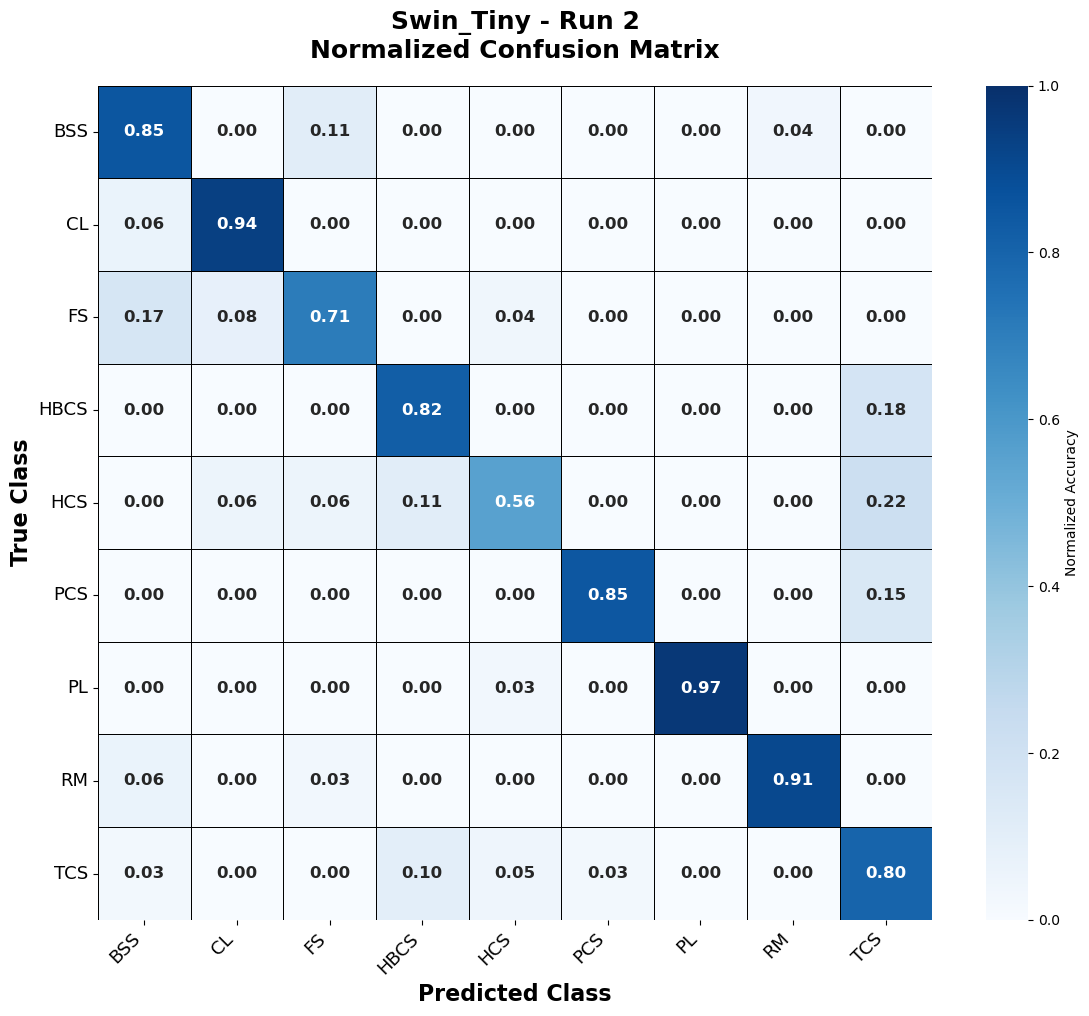


✓ Confusion matrices saved successfully

Files Saved Successfully
------------------------------------------------------------
Raw Confusion CSV          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\Swin_Tiny_Run2_Raw.csv
Normalized Confusion CSV   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\Swin_Tiny_Run2_Normalized.csv
Raw Confusion PNG          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\Swin_Tiny_Run2_Raw.png
Normalized Confusion PNG   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\Swin_Tiny_Run2_Normalized.png
Most Confused Classes CSV  : C:\Users\Frontech\Desktop\Codes\Combined Data

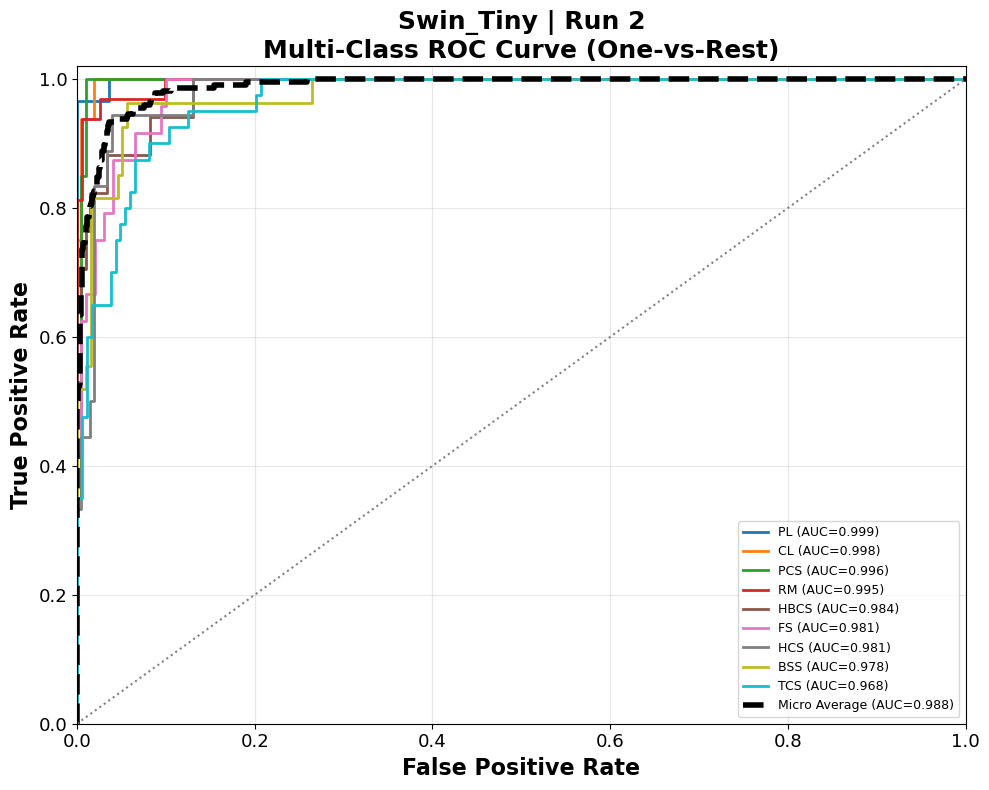


AUC Values
--------------------------------------------------------------------------------
               Class       AUC  Performance
0                 PL  0.998797  Outstanding
1                 CL  0.997897  Outstanding
2                PCS  0.996078  Outstanding
3                 RM  0.995443  Outstanding
4               HBCS  0.983802    Excellent
5                 FS  0.981458    Excellent
6                HCS  0.980852    Excellent
7                BSS  0.978379    Excellent
8                TCS  0.967799    Excellent
9      Micro Average  0.988157      Summary
10     Macro Average  0.986723      Summary
11  Weighted Average  0.985577      Summary

ROC Summary
--------------------------------------------------------------------------------
Number of Classes           : 9
Excellent ROC (AUC ≥ 0.90)  : 9/9

Best Class                  : PL (Outstanding)
Best AUC                    : 0.9988

Worst Class                 : TCS (Excellent)
Worst AUC                   : 0.9678

Micro

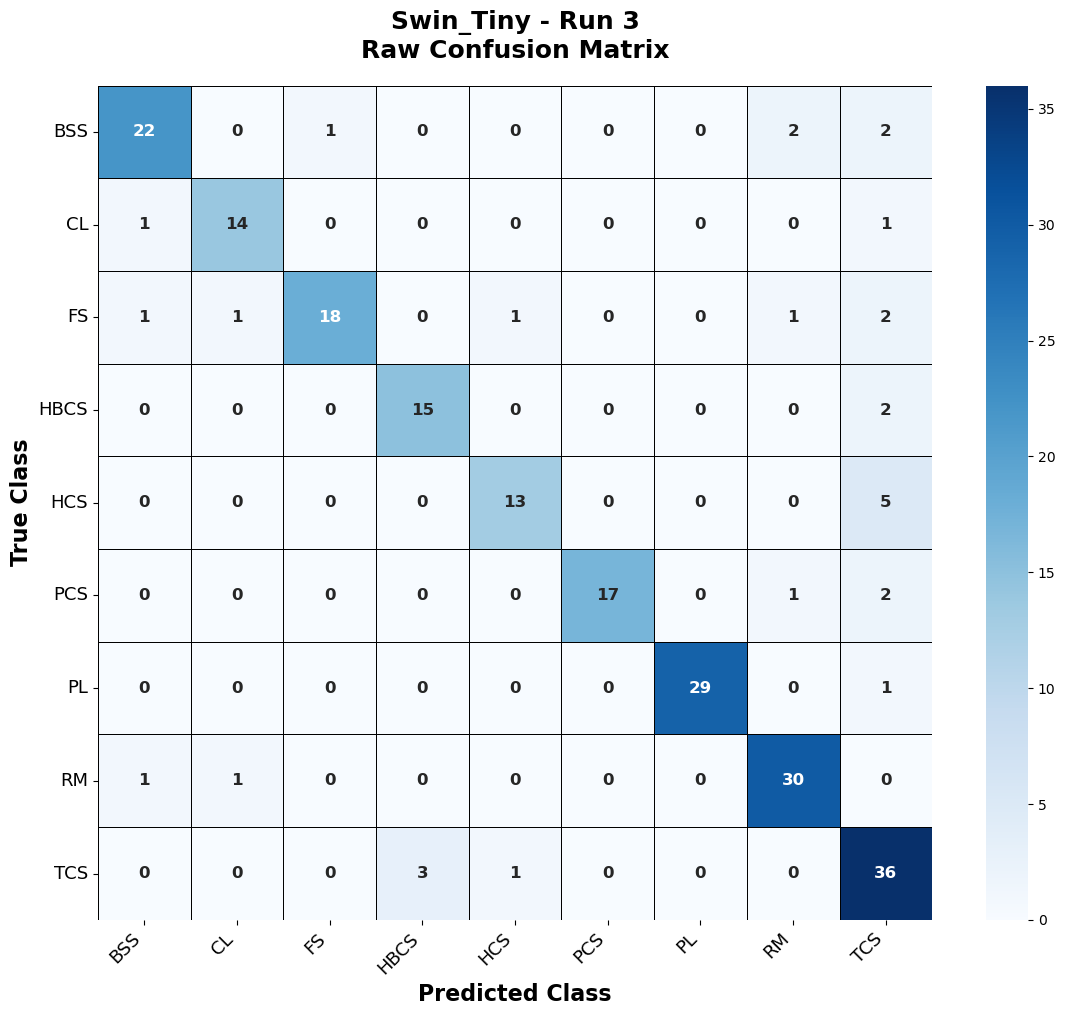

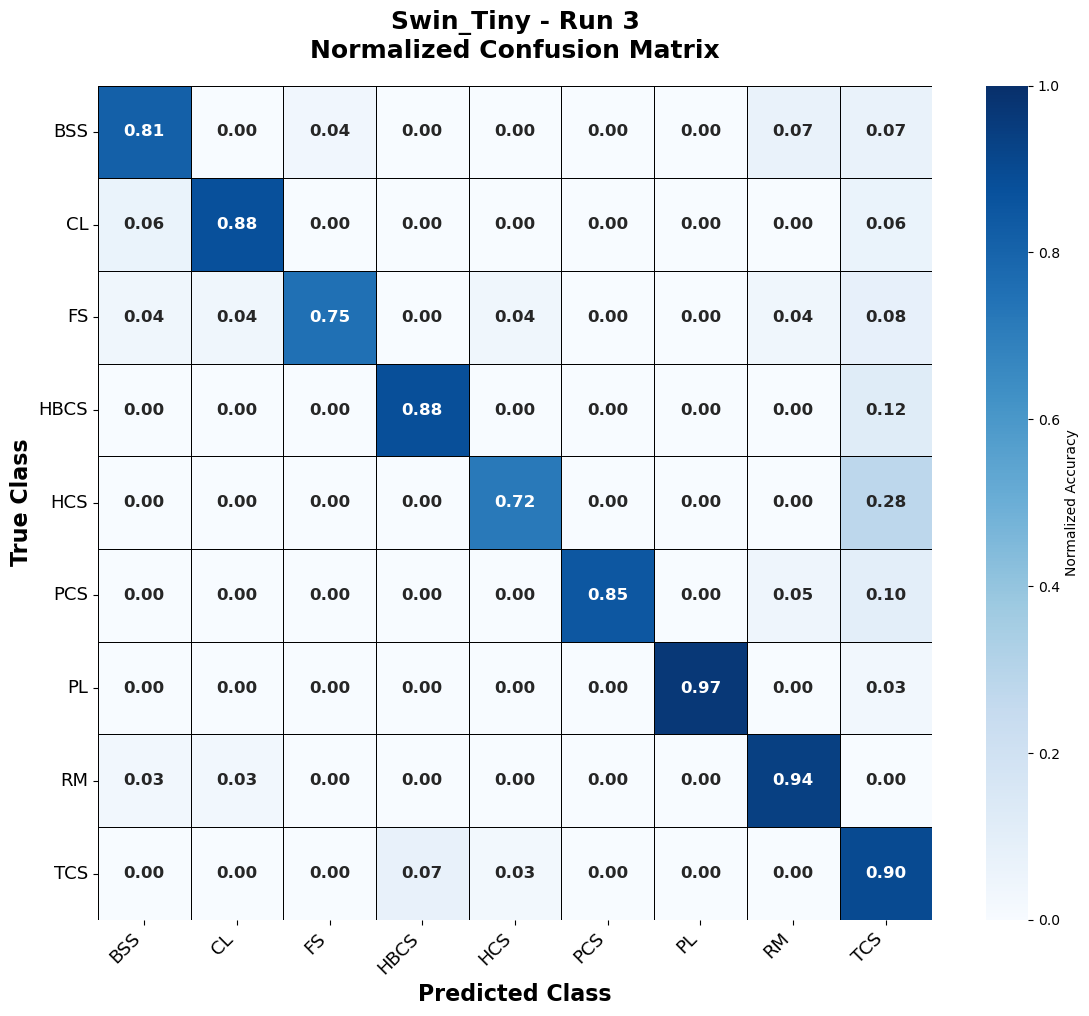


✓ Confusion matrices saved successfully

Files Saved Successfully
------------------------------------------------------------
Raw Confusion CSV          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\Swin_Tiny_Run3_Raw.csv
Normalized Confusion CSV   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\Swin_Tiny_Run3_Normalized.csv
Raw Confusion PNG          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\Swin_Tiny_Run3_Raw.png
Normalized Confusion PNG   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\Swin_Tiny_Run3_Normalized.png
Most Confused Classes CSV  : C:\Users\Frontech\Desktop\Codes\Combined Data

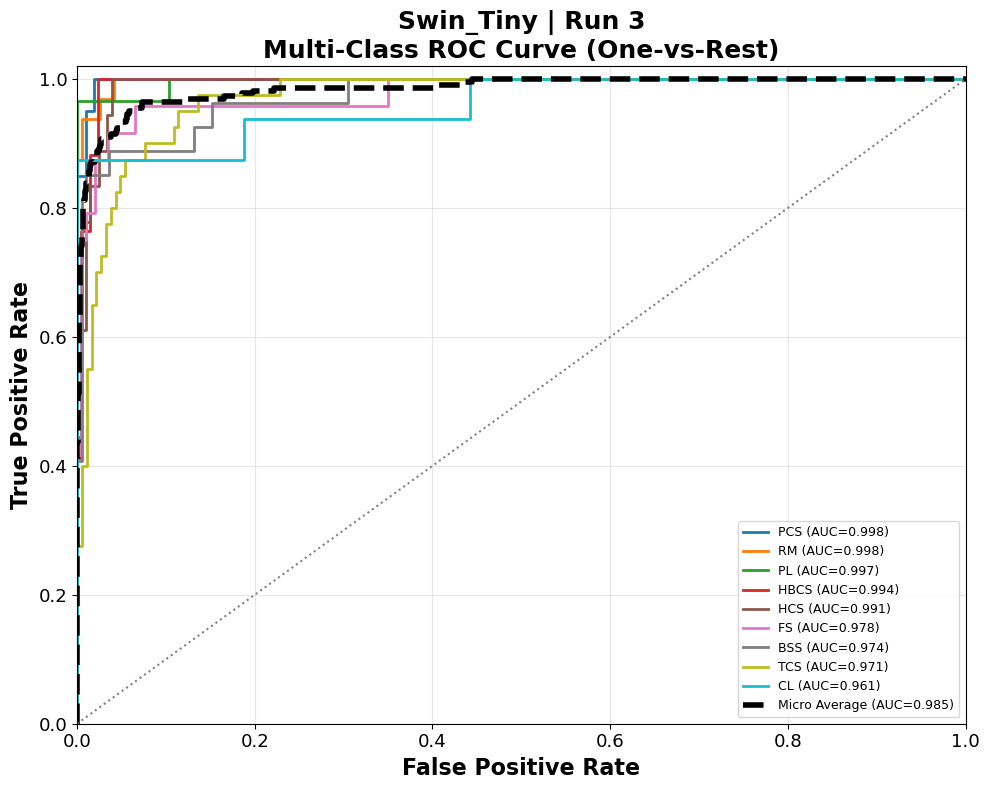


AUC Values
--------------------------------------------------------------------------------
               Class       AUC  Performance
0                PCS  0.998039  Outstanding
1                 RM  0.997559  Outstanding
2                 PL  0.996564  Outstanding
3               HBCS  0.993748  Outstanding
4                HCS  0.991370  Outstanding
5                 FS  0.977500    Excellent
6                BSS  0.974431    Excellent
7                TCS  0.971467    Excellent
8                 CL  0.960637    Excellent
9      Micro Average  0.984534      Summary
10     Macro Average  0.984591      Summary
11  Weighted Average  0.984449      Summary

ROC Summary
--------------------------------------------------------------------------------
Number of Classes           : 9
Excellent ROC (AUC ≥ 0.90)  : 9/9

Best Class                  : PCS (Outstanding)
Best AUC                    : 0.9980

Worst Class                 : CL (Excellent)
Worst AUC                   : 0.9606

Micro

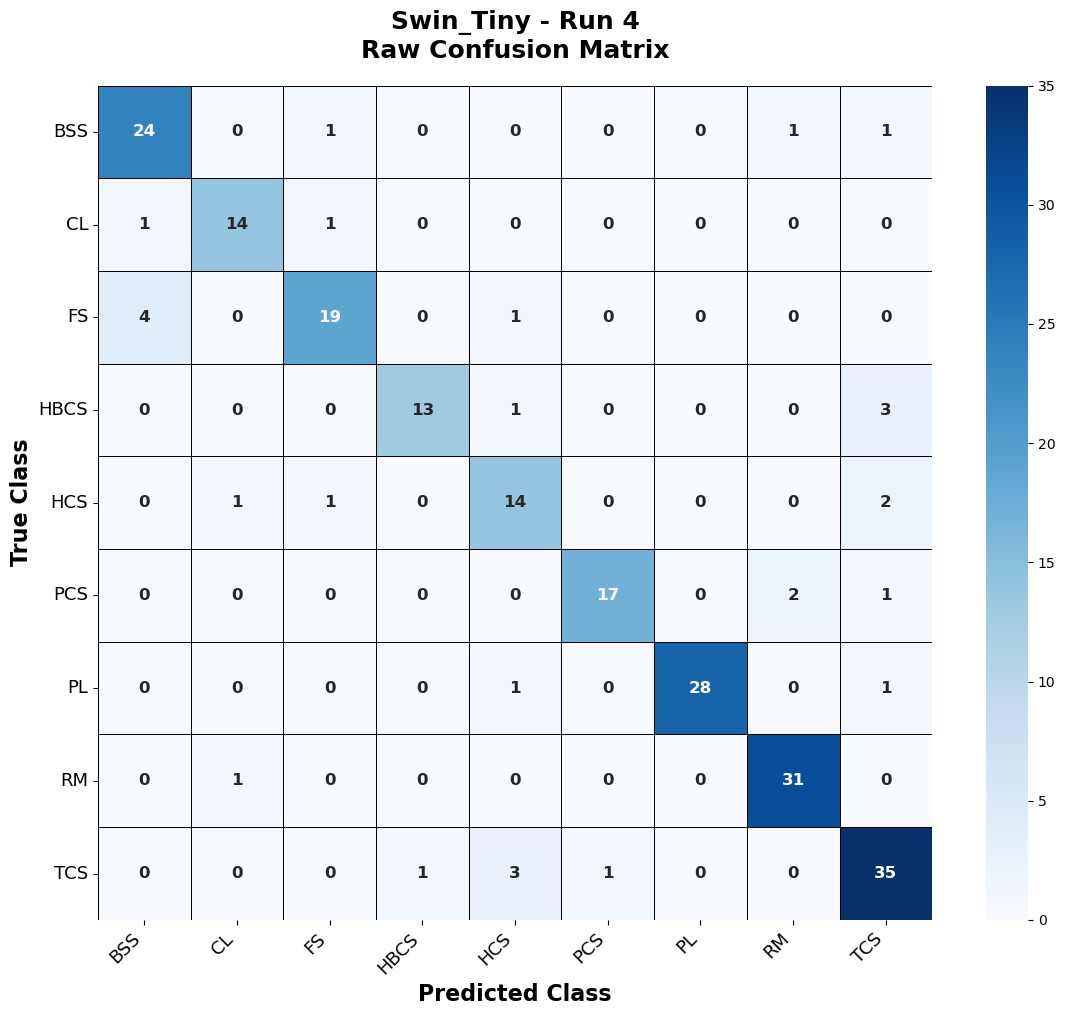

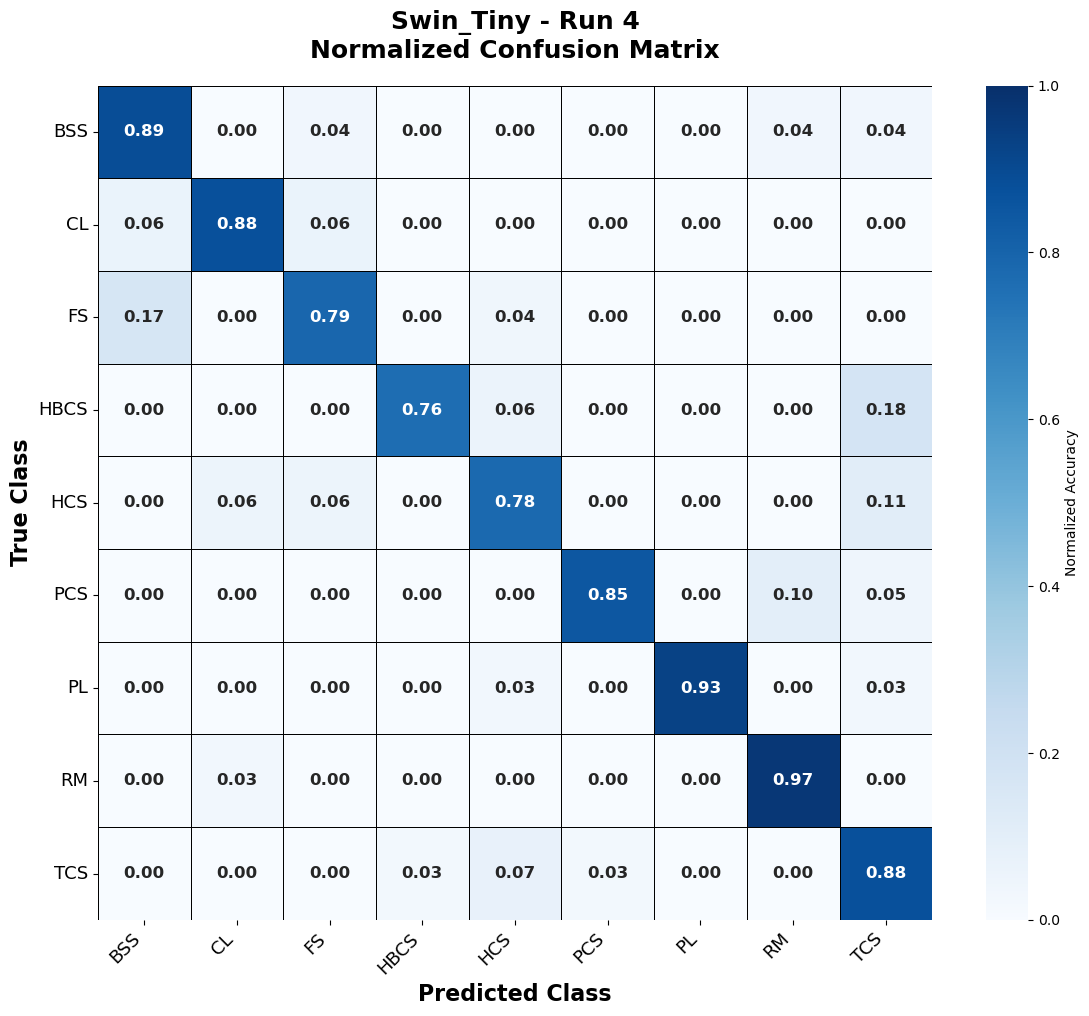


✓ Confusion matrices saved successfully

Files Saved Successfully
------------------------------------------------------------
Raw Confusion CSV          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\Swin_Tiny_Run4_Raw.csv
Normalized Confusion CSV   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\Swin_Tiny_Run4_Normalized.csv
Raw Confusion PNG          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\Swin_Tiny_Run4_Raw.png
Normalized Confusion PNG   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\Swin_Tiny_Run4_Normalized.png
Most Confused Classes CSV  : C:\Users\Frontech\Desktop\Codes\Combined Data

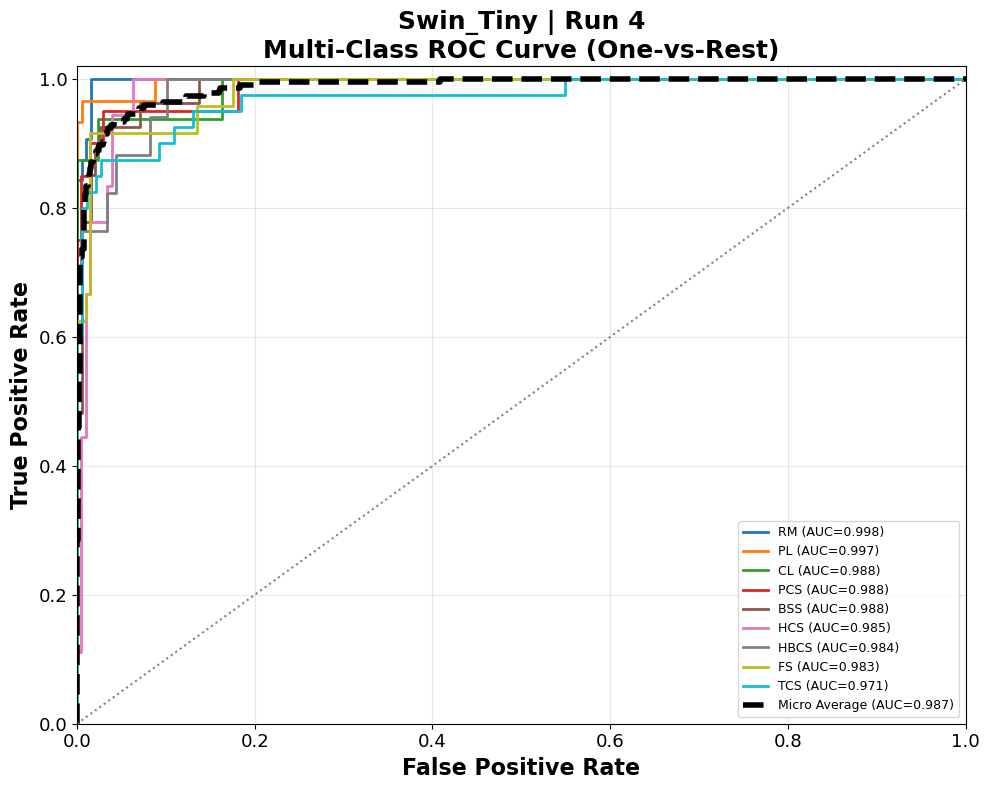


AUC Values
--------------------------------------------------------------------------------
               Class       AUC  Performance
0                 RM  0.998047  Outstanding
1                 PL  0.996907  Outstanding
2                 CL  0.988281    Excellent
3                PCS  0.988235    Excellent
4                BSS  0.987968    Excellent
5                HCS  0.984898    Excellent
6               HBCS  0.984371    Excellent
7                 FS  0.982917    Excellent
8                TCS  0.970788    Excellent
9      Micro Average  0.987098      Summary
10     Macro Average  0.986935      Summary
11  Weighted Average  0.986522      Summary

ROC Summary
--------------------------------------------------------------------------------
Number of Classes           : 9
Excellent ROC (AUC ≥ 0.90)  : 9/9

Best Class                  : RM (Outstanding)
Best AUC                    : 0.9980

Worst Class                 : TCS (Excellent)
Worst AUC                   : 0.9708

Micro

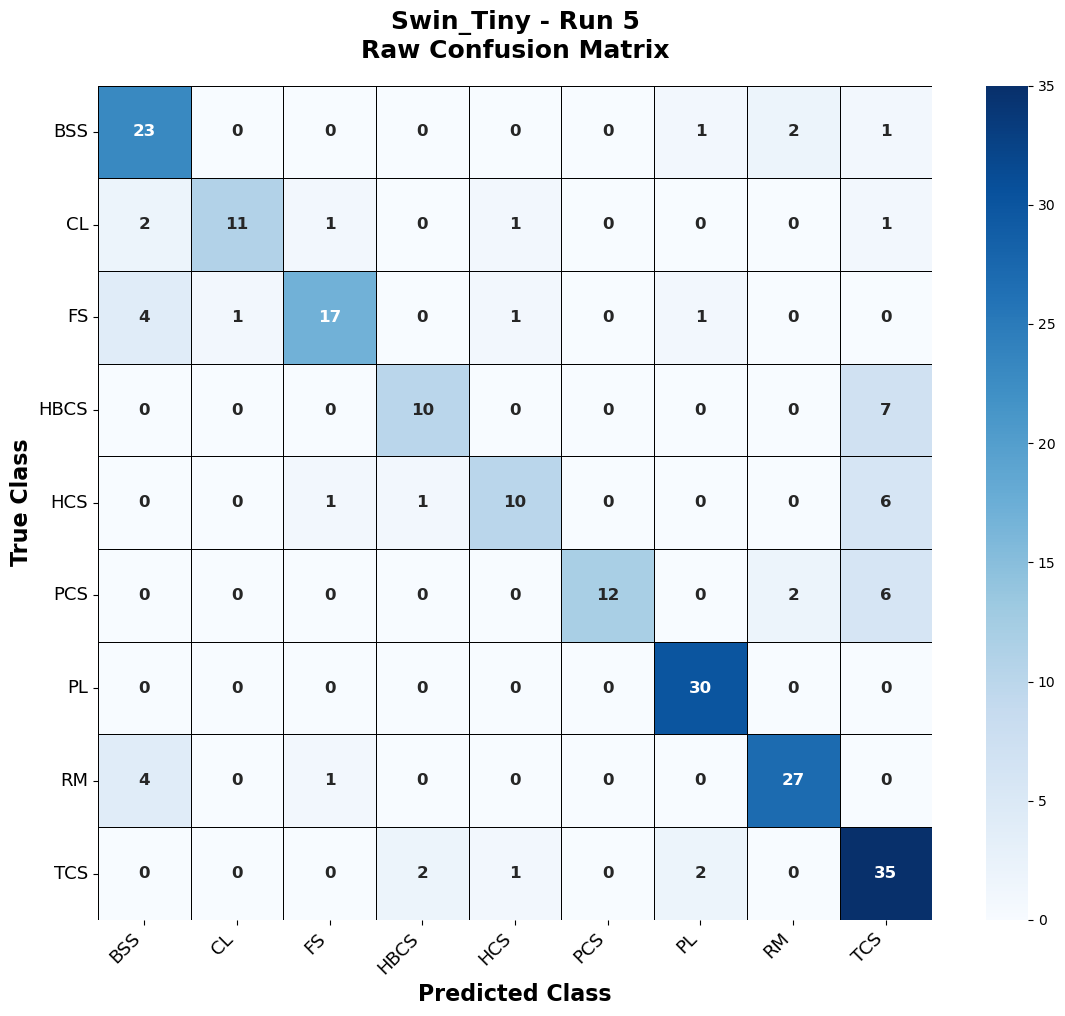

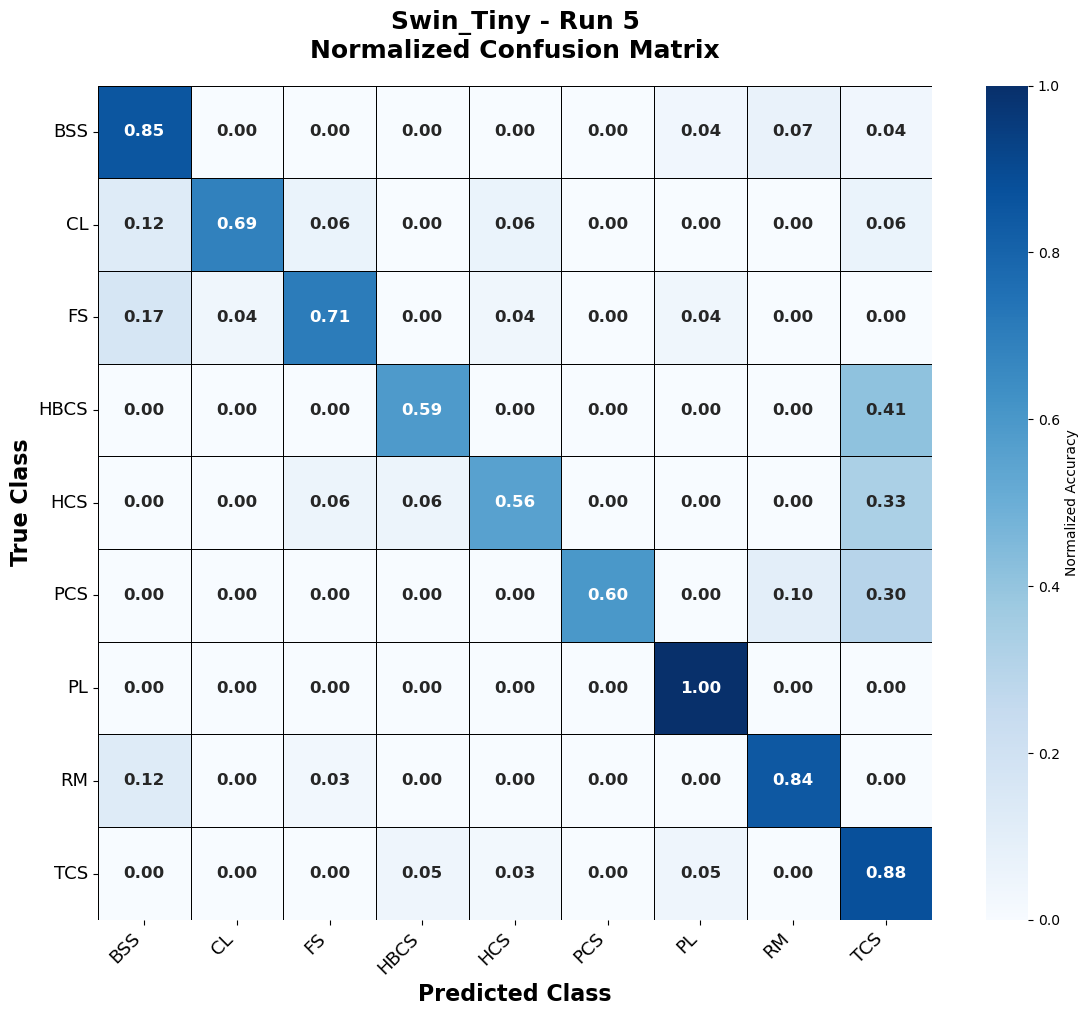


✓ Confusion matrices saved successfully

Files Saved Successfully
------------------------------------------------------------
Raw Confusion CSV          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\Swin_Tiny_Run5_Raw.csv
Normalized Confusion CSV   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\Swin_Tiny_Run5_Normalized.csv
Raw Confusion PNG          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\Swin_Tiny_Run5_Raw.png
Normalized Confusion PNG   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\Swin_Tiny_Run5_Normalized.png
Most Confused Classes CSV  : C:\Users\Frontech\Desktop\Codes\Combined Data

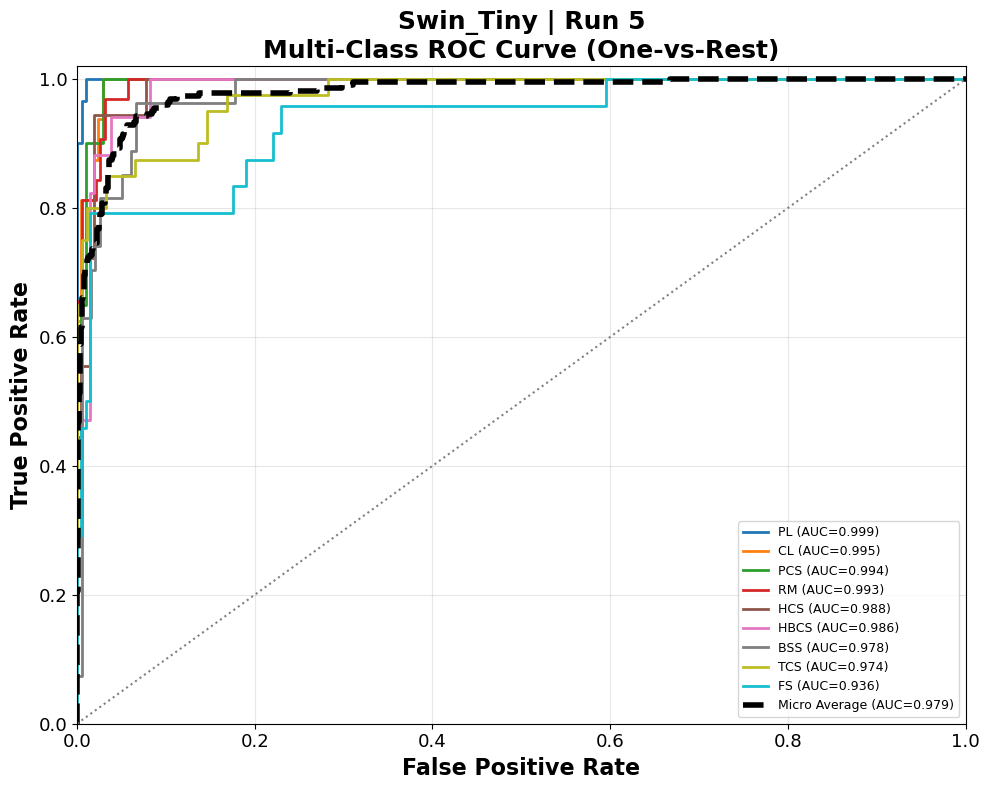


AUC Values
--------------------------------------------------------------------------------
               Class       AUC  Performance
0                 PL  0.999313  Outstanding
1                 CL  0.994591  Outstanding
2                PCS  0.994363  Outstanding
3                 RM  0.993164  Outstanding
4                HCS  0.988403    Excellent
5               HBCS  0.986360    Excellent
6                BSS  0.977815    Excellent
7                TCS  0.973641    Excellent
8                 FS  0.935625    Excellent
9      Micro Average  0.979318      Summary
10     Macro Average  0.982586      Summary
11  Weighted Average  0.981796      Summary

ROC Summary
--------------------------------------------------------------------------------
Number of Classes           : 9
Excellent ROC (AUC ≥ 0.90)  : 9/9

Best Class                  : PL (Outstanding)
Best AUC                    : 0.9993

Worst Class                 : FS (Excellent)
Worst AUC                   : 0.9356

Micro 

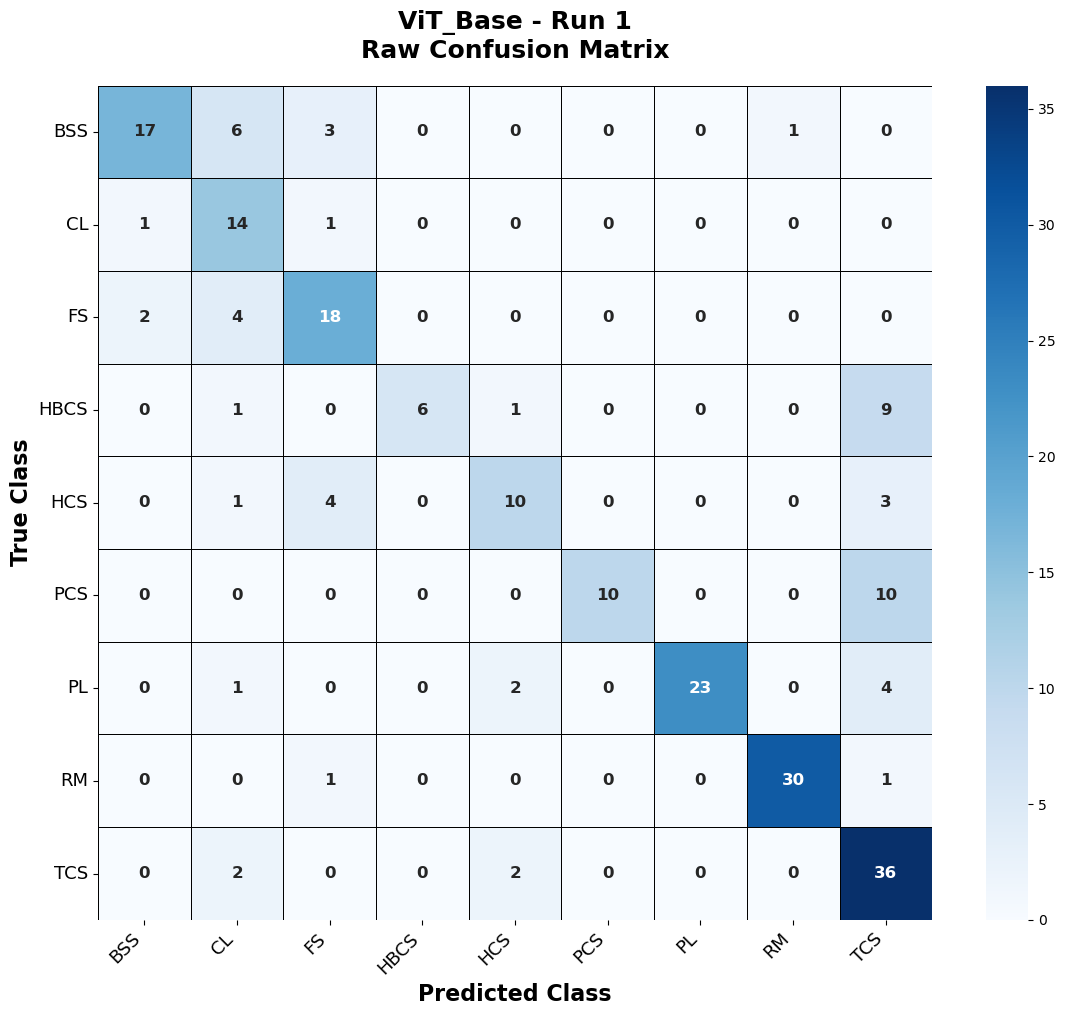

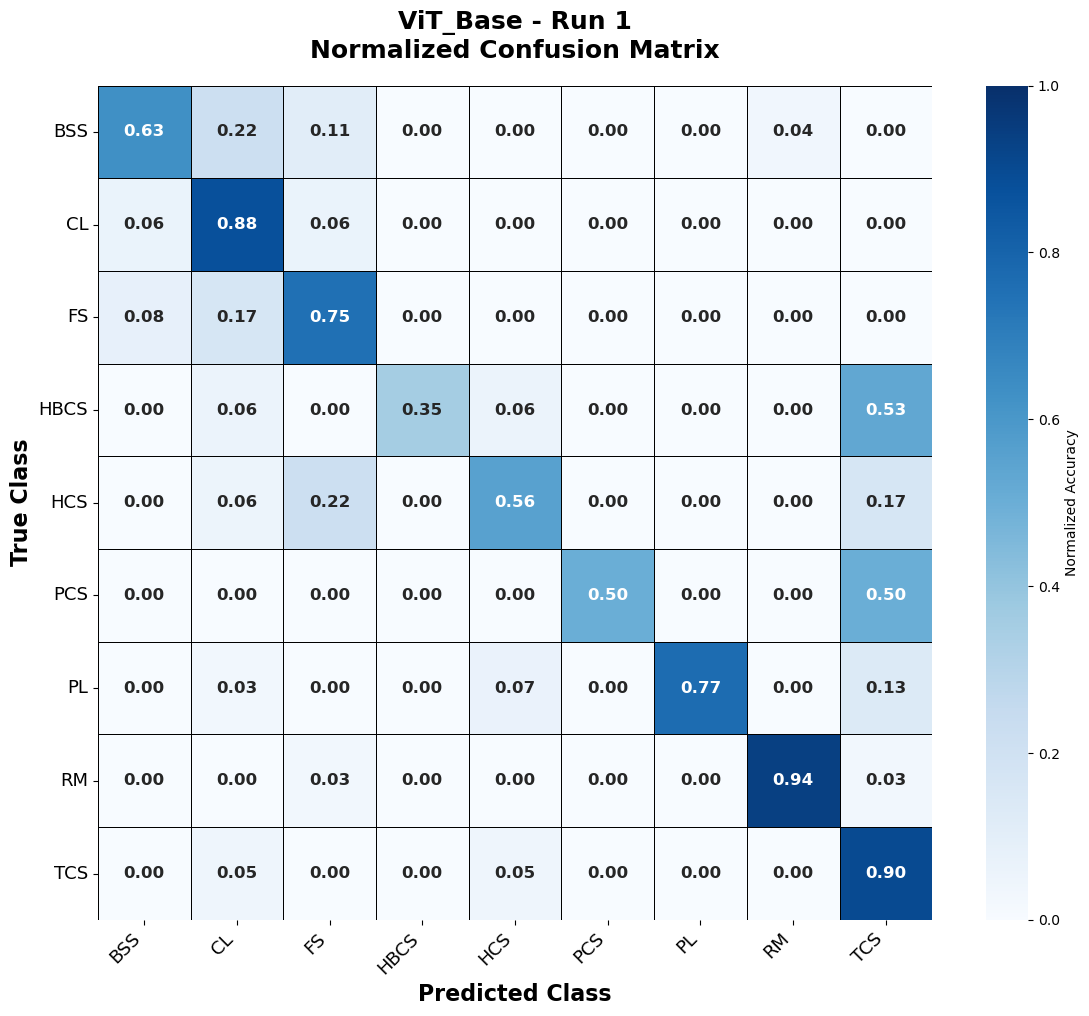


✓ Confusion matrices saved successfully

Files Saved Successfully
------------------------------------------------------------
Raw Confusion CSV          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\ViT_Base_Run1_Raw.csv
Normalized Confusion CSV   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\ViT_Base_Run1_Normalized.csv
Raw Confusion PNG          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\ViT_Base_Run1_Raw.png
Normalized Confusion PNG   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\ViT_Base_Run1_Normalized.png
Most Confused Classes CSV  : C:\Users\Frontech\Desktop\Codes\Combined Data set

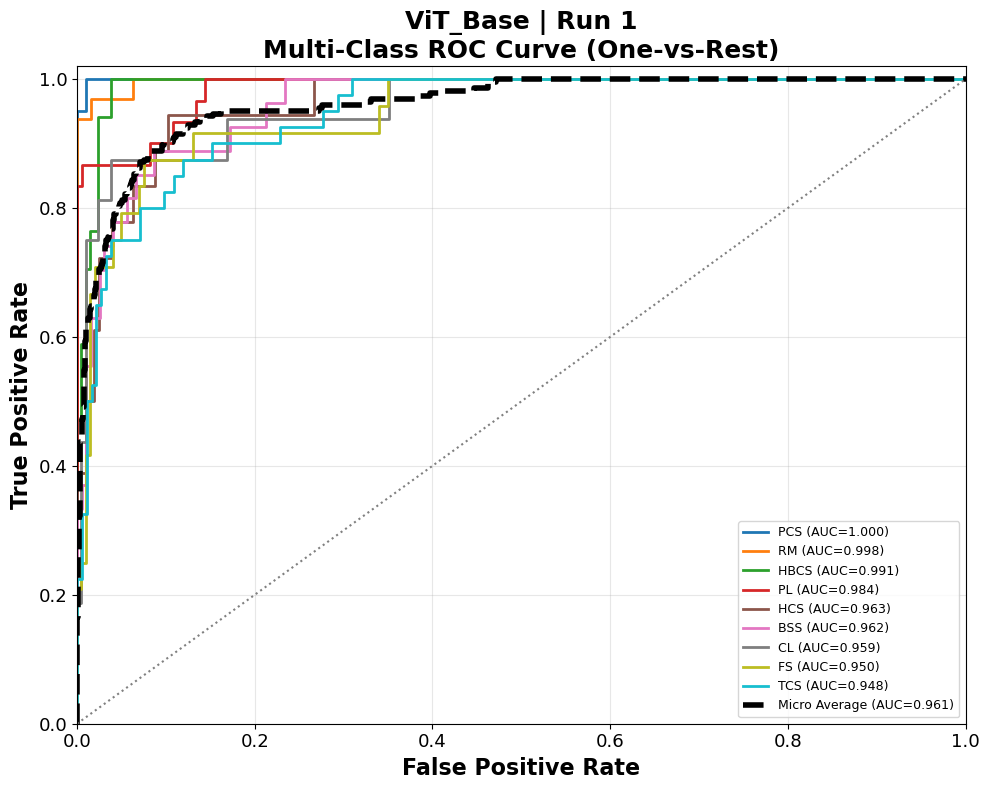


AUC Values
--------------------------------------------------------------------------------
               Class       AUC  Performance
0                PCS  0.999510  Outstanding
1                 RM  0.997559  Outstanding
2               HBCS  0.990907  Outstanding
3                 PL  0.984192    Excellent
4                HCS  0.963053    Excellent
5                BSS  0.961647    Excellent
6                 CL  0.959435    Excellent
7                 FS  0.949583    Excellent
8                TCS  0.947962    Excellent
9      Micro Average  0.960855      Summary
10     Macro Average  0.972650      Summary
11  Weighted Average  0.971617      Summary

ROC Summary
--------------------------------------------------------------------------------
Number of Classes           : 9
Excellent ROC (AUC ≥ 0.90)  : 9/9

Best Class                  : PCS (Outstanding)
Best AUC                    : 0.9995

Worst Class                 : TCS (Excellent)
Worst AUC                   : 0.9480

Micr

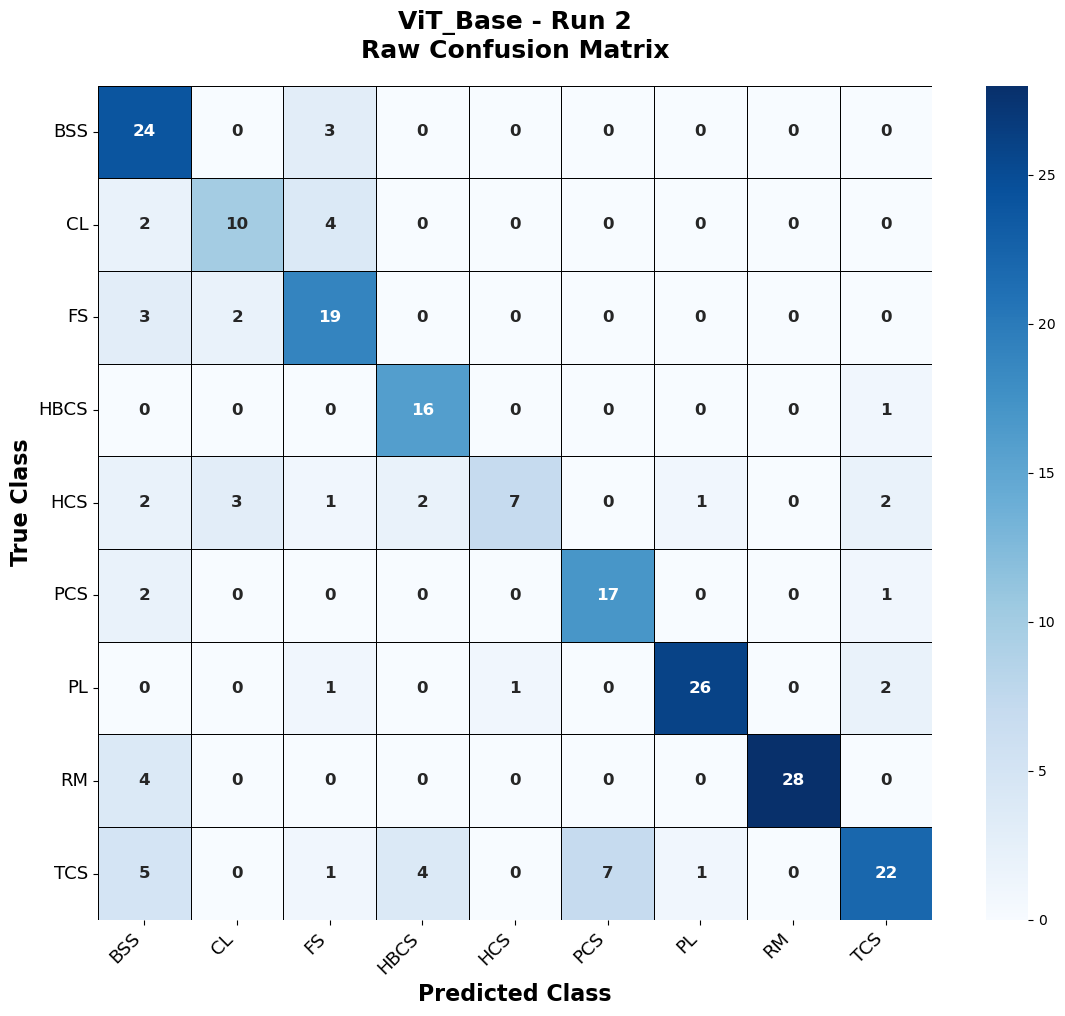

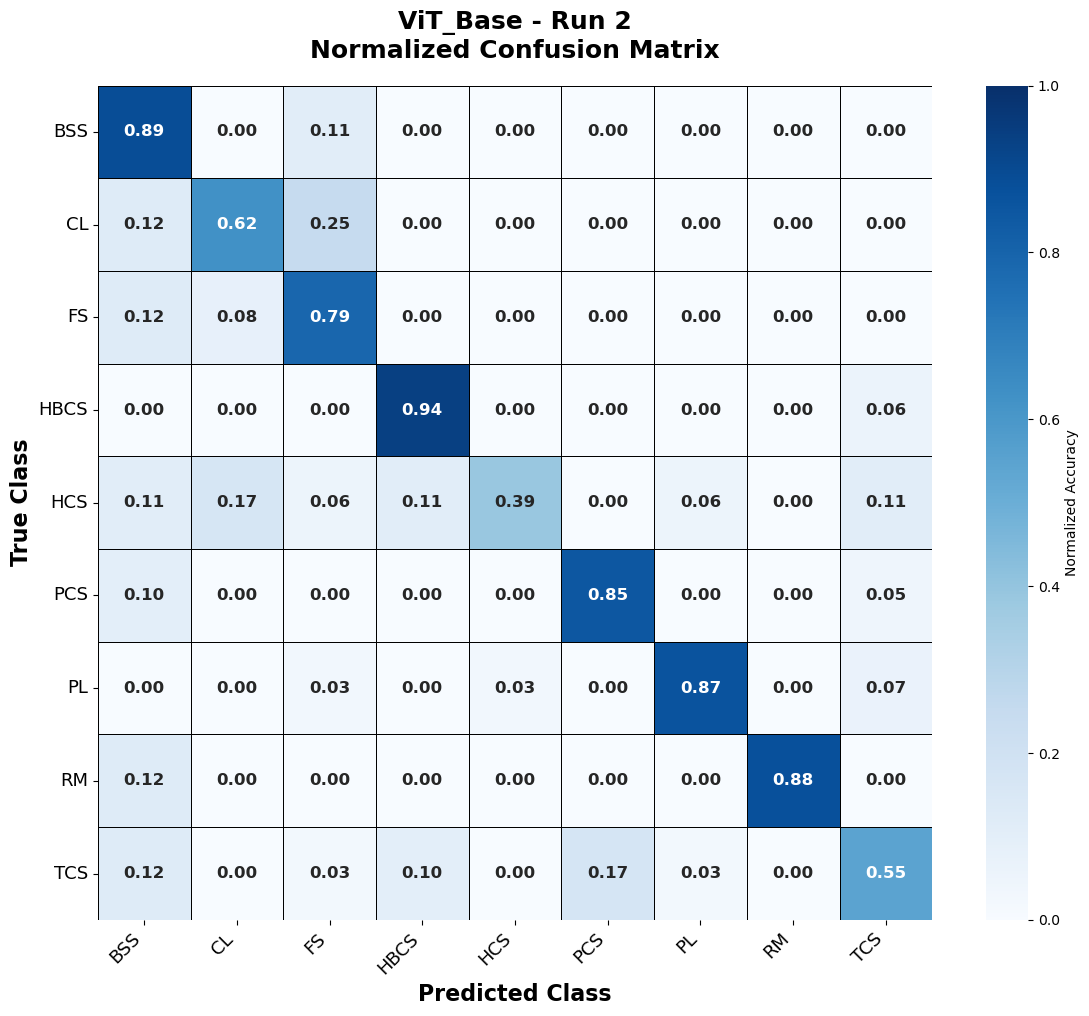


✓ Confusion matrices saved successfully

Files Saved Successfully
------------------------------------------------------------
Raw Confusion CSV          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\ViT_Base_Run2_Raw.csv
Normalized Confusion CSV   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\ViT_Base_Run2_Normalized.csv
Raw Confusion PNG          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\ViT_Base_Run2_Raw.png
Normalized Confusion PNG   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\ViT_Base_Run2_Normalized.png
Most Confused Classes CSV  : C:\Users\Frontech\Desktop\Codes\Combined Data set

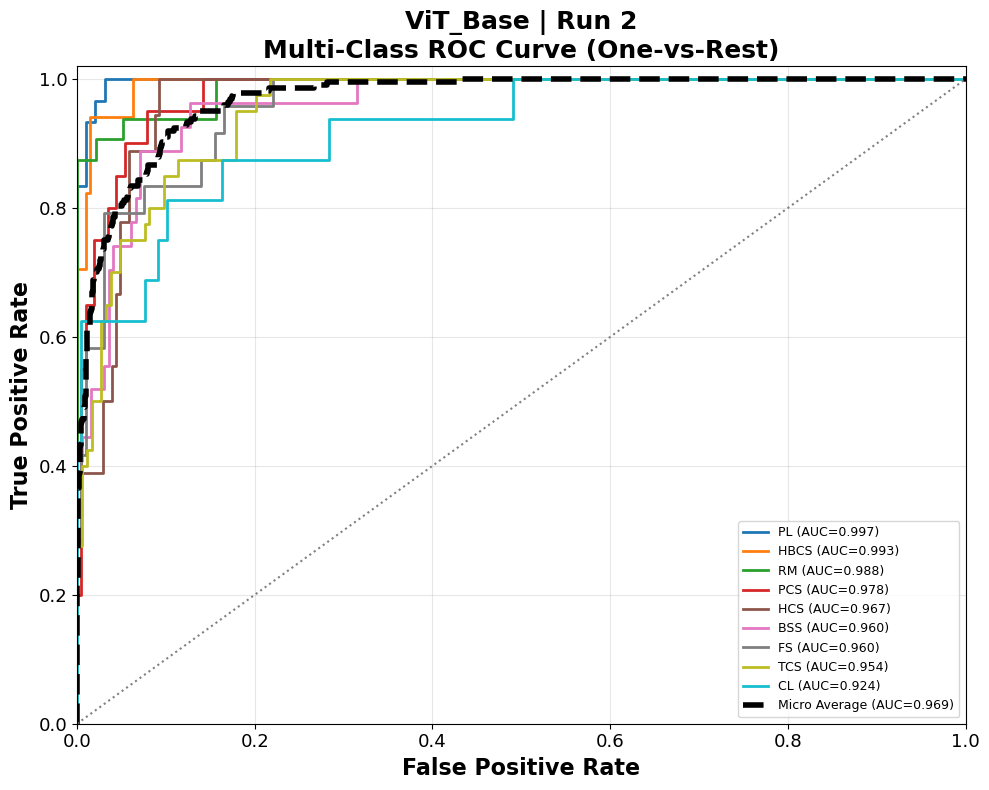


AUC Values
--------------------------------------------------------------------------------
               Class       AUC  Performance
0                 PL  0.997251  Outstanding
1               HBCS  0.993464  Outstanding
2                 RM  0.987956    Excellent
3                PCS  0.977696    Excellent
4                HCS  0.967368    Excellent
5                BSS  0.960143    Excellent
6                 FS  0.960000    Excellent
7                TCS  0.953668    Excellent
8                 CL  0.923678    Excellent
9      Micro Average  0.969029      Summary
10     Macro Average  0.969025      Summary
11  Weighted Average  0.969987      Summary

ROC Summary
--------------------------------------------------------------------------------
Number of Classes           : 9
Excellent ROC (AUC ≥ 0.90)  : 9/9

Best Class                  : PL (Outstanding)
Best AUC                    : 0.9973

Worst Class                 : CL (Excellent)
Worst AUC                   : 0.9237

Micro 

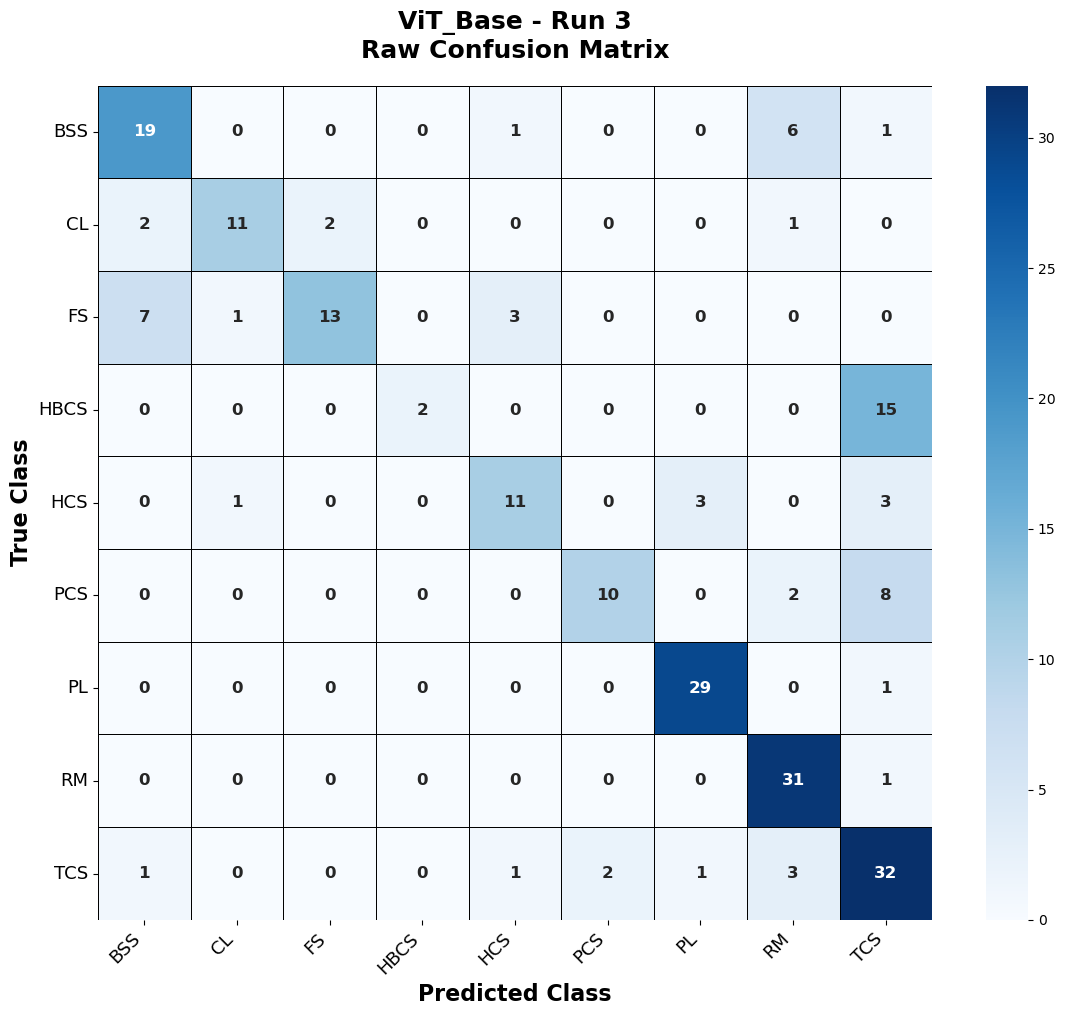

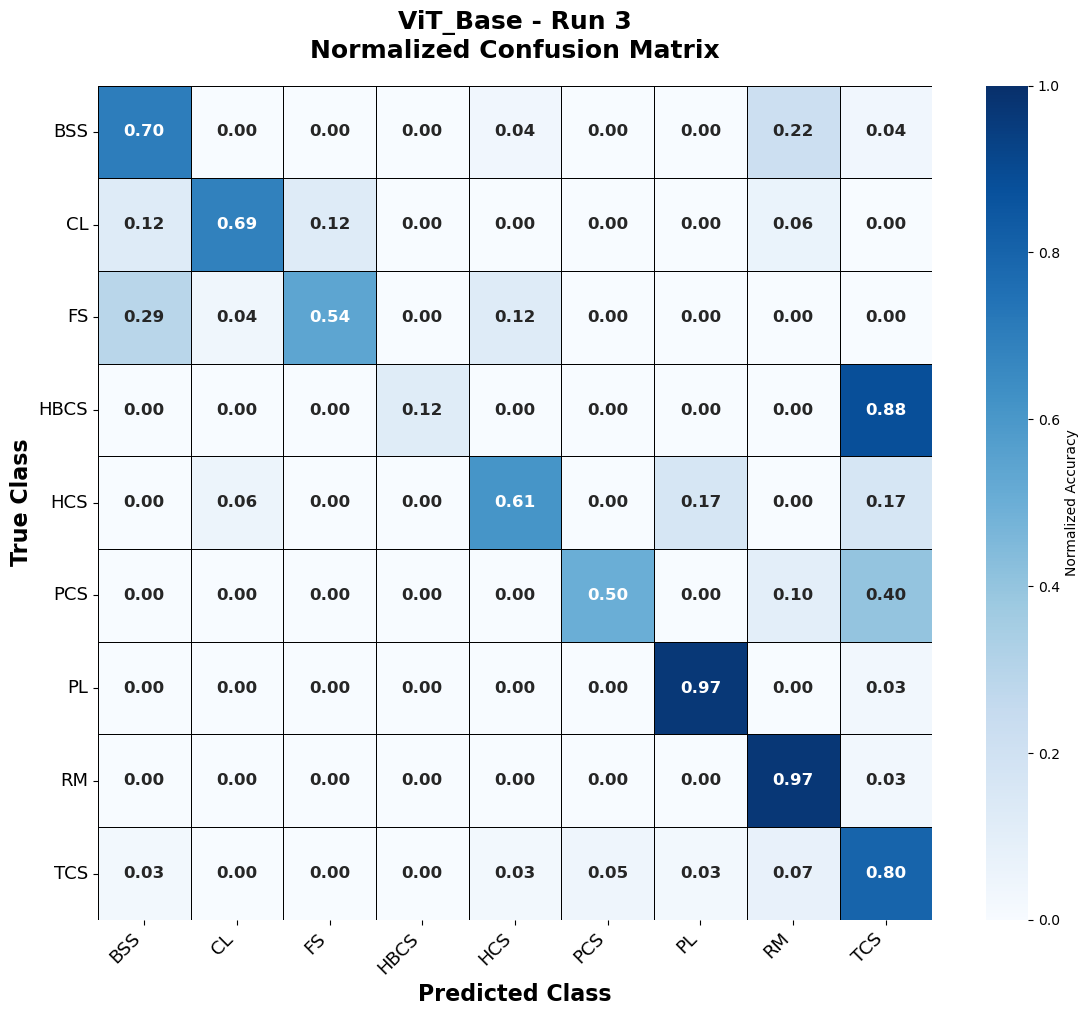


✓ Confusion matrices saved successfully

Files Saved Successfully
------------------------------------------------------------
Raw Confusion CSV          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\ViT_Base_Run3_Raw.csv
Normalized Confusion CSV   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\ViT_Base_Run3_Normalized.csv
Raw Confusion PNG          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\ViT_Base_Run3_Raw.png
Normalized Confusion PNG   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\ViT_Base_Run3_Normalized.png
Most Confused Classes CSV  : C:\Users\Frontech\Desktop\Codes\Combined Data set

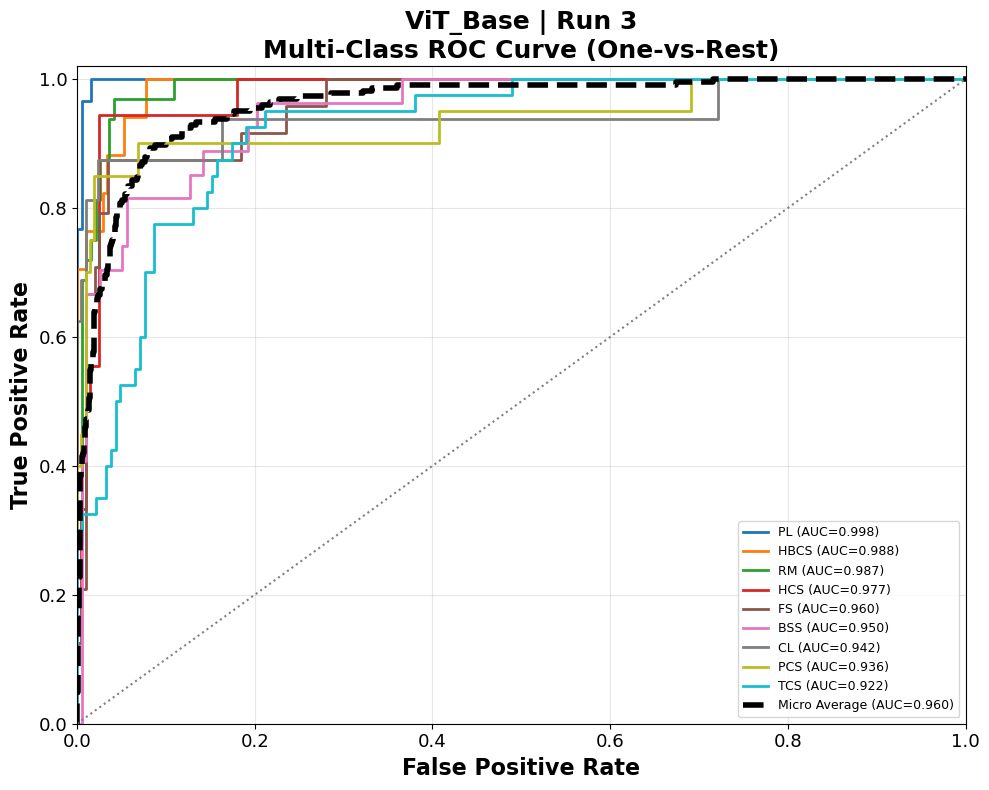


AUC Values
--------------------------------------------------------------------------------
               Class       AUC  Performance
0                 PL  0.998454  Outstanding
1               HBCS  0.988065    Excellent
2                 RM  0.987142    Excellent
3                HCS  0.977346    Excellent
4                 FS  0.960000    Excellent
5                BSS  0.950179    Excellent
6                 CL  0.941707    Excellent
7                PCS  0.936275    Excellent
8                TCS  0.922147    Excellent
9      Micro Average  0.959797      Summary
10     Macro Average  0.962368      Summary
11  Weighted Average  0.961183      Summary

ROC Summary
--------------------------------------------------------------------------------
Number of Classes           : 9
Excellent ROC (AUC ≥ 0.90)  : 9/9

Best Class                  : PL (Outstanding)
Best AUC                    : 0.9985

Worst Class                 : TCS (Excellent)
Worst AUC                   : 0.9221

Micro

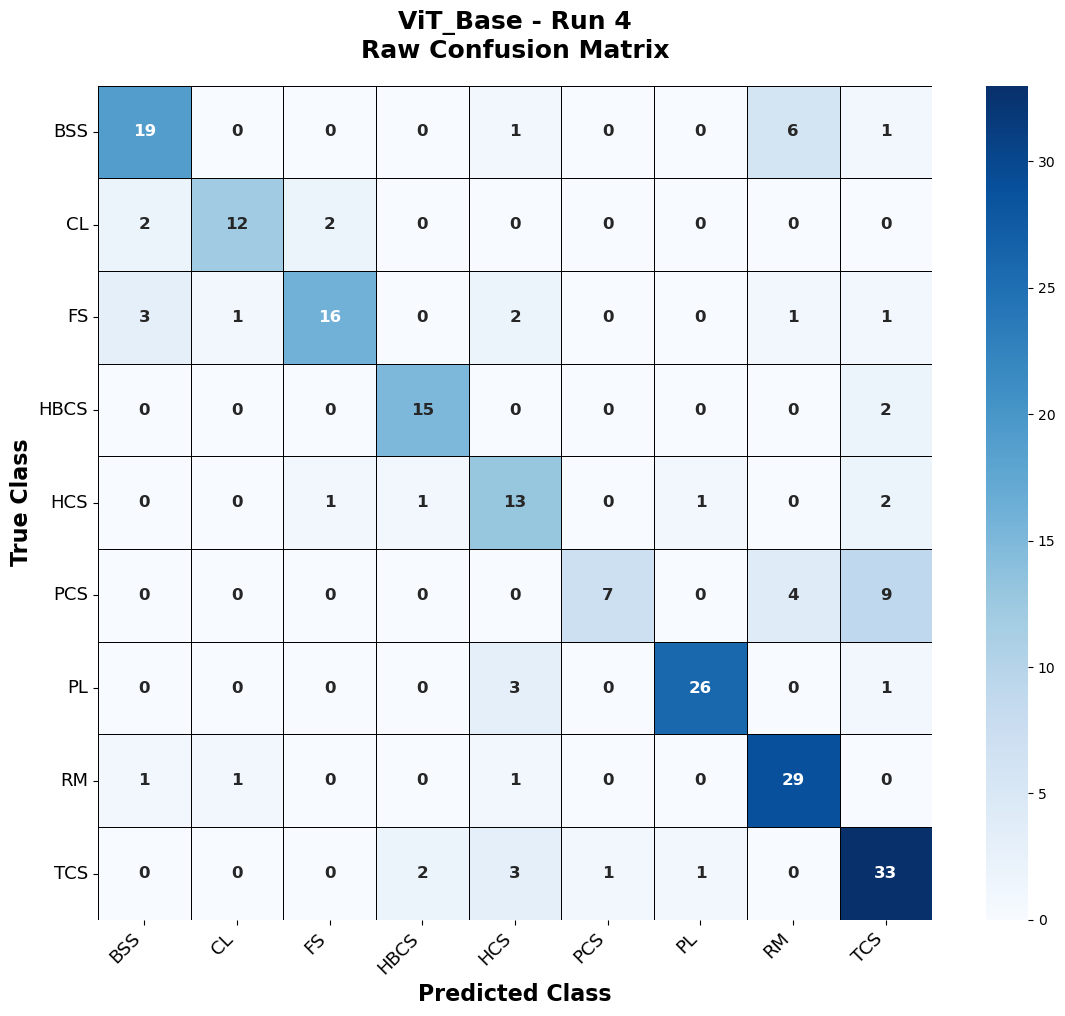

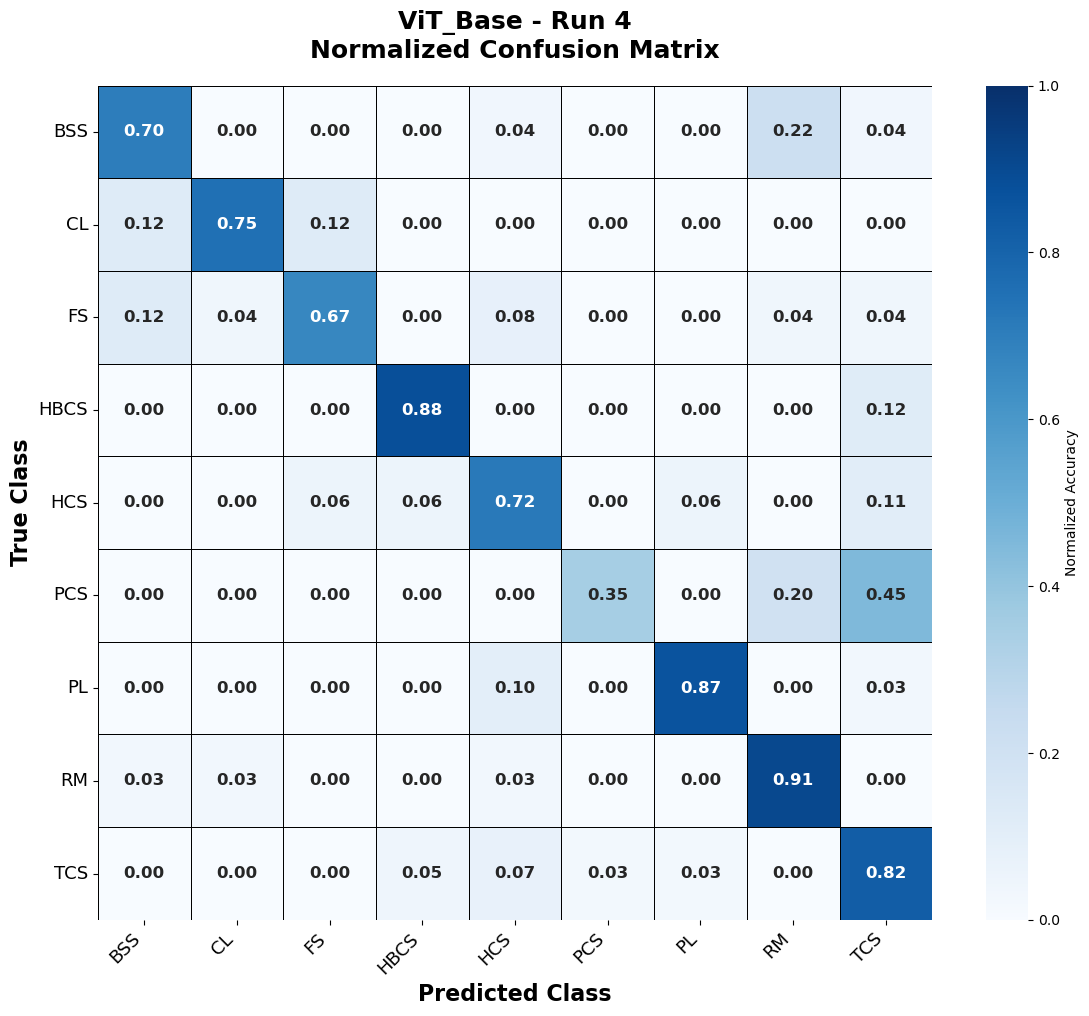


✓ Confusion matrices saved successfully

Files Saved Successfully
------------------------------------------------------------
Raw Confusion CSV          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\ViT_Base_Run4_Raw.csv
Normalized Confusion CSV   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\ViT_Base_Run4_Normalized.csv
Raw Confusion PNG          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\ViT_Base_Run4_Raw.png
Normalized Confusion PNG   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\ViT_Base_Run4_Normalized.png
Most Confused Classes CSV  : C:\Users\Frontech\Desktop\Codes\Combined Data set

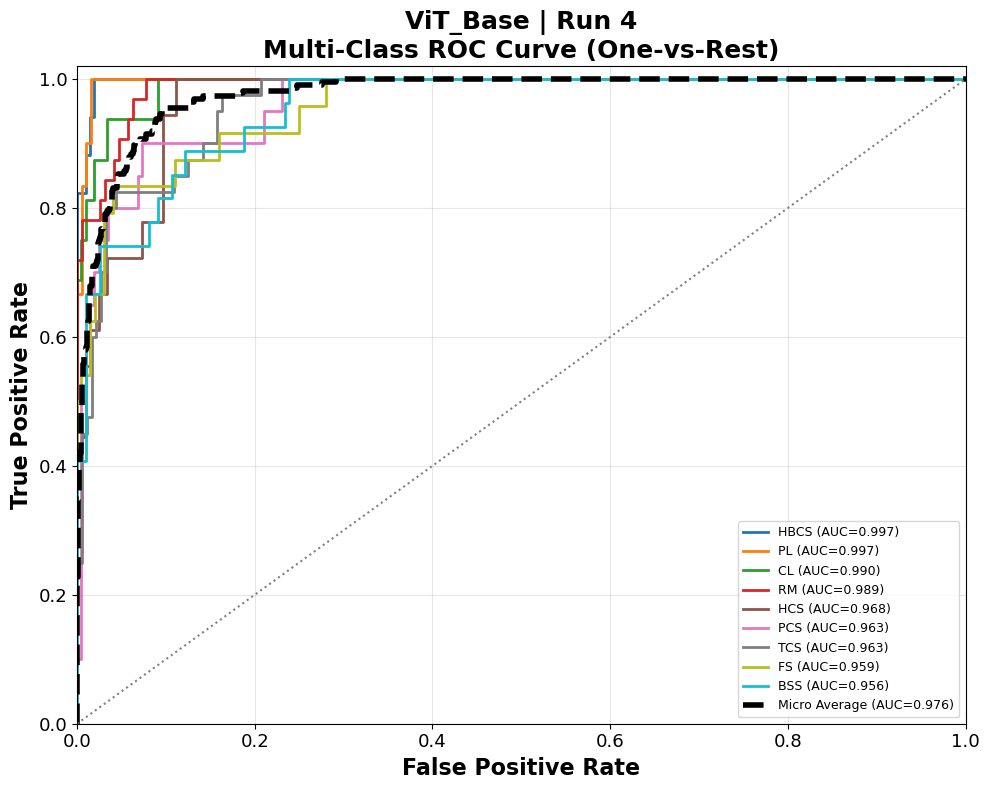


AUC Values
--------------------------------------------------------------------------------
               Class       AUC  Performance
0               HBCS  0.997442  Outstanding
1                 PL  0.996907  Outstanding
2                 CL  0.990084  Outstanding
3                 RM  0.988932    Excellent
4                HCS  0.968177    Excellent
5                PCS  0.963235    Excellent
6                TCS  0.963179    Excellent
7                 FS  0.958958    Excellent
8                BSS  0.956195    Excellent
9      Micro Average  0.975994      Summary
10     Macro Average  0.975901      Summary
11  Weighted Average  0.975010      Summary

ROC Summary
--------------------------------------------------------------------------------
Number of Classes           : 9
Excellent ROC (AUC ≥ 0.90)  : 9/9

Best Class                  : HBCS (Outstanding)
Best AUC                    : 0.9974

Worst Class                 : BSS (Excellent)
Worst AUC                   : 0.9562

Mic

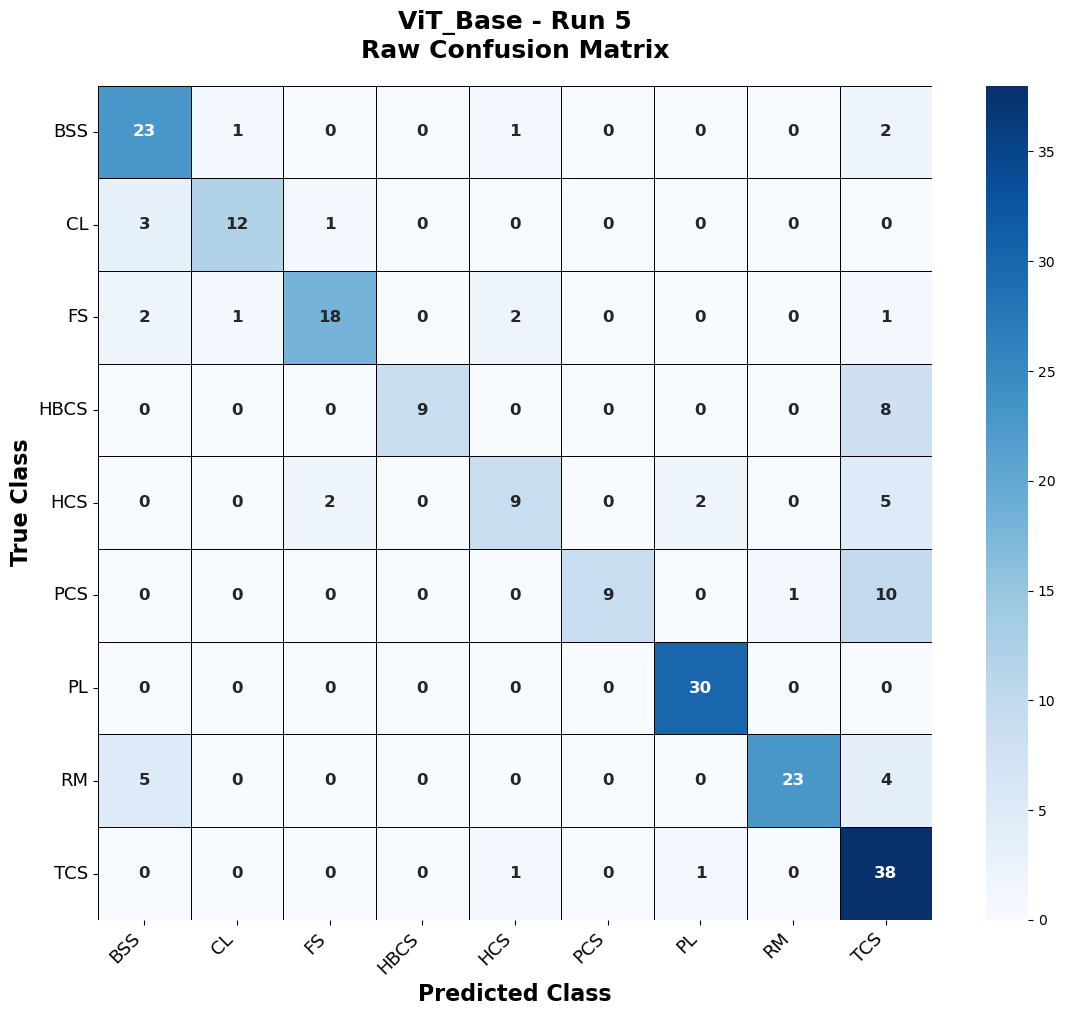

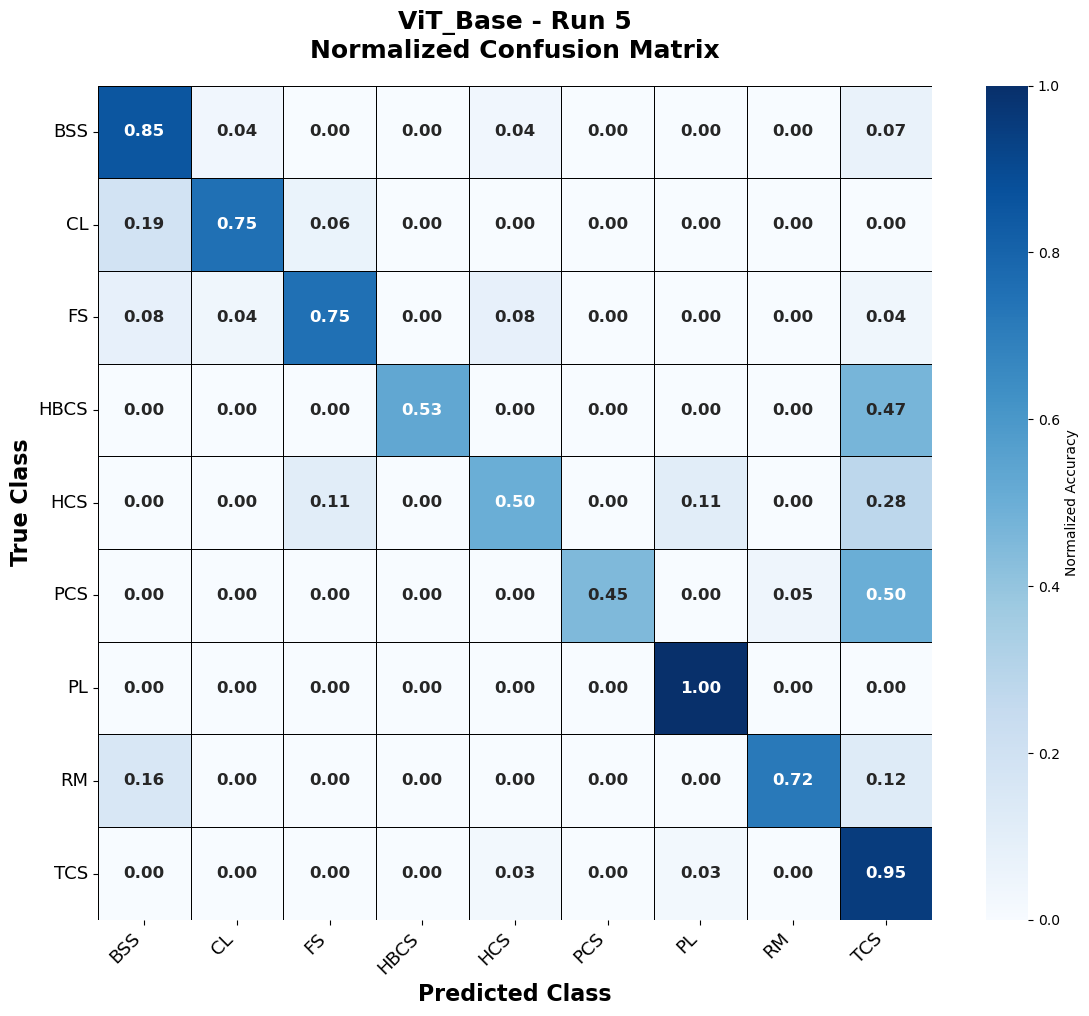


✓ Confusion matrices saved successfully

Files Saved Successfully
------------------------------------------------------------
Raw Confusion CSV          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\ViT_Base_Run5_Raw.csv
Normalized Confusion CSV   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\ViT_Base_Run5_Normalized.csv
Raw Confusion PNG          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\ViT_Base_Run5_Raw.png
Normalized Confusion PNG   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Confusion_Matrix\ViT_Base_Run5_Normalized.png
Most Confused Classes CSV  : C:\Users\Frontech\Desktop\Codes\Combined Data set

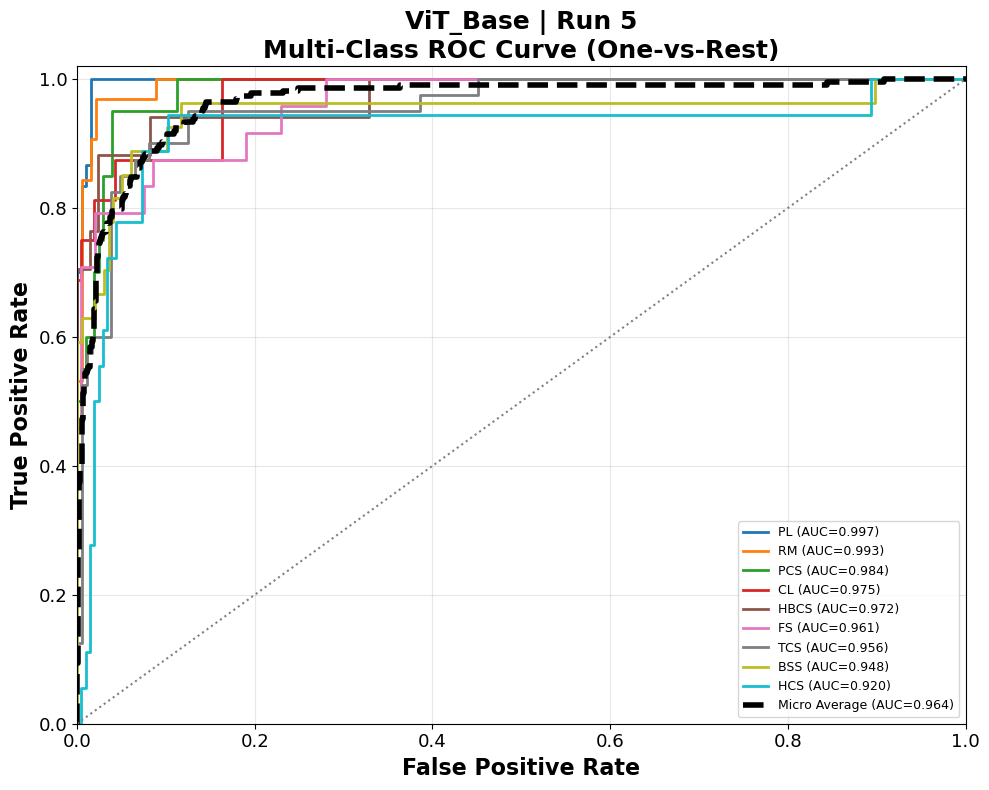


AUC Values
--------------------------------------------------------------------------------
               Class       AUC  Performance
0                 PL  0.996907  Outstanding
1                 RM  0.993327  Outstanding
2                PCS  0.983578    Excellent
3                 CL  0.975361    Excellent
4               HBCS  0.972151    Excellent
5                 FS  0.961250    Excellent
6                TCS  0.956250    Excellent
7                BSS  0.948299    Excellent
8                HCS  0.919903    Excellent
9      Micro Average  0.964278      Summary
10     Macro Average  0.967447      Summary
11  Weighted Average  0.968660      Summary

ROC Summary
--------------------------------------------------------------------------------
Number of Classes           : 9
Excellent ROC (AUC ≥ 0.90)  : 9/9

Best Class                  : PL (Outstanding)
Best AUC                    : 0.9969

Worst Class                 : HCS (Excellent)
Worst AUC                   : 0.9199

Micro

In [36]:
# ============================================================
# SECTION 13 : BATCH EVALUATION OF ALL ViT MODELS
# ============================================================

import traceback

print("=" * 80)
print("SECTION 13 : BATCH EVALUATION OF ALL ViT MODELS")
print("=" * 80)

master_benchmark = []

failed_runs = []

total_jobs = TOTAL_EVALUATIONS

job = 1

for model_name in MODEL_LIST:

    print("\n" + "=" * 80)
    print(f"MODEL : {model_name}")
    print("=" * 80)

    for run, seed in enumerate(RUN_SEEDS, start=1):

        print("\n" + "-" * 80)
        print(f"[{job}/{total_jobs}] Evaluating {model_name} | Run {run}")
        print("-" * 80)

        current_step = "Initialization"

        try:

            # --------------------------------------------------------
            # Evaluate Model
            # --------------------------------------------------------

            current_step = "Evaluate Model"
            result = evaluate_model(model_name, run)

            # --------------------------------------------------------
            # Compute Metrics
            # --------------------------------------------------------

            current_step = "Compute Metrics"
            result = compute_metrics(result)

            # --------------------------------------------------------
            # Confusion Matrix
            # --------------------------------------------------------

            current_step = "Confusion Matrix"
            result = plot_confusion_matrix(result)

            # --------------------------------------------------------
            # Prediction Table
            # --------------------------------------------------------

            current_step = "Build Prediction Table"
            result = build_prediction_table(result)

            # --------------------------------------------------------
            # Prediction Summary
            # --------------------------------------------------------

            current_step = "Prediction Summary"
            result = prediction_summary(result)

            # --------------------------------------------------------
            # Prediction Analysis
            # --------------------------------------------------------

            current_step = "Prediction Analysis"
            result = analyze_predictions(result)

            # --------------------------------------------------------
            # Confidence Analysis
            # --------------------------------------------------------

            current_step = "Class-wise Confidence Analysis"
            result = classwise_confidence_analysis(result)

            # --------------------------------------------------------
            # ROC & AUC
            # --------------------------------------------------------

            current_step = "ROC Analysis"
            result = plot_multiclass_roc(result)

            # --------------------------------------------------------
            # Misclassification Analysis
            # --------------------------------------------------------

            current_step = "Misclassification Analysis"
            result = misclassification_analysis(result)

            # --------------------------------------------------------
            # Benchmark Summary
            # --------------------------------------------------------

            current_step = "Benchmark Summary"
            result = benchmark_summary(result)

            # --------------------------------------------------------
            # Evaluation Summary
            # --------------------------------------------------------

            current_step = "Evaluation Summary"
            result = evaluation_summary(result)

            # --------------------------------------------------------
            # Store Benchmark
            # --------------------------------------------------------

            current_step = "Store Benchmark"

            master_benchmark.append(result["benchmark_summary"])

            print("\n✓ Evaluation Completed Successfully")

        except Exception as e:

            print(f"\n✗ Evaluation Failed")
            print(f"Model : {model_name}")
            print(f"Run   : {run}")
            print(f"Step  : {current_step}")
            print(f"Error : {e}")

            traceback.print_exc()

            failed_runs.append({

                "Model": model_name,
                "Run": run,
                "Step": current_step,
                "Error": str(e)

            })

        job += 1

In [37]:
# Check for fail test
print(len(master_benchmark))
print(len(failed_runs))

15
0


In [38]:
# ============================================================
# CREATE MASTER BENCHMARK
# ============================================================

print("\n" + "=" * 80)
print("CREATING MASTER BENCHMARK")
print("=" * 80)

if len(master_benchmark) > 0:

    master_benchmark_df = pd.concat(
        master_benchmark,
        ignore_index=True
    )

    master_benchmark_file = (
        BENCHMARK_DIR /
        "ViT_Master_Benchmark.csv"
    )

    master_benchmark_df.to_csv(
        master_benchmark_file,
        index=False
    )

    print("\n✓ Master Benchmark Saved")

    print(master_benchmark_file.resolve())

    display(master_benchmark_df)

else:

    master_benchmark_df = pd.DataFrame()

    print("No benchmark data generated.")


CREATING MASTER BENCHMARK

✓ Master Benchmark Saved
C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Benchmark\ViT_Master_Benchmark.csv


,Model,Run,Total Images,Accuracy,Precision Macro,Recall Macro,F1 Macro,Precision Weighted,Recall Weighted,F1 Weighted,...,Cohen Kappa,MCC,Log Loss,Parameters,Trainable Parameters,"Inference Time (Total, s)",Inference Time/Image (ms),Micro AUC,Macro AUC,Weighted AUC
0,DeiT_Small,1,224,0.8750,0.8814,0.8698,0.8728,0.8792,0.8750,0.8747,...,0.8574,0.8580,0.4321,21669129,21669129,6.0112,26.8357,0.9900,0.9906,0.9894
1,DeiT_Small,2,224,0.8214,0.8385,0.7993,0.8120,0.8295,0.8214,0.8198,...,0.7959,0.7971,0.5043,21669129,21669129,6.0243,26.8944,0.9821,0.9820,0.9809
2,DeiT_Small,3,224,0.8482,0.8599,0.8494,0.8532,0.8511,0.8482,0.8485,...,0.8271,0.8273,0.5251,21669129,21669129,6.5512,29.2463,0.9866,0.9856,0.9849
3,DeiT_Small,4,224,0.8036,0.7973,0.7983,0.7922,0.8121,0.8036,0.8016,...,0.7769,0.7788,0.5742,21669129,21669129,6.5786,29.3690,0.9809,0.9785,0.9786
4,DeiT_Small,5,224,0.8259,0.8429,0.8200,0.8217,0.8373,0.8259,0.8234,...,0.8018,0.8035,0.5820,21669129,21669129,6.4868,28.9587,0.9804,0.9809,0.9799
5,Swin_Tiny,1,224,0.7946,0.8142,0.7909,0.7875,0.8207,0.7946,0.7934,...,0.7670,0.7704,0.6560,27526275,27526275,11.9882,53.5189,0.9764,0.9758,0.9752
6,Swin_Tiny,2,224,0.8304,0.8261,0.8222,0.8211,0.8347,0.8304,0.8300,...,0.8068,0.8074,0.4356,27526275,27526275,11.5735,51.6675,0.9882,0.9867,0.9856
7,Swin_Tiny,3,224,0.8661,0.8878,0.8554,0.8673,0.8783,0.8661,0.8674,...,0.8468,0.8485,0.6174,27526275,27526275,11.1787,49.9048,0.9845,0.9846,0.9844
8,Swin_Tiny,4,224,0.8705,0.8739,0.8583,0.8641,0.8754,0.8705,0.8712,...,0.8524,0.8528,0.5366,27526275,27526275,11.1766,49.8955,0.9871,0.9869,0.9865
9,Swin_Tiny,5,224,0.7812,0.8200,0.7456,0.7679,0.8042,0.7812,0.7789,...,0.7486,0.7526,0.5941,27526275,27526275,11.1691,49.8622,0.9793,0.9826,0.9818


In [39]:
# ============================================================
# FAILED RUNS
# ============================================================

if len(failed_runs) > 0:

    failed_df = pd.DataFrame(failed_runs)

    failed_file = (
        BENCHMARK_DIR /
        "ViT_Failed_Runs.csv"
    )

    failed_df.to_csv(
        failed_file,
        index=False
    )

    print("\nSome evaluations failed.")

    print(failed_file.resolve())

    display(failed_df)

else:

    print("\n✓ All models evaluated successfully.")


✓ All models evaluated successfully.


In [40]:
# ============================================================
# FINAL SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("ViT BATCH EVALUATION COMPLETED")
print("=" * 80)

print(f"Total Jobs          : {total_jobs}")
print(f"Successful Jobs     : {len(master_benchmark)}")
print(f"Failed Jobs         : {len(failed_runs)}")

print("=" * 80)


ViT BATCH EVALUATION COMPLETED
Total Jobs          : 15
Successful Jobs     : 15
Failed Jobs         : 0


In [41]:
# ============================================================
# SECTION 14 : ViT BENCHMARK AGGREGATION
# ============================================================

print("=" * 80)
print("SECTION 14 : ViT BENCHMARK AGGREGATION")
print("=" * 80)

# ------------------------------------------------------------
# Create Master DataFrame
# ------------------------------------------------------------

master_df = pd.concat(master_benchmark, ignore_index=True)

print(f"\nTotal Evaluations : {len(master_df)}")
print(f"Models            : {master_df['Model'].nunique()}")

# ------------------------------------------------------------
# Metrics to Aggregate
# ------------------------------------------------------------

metric_columns = [

    "Accuracy",

    "Precision Macro",
    "Recall Macro",
    "F1 Macro",

    "Precision Weighted",
    "Recall Weighted",
    "F1 Weighted",

    "Balanced Accuracy",

    "Cohen Kappa",

    "MCC",

    "Log Loss",

    "Micro AUC",
    "Macro AUC",
    "Weighted AUC",

    "Inference Time (Total, s)",
    "Inference Time/Image (ms)"

]

# ------------------------------------------------------------
# Aggregate Statistics
# ------------------------------------------------------------

summary_rows = []

for model in MODEL_LIST:

    df_model = master_df[master_df["Model"] == model]

    row = {
        "Model": model,
        "Runs": len(df_model)
    }

    for metric in metric_columns:

        row[f"{metric} Mean"]  = df_model[metric].mean()
        row[f"{metric} Std"]   = df_model[metric].std()
        row[f"{metric} Best"]  = df_model[metric].max()
        row[f"{metric} Worst"] = df_model[metric].min()

    summary_rows.append(row)

ViT_summary = pd.DataFrame(summary_rows)

# ------------------------------------------------------------
# Round Numeric Columns
# ------------------------------------------------------------

numeric_cols = ViT_summary.select_dtypes(include="number").columns

ViT_summary[numeric_cols] = ViT_summary[numeric_cols].round(4)

# ------------------------------------------------------------
# Store Result
# ------------------------------------------------------------

ViT_BENCHMARK_SUMMARY = ViT_summary

# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print("\nViT Benchmark Summary")
display(ViT_BENCHMARK_SUMMARY)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

summary_file = BENCHMARK_DIR / "ViT_Benchmark_Summary.csv"

ViT_BENCHMARK_SUMMARY.to_csv(
    summary_file,
    index=False
)

print("\n✓ ViT Benchmark Summary Saved Successfully")
print(summary_file.resolve())

SECTION 14 : ViT BENCHMARK AGGREGATION

Total Evaluations : 15
Models            : 3

ViT Benchmark Summary


,Model,Runs,Accuracy Mean,Accuracy Std,Accuracy Best,Accuracy Worst,Precision Macro Mean,Precision Macro Std,Precision Macro Best,Precision Macro Worst,...,Weighted AUC Best,Weighted AUC Worst,"Inference Time (Total, s) Mean","Inference Time (Total, s) Std","Inference Time (Total, s) Best","Inference Time (Total, s) Worst",Inference Time/Image (ms) Mean,Inference Time/Image (ms) Std,Inference Time/Image (ms) Best,Inference Time/Image (ms) Worst
0,DeiT_Small,5,0.8348,0.0275,0.8750,0.8036,0.8440,0.0311,0.8814,0.7973,...,0.9894,0.9786,6.3304,0.2874,6.5786,6.0112,28.2608,1.2830,29.3690,26.8357
1,Swin_Tiny,5,0.8286,0.0405,0.8705,0.7812,0.8444,0.0339,0.8878,0.8142,...,0.9865,0.9752,11.4172,0.3629,11.9882,11.1691,50.9698,1.6202,53.5189,49.8622
2,ViT_Base,5,0.7429,0.0242,0.7634,0.7054,0.7939,0.0265,0.8366,0.7687,...,0.9750,0.9612,17.7526,0.0994,17.8397,17.5947,79.2525,0.4437,79.6413,78.5479



✓ ViT Benchmark Summary Saved Successfully
C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Benchmark\ViT_Benchmark_Summary.csv


In [42]:
# ============================================================
# SECTION 15 : ViT MEAN ± STD BENCHMARK TABLE
# ============================================================

print("=" * 80)
print("SECTION 15 : ViT MEAN ± STD BENCHMARK TABLE")
print("=" * 80)

# ------------------------------------------------------------
# Create Publication Table
# ------------------------------------------------------------

publication_rows = []

for _, row in ViT_BENCHMARK_SUMMARY.iterrows():

    publication_rows.append({

        "Model": row["Model"],

        "Runs": int(row["Runs"]),

        "Accuracy":
            f"{row['Accuracy Mean']:.4f} ± {row['Accuracy Std']:.4f}",

        "Precision (Macro)":
            f"{row['Precision Macro Mean']:.4f} ± {row['Precision Macro Std']:.4f}",

        "Recall (Macro)":
            f"{row['Recall Macro Mean']:.4f} ± {row['Recall Macro Std']:.4f}",

        "F1 Score (Macro)":
            f"{row['F1 Macro Mean']:.4f} ± {row['F1 Macro Std']:.4f}",

        "Precision (Weighted)":
            f"{row['Precision Weighted Mean']:.4f} ± {row['Precision Weighted Std']:.4f}",

        "Recall (Weighted)":
            f"{row['Recall Weighted Mean']:.4f} ± {row['Recall Weighted Std']:.4f}",

        "F1 Score (Weighted)":
            f"{row['F1 Weighted Mean']:.4f} ± {row['F1 Weighted Std']:.4f}",

        "Balanced Accuracy":
            f"{row['Balanced Accuracy Mean']:.4f} ± {row['Balanced Accuracy Std']:.4f}",

        "Cohen Kappa":
            f"{row['Cohen Kappa Mean']:.4f} ± {row['Cohen Kappa Std']:.4f}",

        "MCC":
            f"{row['MCC Mean']:.4f} ± {row['MCC Std']:.4f}",

        "Log Loss":
            f"{row['Log Loss Mean']:.4f} ± {row['Log Loss Std']:.4f}",

        "Micro AUC":
            f"{row['Micro AUC Mean']:.4f} ± {row['Micro AUC Std']:.4f}",

        "Macro AUC":
            f"{row['Macro AUC Mean']:.4f} ± {row['Macro AUC Std']:.4f}",

        "Weighted AUC":
            f"{row['Weighted AUC Mean']:.4f} ± {row['Weighted AUC Std']:.4f}",

        "Inference Time/Image (ms)":
            f"{row['Inference Time/Image (ms) Mean']:.2f} ± {row['Inference Time/Image (ms) Std']:.2f}"

    })

# ------------------------------------------------------------
# Create DataFrame
# ------------------------------------------------------------

ViT_PUBLICATION_TABLE = pd.DataFrame(publication_rows)

# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print("\nPublication Ready ViT Benchmark Table\n")

display(ViT_PUBLICATION_TABLE)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

publication_file = BENCHMARK_DIR / "ViT_Publication_Benchmark_Table.csv"

ViT_PUBLICATION_TABLE.to_csv(
    publication_file,
    index=False
)

print("\n✓ Publication Benchmark Table Saved Successfully")
print(publication_file.resolve())

SECTION 15 : ViT MEAN ± STD BENCHMARK TABLE

Publication Ready ViT Benchmark Table



,Model,Runs,Accuracy,Precision (Macro),Recall (Macro),F1 Score (Macro),Precision (Weighted),Recall (Weighted),F1 Score (Weighted),Balanced Accuracy,Cohen Kappa,MCC,Log Loss,Micro AUC,Macro AUC,Weighted AUC,Inference Time/Image (ms)
0,DeiT_Small,5,0.8348 ± 0.0275,0.8440 ± 0.0311,0.8274 ± 0.0315,0.8304 ± 0.0324,0.8418 ± 0.0252,0.8348 ± 0.0275,0.8336 ± 0.0284,0.8274 ± 0.0315,0.8118 ± 0.0312,0.8129 ± 0.0306,0.5235 ± 0.0607,0.9840 ± 0.0042,0.9835 ± 0.0047,0.9827 ± 0.0044,28.26 ± 1.28
1,Swin_Tiny,5,0.8286 ± 0.0405,0.8444 ± 0.0339,0.8145 ± 0.0473,0.8216 ± 0.0446,0.8427 ± 0.0330,0.8286 ± 0.0405,0.8282 ± 0.0419,0.8145 ± 0.0473,0.8043 ± 0.0464,0.8063 ± 0.0450,0.5679 ± 0.0857,0.9831 ± 0.0051,0.9833 ± 0.0046,0.9827 ± 0.0045,50.97 ± 1.62
2,ViT_Base,5,0.7429 ± 0.0242,0.7939 ± 0.0265,0.7136 ± 0.0391,0.7210 ± 0.0364,0.7862 ± 0.0243,0.7429 ± 0.0242,0.7363 ± 0.0302,0.7136 ± 0.0391,0.7051 ± 0.0288,0.7118 ± 0.0281,0.7491 ± 0.0757,0.9660 ± 0.0066,0.9695 ± 0.0051,0.9693 ± 0.0051,79.25 ± 0.44



✓ Publication Benchmark Table Saved Successfully
C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Benchmark\ViT_Publication_Benchmark_Table.csv


In [43]:
# ============================================================
# SECTION 16 : ViT MODEL RANKING
# ============================================================

print("=" * 80)
print("SECTION 16 : ViT MODEL RANKING")
print("=" * 80)

# ------------------------------------------------------------
# Use Benchmark Summary
# ------------------------------------------------------------

ranking_df = ViT_BENCHMARK_SUMMARY.copy()

# ------------------------------------------------------------
# Metrics used for Ranking
# ------------------------------------------------------------

higher_better = [

    "Accuracy Mean",

    "Precision Macro Mean",

    "Recall Macro Mean",

    "F1 Macro Mean",

    "Precision Weighted Mean",

    "Recall Weighted Mean",

    "F1 Weighted Mean",

    "Balanced Accuracy Mean",

    "Cohen Kappa Mean",

    "MCC Mean",

    "Micro AUC Mean",

    "Macro AUC Mean",

    "Weighted AUC Mean"

]

lower_better = [

    "Log Loss Mean",

    "Inference Time/Image (ms) Mean"

]

# ------------------------------------------------------------
# Ranking
# ------------------------------------------------------------

for metric in higher_better:

    ranking_df[f"{metric} Rank"] = ranking_df[metric].rank(
        ascending=False,
        method="min"
    )

for metric in lower_better:

    ranking_df[f"{metric} Rank"] = ranking_df[metric].rank(
        ascending=True,
        method="min"
    )

# ------------------------------------------------------------
# Overall Rank Score
# ------------------------------------------------------------

rank_columns = [

    col for col in ranking_df.columns

    if col.endswith(" Rank")

]

ranking_df["Overall Rank Score"] = ranking_df[rank_columns].mean(axis=1)

ranking_df["Overall Rank"] = ranking_df["Overall Rank Score"].rank(
    ascending=True,
    method="min"
).astype(int)

# ------------------------------------------------------------
# Sort
# ------------------------------------------------------------

ranking_df = ranking_df.sort_values(
    "Overall Rank"
).reset_index(drop=True)

# ------------------------------------------------------------
# Store
# ------------------------------------------------------------

ViT_MODEL_RANKING = ranking_df

# ------------------------------------------------------------
# Display Summary
# ------------------------------------------------------------

display(

    ViT_MODEL_RANKING[

        [

            "Overall Rank",

            "Model",

            "Overall Rank Score",

            "Accuracy Mean",

            "F1 Macro Mean",

            "MCC Mean",

            "Macro AUC Mean",

            "Inference Time/Image (ms) Mean"

        ]

    ]

)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

ranking_file = BENCHMARK_DIR / "ViT_Model_Ranking.csv"

ViT_MODEL_RANKING.to_csv(
    ranking_file,
    index=False
)

print("\n✓ ViT Model Ranking Saved Successfully")
print(ranking_file.resolve())

SECTION 16 : ViT MODEL RANKING


,Overall Rank,Model,Overall Rank Score,Accuracy Mean,F1 Macro Mean,MCC Mean,Macro AUC Mean,Inference Time/Image (ms) Mean
0,1,DeiT_Small,1.133333,0.8348,0.8304,0.8129,0.9835,28.2608
1,2,Swin_Tiny,1.800000,0.8286,0.8216,0.8063,0.9833,50.9698
2,3,ViT_Base,3.000000,0.7429,0.7210,0.7118,0.9695,79.2525



✓ ViT Model Ranking Saved Successfully
C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Benchmark\ViT_Model_Ranking.csv


In [44]:
# ============================================================
# SECTION 17 : FINAL ViT BENCHMARK REPORT
# ============================================================

print("=" * 80)
print("SECTION 17 : FINAL ViT BENCHMARK REPORT")
print("=" * 80)

# ------------------------------------------------------------
# Best Overall Model
# ------------------------------------------------------------

best_model = ViT_MODEL_RANKING.iloc[0]

# ------------------------------------------------------------
# Best Models by Metric
# ------------------------------------------------------------

best_accuracy = ViT_BENCHMARK_SUMMARY.loc[
    ViT_BENCHMARK_SUMMARY["Accuracy Mean"].idxmax()
]

best_f1 = ViT_BENCHMARK_SUMMARY.loc[
    ViT_BENCHMARK_SUMMARY["F1 Macro Mean"].idxmax()
]

best_mcc = ViT_BENCHMARK_SUMMARY.loc[
    ViT_BENCHMARK_SUMMARY["MCC Mean"].idxmax()
]

best_auc = ViT_BENCHMARK_SUMMARY.loc[
    ViT_BENCHMARK_SUMMARY["Macro AUC Mean"].idxmax()
]

fastest_model = ViT_BENCHMARK_SUMMARY.loc[
    ViT_BENCHMARK_SUMMARY["Inference Time/Image (ms) Mean"].idxmin()
]

# ------------------------------------------------------------
# Executive Summary
# ------------------------------------------------------------

print("\nFINAL ViT BENCHMARK SUMMARY")
print("-" * 80)

print(f"Best Overall ViT           : {best_model['Model']}")
print(f"Overall Rank               : {best_model['Overall Rank']}")

print()

print(f"Highest Accuracy           : {best_accuracy['Model']} "
      f"({best_accuracy['Accuracy Mean']:.4f})")

print(f"Highest F1 Macro           : {best_f1['Model']} "
      f"({best_f1['F1 Macro Mean']:.4f})")

print(f"Highest MCC                : {best_mcc['Model']} "
      f"({best_mcc['MCC Mean']:.4f})")

print(f"Highest Macro AUC          : {best_auc['Model']} "
      f"({best_auc['Macro AUC Mean']:.4f})")

print(f"Fastest Inference          : {fastest_model['Model']} "
      f"({fastest_model['Inference Time/Image (ms) Mean']:.2f} ms/image)")

print("-" * 80)

# ------------------------------------------------------------
# Save Complete Benchmark Workbook
# ------------------------------------------------------------

excel_file = BENCHMARK_DIR / "ViT_Final_Benchmark_Report.xlsx"

with pd.ExcelWriter(excel_file, engine="openpyxl") as writer:

    master_df.to_excel(
        writer,
        sheet_name="Master Benchmark",
        index=False
    )

    ViT_BENCHMARK_SUMMARY.to_excel(
        writer,
        sheet_name="Benchmark Summary",
        index=False
    )

    ViT_PUBLICATION_TABLE.to_excel(
        writer,
        sheet_name="Publication Table",
        index=False
    )

    ViT_MODEL_RANKING.to_excel(
        writer,
        sheet_name="Model Ranking",
        index=False
    )

print("\n✓ Final Benchmark Workbook Saved Successfully")
print(excel_file.resolve())

# ------------------------------------------------------------
# Store Results
# ------------------------------------------------------------

ViT_FINAL_REPORT = {

    "Master Benchmark": master_df,

    "Benchmark Summary": ViT_BENCHMARK_SUMMARY,

    "Publication Table": ViT_PUBLICATION_TABLE,

    "Model Ranking": ViT_MODEL_RANKING,

    "Best Overall Model": best_model["Model"]

}

print("\n✓ ViT Benchmark Pipeline Completed Successfully")
print("=" * 80)

SECTION 17 : FINAL ViT BENCHMARK REPORT

FINAL ViT BENCHMARK SUMMARY
--------------------------------------------------------------------------------
Best Overall ViT           : DeiT_Small
Overall Rank               : 1

Highest Accuracy           : DeiT_Small (0.8348)
Highest F1 Macro           : DeiT_Small (0.8304)
Highest MCC                : DeiT_Small (0.8129)
Highest Macro AUC          : DeiT_Small (0.9835)
Fastest Inference          : DeiT_Small (28.26 ms/image)
--------------------------------------------------------------------------------

✓ Final Benchmark Workbook Saved Successfully
C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Benchmark\ViT_Final_Benchmark_Report.xlsx

✓ ViT Benchmark Pipeline Completed Successfully


In [45]:
len(result["y_true"])
result["y_prob"].shape

(224, 9)

In [46]:
import numpy as np

np.allclose(result["y_prob"].sum(axis=1), 1.0)

True